# MiBici - Desarrollo del pipeline de aprendizaje automático
## Objetivo
En esta segunda fase del proyecto trabajaremos en el desarrollo de un pipeline de Machine Learning para estimar la demanda diaria de viajes por estación de MiBici. Nos interesa principalmente conocer cómo cambia la demanda según el día de la semana y evaluar si otras variables ayudan a mejorar las predicciones.
Para esta fase trabajaremos en los siguientes puntos:
- **Preparación de datos:** aprovechar el procesamiento de la Fase 1, reutilizar los archivos Parquet existentes para reducir los tiempos de ejecución y pasar de la demanda horaria a la demanda diaria por estación.
- **Variables predictoras:** comenzar con la estación, el día de la semana, el mes y la demanda histórica disponible.
- **Variables adicionales:** explorar si la temperatura promedio, la precipitación, los días festivos y la cantidad de escuelas, hospitales o comercios cercanos a cada estación ayudan a mejorar las predicciones, según la disponibilidad de información.
- **Validación temporal:** definir periodos de entrenamiento y validación, utilizando ventanas temporales sucesivas para evaluar los modelos sin utilizar información futura.
- **Entrenamiento:** implementar un modelo de referencia y probar diferentes algoritmos y configuraciones de hiperparámetros mediante pipelines de Scikit-Learn.
- **Evaluación:** comparar los modelos mediante métricas de regresión para identificar cuáles ofrecen mejores resultados.
- **MLflow:** registrar los experimentos, parámetros, métricas y artefactos, además de gestionar las versiones de los modelos mediante Model Registry.
- **Refactorización e integración:** probar las modificaciones en el notebook y después incorporarlas a los archivos `.py`, reutilizando las funciones y clases existentes cuando sea conveniente.
El trabajo se organizará por módulos, partiendo del código desarrollado en la Fase 1. Primero prepararemos los datos y las variables necesarias para después continuar con el entrenamiento, la evaluación y el registro de los modelos.

## Resumen del notebook

**Qué queremos predecir.** Cuántas bicis van a salir de cada estación de MiBici al día siguiente. Con eso, el equipo de operación puede decidir a qué estaciones llevar bicis antes de que se queden vacías.

**Con qué datos.** El historial de viajes por estación y por día, el calendario (día de la semana, mes), la zona de la ciudad y cuántas escuelas, paradas de transporte y comercios hay cerca de cada estación.

**Lo que más ayuda a predecir.** Lo que pasó antes en la misma estación: cuántas salidas tuvo hace uno, siete y catorce días, y su promedio de las últimas semanas. Sin esa información, los modelos no le ganan ni a la regla más simple.

**Contra qué nos comparamos.** Contra "repetir lo de la semana pasada": si el lunes pasado salieron 20 bicis, decir que este lunes saldrán 20. Si el modelo no le gana a eso, no vale la pena usarlo.

**Cómo lo probamos.** Simulamos cómo se usaría en la vida real. Mes por mes en 2025, entrenamos el modelo solo con datos anteriores a ese mes y vemos qué tan bien predice el mes siguiente. Al final, probamos una sola vez con 2026, que el modelo nunca vio.

**Qué encontramos.**
- El modelo se equivoca en promedio por unas 5.5 bicis al día por estación, contra 7.2 de la regla simple. Es cerca de 24 % mejor.
- En 2026 la mejora se mantiene (26 %), así que el modelo no solo aprendió de memoria 2025.
- Random Forest y HistGradientBoosting quedan prácticamente empatados.
- El clima observado (temperatura y lluvia del mismo día) no mejoró la predicción, así que lo dejamos fuera. Al predecir solo se tendría un pronóstico, que no hemos probado.

**Qué falta.** Ajustar mejor HistGradientBoosting, revisar por qué septiembre tiene errores muy grandes, y pasar el código a módulos con seguimiento de experimentos en MLflow.

## Requisitos para ejecutar este notebook

**Estructura del repositorio.** El notebook debe abrirse desde `notebooks/` dentro del repositorio, porque importa el paquete del proyecto (`mibici_mlops.config` y `mibici_mlops.ingestion`) y lee `mibici_mlops/pipeline.py` y `mibici_mlops/dataset.py`. Si el paquete no está instalado, instalarlo en modo editable desde la raíz con `pip install -e .`.

**Dependencias.** Python 3.13 y estas librerías, que deben aparecer en `requirements.txt`: pandas, pyarrow, numpy, matplotlib, scikit-learn (1.3 o posterior, por `TargetEncoder`), requests, osmium, pyproj, shapely y mlflow.

**Datos de entrada.**
- CSV mensuales de MiBici en `data/raw/<año>/` (81 archivos, enero 2020 a septiembre 2026).
- Catálogo de estaciones `data/raw/Manual_datos/nomenclatura_2026_09.csv`.
- Una ejecución completa del procesamiento de la Fase 1 en `reports/validation/`, con `hourly_demand.parquet` y `manifest.json`. La sección 3 toma la más reciente que pase las validaciones.

**Descargas (requieren internet).**
- Clima diario de Open-Meteo (sección 5). Se descarga en cada ejecución y sobrescribe `data/raw/weather/`.
- Extracto de OpenStreetMap de Geofabrik, unos 620 MB (sección 5.5). Solo se descarga si no existe.

**Archivos que genera.** `data/processed/mibici_daily.parquet` y `data/processed/mibici_integrated.parquet`. La sección 11 solo necesita el segundo.

**Tiempo.** Con los interruptores de la sección 11.1 apagados, el modelado tarda alrededor de 30 minutos. Con la búsqueda de hiperparámetros encendida, más de una hora.

In [347]:
import ast
import json
from collections import Counter
from datetime import date, timedelta
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import mlflow
import mlflow.sklearn
import osmium
import pandas as pd
import pyarrow.parquet as pq
import requests
from pyproj import Transformer
from shapely.geometry import Point, shape
from shapely.ops import transform
from sklearn.ensemble import HistGradientBoostingRegressor, RandomForestRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
from mibici_mlops import config
from mibici_mlops.ingestion import discover_monthly_files
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV
from sklearn.base import clone
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, TargetEncoder

## 1. Configuración inicial (`config.py`)
En esta sección revisaremos la configuración que ya tenemos en el proyecto, principalmente las rutas y los parámetros utilizados para procesar los datos.
Partiremos de la configuración de la Fase 1 y realizaremos únicamente los cambios que sean necesarios para esta fase.
### 1.1 Rutas del proyecto
Primero identificamos la carpeta principal del repositorio y comprobamos que podemos acceder a los módulos de Python.

In [348]:
project_root = Path.cwd().resolve()

if project_root.name == "notebooks":
    project_root = project_root.parent

config_path = project_root / "mibici_mlops" / "config.py"

print(f"Project root: {project_root}")
print(f"Configuration file exists: {config_path.is_file()}")

Project root: /home/josel/mlops/equipo-8-mibici-mlops
Configuration file exists: True


### 1.2 Configuración del proyecto
Revisamos los parámetros definidos en `config.py` para identificar cuáles podemos conservar y cuáles necesitamos ajustar para esta fase.

In [349]:
print(config_path.read_text(encoding="utf-8"))

"""Rutas, periodo de estudio, cortes de la separación, reglas de limpieza y esquemas."""

from pathlib import Path

import pandas as pd
import pyarrow as pa


# Rutas del proyecto
PROJECT_ROOT = Path(__file__).resolve().parent.parent
DATA_DIR = PROJECT_ROOT / 'data'
PROCESSED_DATA_DIR = DATA_DIR / 'processed'
FIGURES_DIR = PROJECT_ROOT / 'reports' / 'figures'
MODELS_DIR = PROJECT_ROOT / 'models'


def locate_project_root(start: Path) -> Path:
    """Buscar la raíz del repositorio sin importar módulos propios."""
    for directory in (start, *start.parents):
        if (directory / 'pyproject.toml').is_file() and (directory / 'data' / 'raw').is_dir():
            return directory
    raise FileNotFoundError(
        'No se encontró pyproject.toml y data/raw en los directorios superiores.'
    )


# Periodo de estudio
STUDY_START = pd.Timestamp('2020-01-01')
STUDY_END = pd.Timestamp('2026-10-01')

# Cortes de la separación temporal; cada fecha es el inicio del conjunto siguiente
TRAIN_EN

### 1.3 Configuración del proyecto
Utilizamos los parámetros definidos en `config.py` para mantener la misma configuración entre el notebook y los módulos del proyecto. Revisamos las rutas, el periodo de estudio y las opciones de procesamiento antes de continuar.

In [350]:
print(f"Periodo: {config.STUDY_START.date()} a {config.STUDY_END.date()}")
print(f"Datos procesados: {config.PROCESSED_DATA_DIR}")
print(f"Registros por bloque: {config.CHUNK_SIZE}")
print(f"Procesar todos los CSV: {config.RUN_ALL_FILES}")
print(f"Guardar viajes: {config.SAVE_TRIPS}")

Periodo: 2020-01-01 a 2026-10-01
Datos procesados: /home/josel/mlops/equipo-8-mibici-mlops/data/processed
Registros por bloque: 50000
Procesar todos los CSV: True
Guardar viajes: True


## 2. Carga de datos (`ingestion.py`)
En esta sección revisaremos cómo se identifican los archivos CSV utilizados en el proyecto y comprobaremos que estén disponibles.
Por ahora solo verificaremos los archivos de entrada. El procesamiento se revisará en la siguiente sección, donde buscaremos reutilizar los Parquet existentes para reducir los tiempos de ejecución.
### 2.1 Identificación de archivos CSV
Utilizamos la función de `ingestion.py` para localizar los archivos mensuales disponibles.

In [351]:
raw_dir = project_root / "data" / "raw"
monthly_files = discover_monthly_files(raw_dir)

print(f"Directorio: {raw_dir}")
print(f"Archivos encontrados: {len(monthly_files)}")
print(f"Primer archivo: {monthly_files[0] if monthly_files else 'Ninguno'}")
print(f"Último archivo: {monthly_files[-1] if monthly_files else 'Ninguno'}")

Directorio: /home/josel/mlops/equipo-8-mibici-mlops/data/raw
Archivos encontrados: 81
Primer archivo: /home/josel/mlops/equipo-8-mibici-mlops/data/raw/2020/datos_abiertos_2020_01.csv
Último archivo: /home/josel/mlops/equipo-8-mibici-mlops/data/raw/2026/datos_abiertos_2026_09.csv


## 3. Procesamiento de datos (`pipeline.py`)
En esta sección revisaremos el procesamiento desarrollado en la Fase 1 para identificar qué partes podemos reutilizar.
### 3.1 Revisión de las funciones existentes
Primero identificaremos las funciones y clases definidas en `pipeline.py` antes de realizar modificaciones.

In [352]:
pipeline_path = project_root / "mibici_mlops" / "pipeline.py"
source_code = pipeline_path.read_text(encoding="utf-8")
syntax_tree = ast.parse(source_code)

for node in syntax_tree.body:
    if isinstance(node, (ast.FunctionDef, ast.ClassDef)):
        print(f"{type(node).__name__}: {node.name}")
        if isinstance(node, ast.ClassDef):
            for member in node.body:
                if isinstance(member, ast.FunctionDef):
                    print(f"  Método: {member.name}")

FunctionDef: process_file
ClassDef: MiBiciPipeline
  Método: __init__
  Método: process_dataset


### 3.2 Revisión del procesamiento
Revisaremos el método `process_dataset()` para identificar cómo se generan los archivos procesados y qué cambios necesitamos para reutilizarlos.

In [353]:
for node in syntax_tree.body:
    if isinstance(node, ast.ClassDef) and node.name == "MiBiciPipeline":
        for member in node.body:
            if isinstance(member, ast.FunctionDef) and member.name == "process_dataset":
                print(ast.get_source_segment(source_code, member))

def process_dataset(
        self,
        selected_files: list[Path],
        report_dir: Path,
        run_all_files: bool,
        run_label: str,
    ) -> dict:
        """Procesar los CSV seleccionados y generar los reportes."""
        if not selected_files:
            raise ValueError("No hay archivos seleccionados")

        self.seen_ids = set()

        report_dir.mkdir(parents=True, exist_ok=False)

        trips_dir = report_dir / "trips"
        trips_dir.mkdir()

        all_hourly = Counter()
        all_summaries = Counter()
        file_rows = []
        timing_rows = []

        run_started = datetime.now(timezone.utc).isoformat()
        run_start = time.perf_counter()

        for file_number, file_path in enumerate(selected_files, start=1):
            file_start = time.perf_counter()

            file_result = process_file(
                file_path,
                self.chunk_size,
                self.seen_ids,
                trips_dir,
                self.sa

### 3.3 Reutilización de datos procesados
Al revisar `process_dataset()`, identificamos que actualmente se procesan todos los CSV seleccionados en cada ejecución, aunque ya existan archivos Parquet generados anteriormente.
Para la Fase 2 buscamos aprovechar estos archivos y evitar repetir el procesamiento cuando los datos no hayan cambiado.
La idea es comprobar primero si existe un Parquet válido y si corresponde a los archivos de entrada y a la configuración utilizada. Si cumple estas condiciones, podremos reutilizarlo; de lo contrario, será necesario ejecutar nuevamente el procesamiento.
También aprovecharemos `manifest.json` para registrar y consultar información que permita identificar los datos procesados.
Primero revisaremos qué archivos Parquet tenemos disponibles y después definiremos los cambios necesarios en el pipeline.

In [354]:
parquet_files = sorted(project_root.rglob("*.parquet"))

file_counts = Counter(file_path.name for file_path in parquet_files)

print(f"Total de archivos Parquet: {len(parquet_files)}")
print("\nArchivos agrupados por nombre:")

for file_name, count in sorted(file_counts.items()):
    print(f"{file_name}: {count}")

Total de archivos Parquet: 2021

Archivos agrupados por nombre:
datos_abiertos_2020_01.parquet: 29
datos_abiertos_2020_02.parquet: 29
datos_abiertos_2020_03.parquet: 26
datos_abiertos_2020_04.parquet: 26
datos_abiertos_2020_05.parquet: 26
datos_abiertos_2020_06.parquet: 26
datos_abiertos_2020_07.parquet: 26
datos_abiertos_2020_08.parquet: 26
datos_abiertos_2020_09.parquet: 26
datos_abiertos_2020_10.parquet: 26
datos_abiertos_2020_11.parquet: 25
datos_abiertos_2020_12.parquet: 25
datos_abiertos_2021_01.parquet: 25
datos_abiertos_2021_02.parquet: 25
datos_abiertos_2021_03.parquet: 25
datos_abiertos_2021_04.parquet: 25
datos_abiertos_2021_05.parquet: 25
datos_abiertos_2021_06.parquet: 24
datos_abiertos_2021_07.parquet: 24
datos_abiertos_2021_08.parquet: 24
datos_abiertos_2021_09.parquet: 23
datos_abiertos_2021_10.parquet: 23
datos_abiertos_2021_11.parquet: 23
datos_abiertos_2021_12.parquet: 23
datos_abiertos_2022_01.parquet: 23
datos_abiertos_2022_02.parquet: 23
datos_abiertos_2022_03.par

### 3.5 Validación de la última ejecución
Antes de reutilizar los Parquet y eliminar las ejecuciones anteriores, verificaremos que la última ejecución completa tenga resultados consistentes.
Consideraremos las reglas de limpieza aplicadas durante la Fase 1, ya que algunos viajes fueron descartados por registros inválidos, duplicados o estaciones excluidas. Por lo tanto, no esperamos que la cantidad de viajes conservados sea igual al total de registros originales.

In [355]:
valid_runs = []

for file_path in project_root.rglob("hourly_demand.parquet"):
    report_dir = file_path.parent
    manifest_path = report_dir / "manifest.json"

    if not manifest_path.is_file():
        continue

    run_manifest = json.loads(manifest_path.read_text(encoding="utf-8"))

    if (
        run_manifest.get("files_processed") == len(config.EXPECTED_MONTHS)
        and run_manifest.get("full_period") is True
        and run_manifest.get("finished_utc")
        and file_path.stat().st_size > 0
    ):
        valid_runs.append((run_manifest["finished_utc"], report_dir))

valid_runs.sort(reverse=True)

if valid_runs:
    latest_run_dir = valid_runs[0][1]
    print(f"Ejecuciones candidatas: {len(valid_runs)}")
    print(f"Última ejecución: {latest_run_dir}")
else:
    print("No se encontraron ejecuciones completas.")

Ejecuciones candidatas: 20
Última ejecución: /home/josel/mlops/equipo-8-mibici-mlops/reports/validation/mibici_20261026T025817_983267Z


In [356]:
manifest_path = latest_run_dir / "manifest.json"
manifest = json.loads(manifest_path.read_text(encoding="utf-8"))

print(f"Ejecución: {latest_run_dir.name}")
print(f"Archivos esperados: {manifest.get('files_expected')}")
print(f"Archivos procesados: {manifest.get('files_processed')}")
print(f"Periodo completo: {manifest.get('full_period')}")
print(f"Registros: {manifest.get('rows')}")
print(f"Finalización: {manifest.get('finished_utc')}")

Ejecución: mibici_20261026T025817_983267Z
Archivos esperados: 81
Archivos procesados: 81
Periodo completo: True
Registros: {'original_rows': 27086557, 'kept_rows': 27081838, 'excluded_rows': 4719, 'Viaje_Id inválido': 0, 'Viaje_Id duplicado': 758, 'Inicio inválido': 0, 'Fuera del periodo': 0, 'Origen inválido': 0, 'Estación excluida': 3961, 'corrected_genders': 137603, 'corrected_birth_years': 6107}
Finalización: 2026-10-26T03:03:46.514856+00:00


### 3.6 Validación de la demanda horaria
Los conteos registrados en el manifiesto son consistentes: los viajes originales corresponden a la suma de los viajes conservados y descartados.
Ahora comprobaremos que la demanda horaria almacenada en Parquet coincida con los viajes conservados. Esta validación es importante porque utilizaremos estos datos para construir la demanda diaria por estación.

In [357]:
hourly_path = latest_run_dir / "hourly_demand.parquet"
hourly_data = pq.read_table(
    hourly_path,
    columns=["Cantidad_viajes"]
)

total_hourly = hourly_data.column("Cantidad_viajes").to_numpy().sum()
total_kept = manifest["rows"]["kept_rows"]

print(f"Viajes conservados: {total_kept:,}")
print(f"Demanda horaria total: {total_hourly:,}")
print(f"Diferencia: {total_hourly - total_kept:,}")
print(f"Validación correcta: {total_hourly == total_kept}")

Viajes conservados: 27,081,838
Demanda horaria total: 27,081,838
Diferencia: 0
Validación correcta: True


### 3.7 Validación de la cobertura mensual
La suma de la demanda horaria coincide con los 27,081,838 viajes conservados durante el procesamiento.
Ahora verificaremos que la ejecución seleccionada contenga los 81 archivos Parquet mensuales, correspondientes al periodo de enero de 2020 a septiembre de 2026.

In [358]:
trips_dir = latest_run_dir / "trips"

expected_files = {
    f"datos_abiertos_{month.year}_{month.month:02d}.parquet"
    for month in config.EXPECTED_MONTHS
}

existing_files = {
    file_path.name
    for file_path in trips_dir.glob("*.parquet")
    if file_path.stat().st_size > 0
}

missing_files = expected_files - existing_files

print(f"Archivos esperados: {len(expected_files)}")
print(f"Archivos encontrados: {len(existing_files)}")
print(f"Archivos faltantes: {len(missing_files)}")
print(f"Cobertura completa: {expected_files == existing_files}")

if missing_files:
    print(f"Faltantes: {sorted(missing_files)}")

Archivos esperados: 81
Archivos encontrados: 81
Archivos faltantes: 0
Cobertura completa: True


### 3.8 Validación de integridad de los archivos Parquet
Comprobamos que la ejecución seleccionada contiene los 81 archivos mensuales y que la demanda horaria coincide con los viajes conservados.
Ahora revisaremos que los archivos Parquet puedan abrirse y que sus metadatos sean legibles, sin cargar todos los registros en memoria.

In [359]:
invalid_files = []
total_rows = 0

for file_path in sorted(trips_dir.glob("*.parquet")):
    try:
        parquet_file = pq.ParquetFile(file_path)
        total_rows += parquet_file.metadata.num_rows
    except (OSError, ValueError) as error:
        invalid_files.append((file_path.name, str(error)))

print(f"Archivos revisados: {len(expected_files)}")
print(f"Archivos con errores: {len(invalid_files)}")
print(f"Filas registradas en Parquet: {total_rows:,}")
print(f"Viajes conservados: {manifest['rows']['kept_rows']:,}")
print(f"Conteos coinciden: {total_rows == manifest['rows']['kept_rows']}")

for file_name, error in invalid_files:
    print(f"{file_name}: {error}")

Archivos revisados: 81
Archivos con errores: 0
Filas registradas en Parquet: 27,081,838
Viajes conservados: 27,081,838
Conteos coinciden: True


### 3.9 Identificación de ejecuciones anteriores
La ejecución seleccionada contiene los 81 archivos mensuales y sus conteos coinciden con los viajes conservados. También comprobamos que los metadatos de los Parquet pueden leerse sin errores.
Para reducir el espacio utilizado, identificaremos las ejecuciones anteriores que ya no necesitamos. Antes de eliminarlas, revisaremos las carpetas candidatas y conservaremos la ejecución validada.

In [360]:
validation_dir = project_root / "reports" / "validation"

previous_runs = sorted(
    directory
    for directory in validation_dir.iterdir()
    if directory.is_dir()
    and directory.name.startswith("mibici_")
    and directory != latest_run_dir
)

print(f"Ejecución que conservaremos: {latest_run_dir.name}")
print(f"Ejecuciones anteriores encontradas: {len(previous_runs)}")

for directory in previous_runs:
    print(directory.name)

Ejecución que conservaremos: mibici_20261026T025817_983267Z
Ejecuciones anteriores encontradas: 28
mibici_20261022T190818_245720Z
mibici_20261022T192518_318858Z
mibici_20261022T194323_318299Z
mibici_20261022T203355_949851Z
mibici_20261022T215735_231012Z
mibici_20261022T220715_134778Z
mibici_20261022T223841_899966Z
mibici_20261022T224844_692236Z
mibici_20261023T001532_045220Z
mibici_20261023T002732_263180Z
mibici_20261023T005954_341302Z
mibici_20261023T013515_356135Z
mibici_20261024T172033_504157Z
mibici_20261024T172910_212589Z
mibici_20261026T012624_102207Z
mibici_20261026T014640_805331Z
mibici_20261026T015126_671233Z
mibici_20261026T020226_297671Z
mibici_20261026T021212_080439Z
mibici_20261026T022000_018062Z
mibici_20261026T022814_934070Z
mibici_20261026T023051_099392Z
mibici_20261026T023253_426185Z
mibici_20261026T023706_424923Z
mibici_20261026T024705_985567Z
mibici_v1_2_csv
mibici_v1_81_csv
mibici_v2_81_csv


### 3.10 Registro histórico de ejecuciones anteriores
Identificamos 28 carpetas de ejecuciones anteriores y seleccionamos la ejecución `mibici_20261026T025817_983267Z` para continuar con la Fase 2.
Antes de eliminar las carpetas anteriores, guardaremos un inventario con sus nombres y tamaños en `reports/cleanup/`. Este archivo se creará una sola vez para conservar la evidencia de la limpieza, incluso cuando las carpetas originales ya no existan.

In [361]:
cleanup_dir = project_root / "reports" / "cleanup"
cleanup_path = cleanup_dir / "previous_runs_inventory.csv"

if not cleanup_path.exists():
    cleanup_rows = []

    for directory in previous_runs:
        if directory.parent.resolve() != validation_dir.resolve():
            raise ValueError(f"Directorio fuera de validation: {directory}")

        directory_bytes = sum(
            file_path.stat().st_size
            for file_path in directory.rglob("*")
            if file_path.is_file()
        )

        cleanup_rows.append({
            "directory": directory.name,
            "size_bytes": directory_bytes,
            "status": "Pending review",
        })

    cleanup_report = pd.DataFrame(cleanup_rows)

    cleanup_dir.mkdir(parents=True, exist_ok=True)
    cleanup_report.to_csv(cleanup_path, index=False)
    print("Inventario creado.")
else:
    cleanup_report = pd.read_csv(cleanup_path)
    print("Inventario existente reutilizado.")

print(f"Carpetas registradas: {len(cleanup_report)}")
print(f"Espacio registrado: {cleanup_report['size_bytes'].sum() / (1024 ** 3):.2f} GiB")
print(f"Archivo: {cleanup_path}")

Inventario existente reutilizado.
Carpetas registradas: 28
Espacio registrado: 21.37 GiB
Archivo: /home/josel/mlops/equipo-8-mibici-mlops/reports/cleanup/previous_runs_inventory.csv


### 3.11 Control de limpieza de ejecuciones anteriores
Para evitar eliminar archivos accidentalmente, utilizaremos una variable que controle la limpieza de las ejecuciones anteriores.
Por defecto, esta opción permanecerá desactivada (`False`), de manera que podamos ejecutar nuevamente el notebook sin eliminar archivos ni generar reportes adicionales.
La eliminación solo se realizará cuando se active explícitamente la opción (`True`) y se hayan verificado las carpetas que queremos conservar.

In [362]:
DELETE_PREVIOUS_RUNS = False

if DELETE_PREVIOUS_RUNS:
    print("Limpieza solicitada. Pendiente de validación antes de eliminar.")
else:
    print("Limpieza desactivada. Se conservarán todas las ejecuciones.")

Limpieza desactivada. Se conservarán todas las ejecuciones.


### 3.12 Reutilización de la demanda horaria
Después de validar la última ejecución completa, utilizaremos su archivo `hourly_demand.parquet` como punto de partida para la Fase 2.
Este archivo contiene la cantidad de viajes iniciados por estación y hora. Nuestro siguiente objetivo será agrupar esos registros por día y estación, sin volver a procesar los CSV originales.

In [363]:
hourly_path = latest_run_dir / "hourly_demand.parquet"

hourly_metadata = pq.ParquetFile(hourly_path)

print(f"Archivo: {hourly_path.name}")
print(f"Registros: {hourly_metadata.metadata.num_rows:,}")
print(f"Columnas: {hourly_metadata.schema_arrow.names}")
print(f"Tamaño: {hourly_path.stat().st_size / (1024 ** 2):.2f} MiB")

Archivo: hourly_demand.parquet
Registros: 9,029,058
Columnas: ['Origen_Id', 'Hora', 'Cantidad_viajes']
Tamaño: 25.44 MiB


## 4. Preparación de datos
En esta sección revisaremos cómo se prepara el conjunto de datos para el entrenamiento. Partiremos de los archivos procesados y verificaremos las funciones disponibles para construir el dataset y realizar la división temporal, evitando repetir operaciones del procesamiento anterior.
### 4.1 Revisión de las funciones de `dataset.py`
Identificaremos las funciones disponibles en el módulo para determinar cuáles podemos reutilizar durante la preparación del dataset.

In [364]:
dataset_path = project_root / "mibici_mlops" / "dataset.py"
dataset_source = dataset_path.read_text(encoding="utf-8")
dataset_tree = ast.parse(dataset_source)

for node in dataset_tree.body:
    if isinstance(node, ast.FunctionDef):
        print(f"Función: {node.name}")
        print(f"Parámetros: {[arg.arg for arg in node.args.args]}")
        print(f"Descripción: {ast.get_docstring(node)}")
        print("-" * 50)

Función: fill_station_hours
Parámetros: ['station_id', 'station']
Descripción: Completar con ceros las horas de una estación entre su primer y último viaje.
--------------------------------------------------
Función: complete_station_hours
Parámetros: ['observed_path', 'complete_path']
Descripción: Escribir la tabla completa procesando una estación a la vez.
--------------------------------------------------
Función: check_sorted_keys
Parámetros: ['data', 'previous']
Descripción: Comprobar que las claves (Origen_Id, Hora) estén ordenadas y no se repitan.
--------------------------------------------------
Función: file_sha256
Parámetros: ['path']
Descripción: Calcular el SHA-256 de un archivo para identificar la versión del dataset.
--------------------------------------------------
Función: split_dataset
Parámetros: ['complete_path', 'output_dir', 'total_trips', 'run_all_files']
Descripción: Separar la demanda estación-hora por fecha y escribir un Parquet por conjunto.
----------------

### 4.2 Revisión de la división del dataset
Revisaremos la implementación de `split_dataset` para identificar cómo se separan los datos, qué archivos utiliza y qué resultados genera. Esto nos permitirá determinar si podemos reutilizar la función para nuestro objetivo de predicción diaria.

In [365]:
for node in dataset_tree.body:
    if isinstance(node, ast.FunctionDef) and node.name == "split_dataset":
        print(ast.get_source_segment(dataset_source, node))

def split_dataset(complete_path: Path, output_dir: Path, total_trips: int,
                  run_all_files: bool) -> pd.DataFrame:
    """Separar la demanda estación-hora por fecha y escribir un Parquet por conjunto."""
    output_dir.mkdir()
    rows, trips = Counter(), Counter()
    first_hour, last_hour = {}, {}
    previous = None
    with ExitStack() as stack:
        writers = {
            name: stack.enter_context(pq.ParquetWriter(
                output_dir / f'{name}.parquet', COMPLETE_SCHEMA, compression='zstd'))
            for name in SPLIT_PERIODS
        }
        for batch in pq.ParquetFile(complete_path).iter_batches(batch_size=100_000):
            data = batch.to_pandas()
            check_sorted_keys(data, previous)
            previous = (data['Origen_Id'].iloc[-1], data['Hora'].iloc[-1])
            for name, (start, end) in SPLIT_PERIODS.items():
                selected = data.loc[data['Hora'].ge(start) & data['Hora'].lt(end)]
                if selected.empty:


### 4.3 Revisión de los periodos de división
Revisaremos los periodos definidos para entrenamiento, validación y prueba. Esto permitirá comprobar que la separación sea temporal y que los conjuntos no compartan fechas.

In [366]:
for name, (start, end) in config.SPLIT_PERIODS.items():
    print(f"{name}: {start.date()} a {end.date()} (exclusivo)")

train: 2020-01-01 a 2025-01-01 (exclusivo)
validation: 2025-01-01 a 2026-01-01 (exclusivo)
test: 2026-01-01 a 2026-10-01 (exclusivo)


### 4.4 Revisión de la demanda horaria
Para preparar el conjunto de datos, revisaremos la estructura del archivo de demanda horaria y algunos registros de ejemplo. Esto nos permitirá identificar cómo obtener la demanda diaria por estación y construir posteriormente las variables necesarias para la predicción.

In [367]:
hourly_sample = pd.read_parquet(hourly_path).head(10)

print(hourly_sample.to_string(index=False))
print(f"\nTipos de datos:\n{hourly_sample.dtypes}")

 Origen_Id                Hora  Cantidad_viajes
         2 2020-01-01 08:00:00                2
         2 2020-01-01 11:00:00                1
         2 2020-01-01 15:00:00                1
         2 2020-01-01 17:00:00                1
         2 2020-01-01 19:00:00                4
         2 2020-01-01 22:00:00                1
         2 2020-01-02 08:00:00                5
         2 2020-01-02 09:00:00                2
         2 2020-01-02 10:00:00                1
         2 2020-01-02 11:00:00                1

Tipos de datos:
Origen_Id                   int64
Hora               datetime64[us]
Cantidad_viajes             int64
dtype: object


### 4.5 Construcción de la demanda diaria por estación
Agruparemos los registros horarios por estación y fecha para obtener la cantidad total de viajes iniciados durante cada día. Esta información servirá como variable objetivo para el modelo de predicción.

#### Pipeline de preparación de la demanda diaria
Agrupamos los viajes horarios por estación y fecha, definimos la variable objetivo y obtenemos las variables de calendario en una sola función. Esta preparación no aprende estadísticas de los datos y conserva las mismas operaciones que ya utilizábamos. Las fechas sin registros no se rellenan con cero.

In [368]:
def prepare_daily_demand(hourly_data):
    daily = hourly_data.copy()
    daily["Fecha"] = daily["Hora"].dt.normalize()
    daily = daily.groupby(["Origen_Id", "Fecha"], as_index=False)["Cantidad_viajes"].sum()
    daily = daily.rename(columns={"Cantidad_viajes": "target"})
    daily["day_of_week"] = daily["Fecha"].dt.dayofweek
    daily["month"] = daily["Fecha"].dt.month
    return daily

In [369]:
hourly_demand = pd.read_parquet(hourly_path)
daily_dataset = prepare_daily_demand(hourly_demand)
daily_demand = daily_dataset[["Origen_Id", "Fecha", "target"]].rename(columns={"target": "Cantidad_viajes"})
print(daily_demand.head(10).to_string(index=False))
print(f"\nRegistros diarios: {len(daily_demand):,}")
print(f"Viajes totales: {daily_demand['Cantidad_viajes'].sum():,}")

 Origen_Id      Fecha  Cantidad_viajes
         2 2020-01-01               10
         2 2020-01-02               44
         2 2020-01-03               52
         2 2020-01-04               35
         2 2020-01-05               17
         2 2020-01-06               57
         2 2020-01-07               56
         2 2020-01-08               65
         2 2020-01-09               83
         2 2020-01-10               71

Registros diarios: 799,264
Viajes totales: 27,081,838


### 4.6 Revisión de días sin registros
Revisaremos la continuidad de las fechas por estación para identificar días sin registros de viajes. Antes de completar estos valores con cero, verificaremos cuántos casos existen y cómo se distribuyen.

In [370]:
station_days = daily_demand.groupby("Origen_Id")["Fecha"].agg(["min", "max", "count"])

station_days["expected_days"] = (
    (station_days["max"] - station_days["min"]).dt.days + 1
)

station_days["missing_days"] = (
    station_days["expected_days"] - station_days["count"]
)

print(f"Estaciones analizadas: {len(station_days):,}")
print(f"Estaciones con días faltantes: {(station_days['missing_days'] > 0).sum():,}")
print(f"Total de días faltantes: {station_days['missing_days'].sum():,}")
print("\nEstaciones con más días faltantes:")
print(station_days.sort_values("missing_days", ascending=False).head(10).to_string())

Estaciones analizadas: 472
Estaciones con días faltantes: 301
Total de días faltantes: 6,144

Estaciones con más días faltantes:
                 min        max  count  expected_days  missing_days
Origen_Id                                                          
104       2020-01-01 2026-09-30   1561           2465           904
180       2020-01-01 2026-09-30   1875           2465           590
294       2020-01-01 2026-09-30   2313           2465           152
101       2020-01-02 2026-09-30   2322           2464           142
146       2020-01-02 2026-09-30   2327           2464           137
240       2020-01-02 2025-06-06   1847           1983           136
20        2020-01-01 2026-09-30   2330           2465           135
287       2020-01-01 2026-09-30   2340           2465           125
217       2020-01-02 2026-09-30   2347           2464           117
356       2023-11-04 2026-09-30    950           1062           112


### 4.7 Revisión de la continuidad de los registros
Analizaremos los intervalos entre fechas consecutivas de cada estación para identificar periodos sin registros. Esto permitirá distinguir faltantes aislados de interrupciones prolongadas antes de definir cómo preparar el dataset.

In [371]:
daily_dates = daily_demand.sort_values(["Origen_Id", "Fecha"]).copy()

daily_dates["days_between"] = (
    daily_dates.groupby("Origen_Id")["Fecha"].diff().dt.days
)

daily_dates["missing_days"] = (
    daily_dates["days_between"] - 1
).clip(lower=0)

gaps = daily_dates.loc[daily_dates["missing_days"] > 0].copy()

print(f"Intervalos con días faltantes: {len(gaps):,}")
print(f"Mayor interrupción: {gaps['missing_days'].max():,.0f} días")
print("\nDistribución de los intervalos:")
print(gaps["missing_days"].describe().to_string())
print("\nInterrupciones más largas:")
print(
    gaps.nlargest(10, "missing_days")[
        ["Origen_Id", "Fecha", "missing_days"]
    ].to_string(index=False)
)

Intervalos con días faltantes: 2,895
Mayor interrupción: 788 días

Distribución de los intervalos:
count    2895.000000
mean        2.122280
std        18.831122
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max       788.000000

Interrupciones más largas:
 Origen_Id      Fecha  missing_days
       104 2026-08-04         788.0
       180 2026-09-11         590.0
        20 2026-03-06         132.0
       247 2026-07-01          91.0
        86 2026-06-26          76.0
        34 2026-08-02          70.0
        15 2026-09-10          63.0
       106 2020-09-10          49.0
        52 2026-06-12          42.0
       213 2020-10-07          42.0


### 4.8 Definición del problema y de la variable objetivo
Siguiendo la retroalimentación de la Fase 1, precisamos qué buscamos predecir, para quién y con qué horizonte:

| Pregunta | Definición |
|---|---|
| ¿Qué predecimos? | La cantidad de viajes que comienzan en cada estación durante un día (salidas diarias por estación). |
| ¿Para quién? | Para el equipo de operación y logística de MiBici, que decide a qué estaciones llevar o retirar bicicletas. |
| ¿Cuándo y con qué horizonte? | Cada noche, con la información disponible hasta ese día, predecimos la demanda del día siguiente (horizonte de 1 día). |
| Unidad de predicción | Estación × día. |
| Información permitida | Solo datos con fecha anterior al día que se predice, más el calendario de ese día (día de la semana, mes, festivos), que se conoce de antemano. |
| Variable objetivo | `target`: viajes iniciados en la estación ese día. |
| Línea base pertinente | Lo que haría un planificador sin modelo: repetir la demanda de la misma estación el mismo día de la semana anterior. |

El horizonte queda como parámetro (`HORIZON_DAYS`) en la sección 11. Si el equipo decide trabajar con otro horizonte, todos los rezagos deben ser iguales o mayores a ese valor para no usar información futura.

Limitación: el dataset solo contiene días con viajes registrados (`target` mínimo de 1). Los días sin registro no se tratan como cero, así que el modelo y las métricas solo describen días en que la estación tuvo actividad.

In [372]:
print(daily_dataset[["Origen_Id", "Fecha", "target"]].head(10).to_string(index=False))
print(f"\nRegistros: {len(daily_dataset):,}")
print(f"Viajes totales: {daily_dataset['target'].sum():,}")

 Origen_Id      Fecha  target
         2 2020-01-01      10
         2 2020-01-02      44
         2 2020-01-03      52
         2 2020-01-04      35
         2 2020-01-05      17
         2 2020-01-06      57
         2 2020-01-07      56
         2 2020-01-08      65
         2 2020-01-09      83
         2 2020-01-10      71

Registros: 799,264
Viajes totales: 27,081,838


### 4.9 Variables temporales
Incorporaremos el día de la semana y el mes como características predictoras. Ambas variables se conocen antes de realizar la predicción y permiten representar posibles patrones temporales en la demanda.

In [373]:
print(daily_dataset.head(10).to_string(index=False))

 Origen_Id      Fecha  target  day_of_week  month
         2 2020-01-01      10            2      1
         2 2020-01-02      44            3      1
         2 2020-01-03      52            4      1
         2 2020-01-04      35            5      1
         2 2020-01-05      17            6      1
         2 2020-01-06      57            0      1
         2 2020-01-07      56            1      1
         2 2020-01-08      65            2      1
         2 2020-01-09      83            3      1
         2 2020-01-10      71            4      1


### 4.10. Cobertura de coordenadas de las estaciones
Revisamos cuántas estaciones del dataset diario aparecen en la nomenclatura de MiBici y cuentan con coordenadas válidas. Esto nos permitirá identificar si podemos utilizar su ubicación para obtener los datos meteorológicos sin excluir estaciones del análisis.

In [374]:
station_path = (
    config.DATA_DIR / "raw" / "Manual_datos" / "nomenclatura_2026_09.csv"
)

stations = pd.read_csv(station_path)

station_coordinates = stations[
    ["id", "latitude", "longitude"]
].rename(columns={"id": "Origen_Id"})

station_coordinates = station_coordinates.dropna(
    subset=["latitude", "longitude"]
)

daily_station_ids = set(daily_dataset["Origen_Id"].unique())
coordinate_station_ids = set(station_coordinates["Origen_Id"].unique())

stations_with_coordinates = daily_station_ids & coordinate_station_ids
stations_without_coordinates = daily_station_ids - coordinate_station_ids

print(f"Estaciones en el dataset: {len(daily_station_ids)}")
print(f"Estaciones con coordenadas: {len(stations_with_coordinates)}")
print(f"Estaciones sin coordenadas: {len(stations_without_coordinates)}")
print(f"IDs sin coordenadas: {sorted(stations_without_coordinates)}")

Estaciones en el dataset: 472
Estaciones con coordenadas: 472
Estaciones sin coordenadas: 0
IDs sin coordenadas: []


## 5. Obtención de datos externos

Para desarrollar el modelo de predicción de viajes diarios de MiBici, consideramos incorporar información meteorológica que nos permita analizar cómo las condiciones del clima pueden relacionarse con el uso de las bicicletas.

En esta sección obtendremos datos históricos de temperatura media diaria (°C) y precipitación acumulada diaria (mm) para las zonas donde opera MiBici, principalmente Guadalajara y Zapopan. Utilizaremos Open-Meteo como fuente de información y las coordenadas geográficas de las estaciones para definir las ubicaciones de consulta.

Los datos se descargarán para el periodo de enero de 2020 a septiembre de 2026 y se conservarán en su formato original para posteriormente almacenarlos y versionarlos en Google Drive. Antes de integrarlos al conjunto de datos de MiBici, revisaremos su cobertura temporal, ubicación geográfica y posibles valores faltantes.

### 5.1 Verificación de los datos meteorológicos

Primero realizamos una consulta de prueba a Open-Meteo para comprobar que podemos obtener la temperatura media y la precipitación acumulada por día. También revisamos las fechas y coordenadas de la respuesta antes de descargar el periodo completo.

In [375]:
weather_url = "https://archive-api.open-meteo.com/v1/archive"
weather_params = {
    "latitude": float(station_coordinates["latitude"].mean()),
    "longitude": float(station_coordinates["longitude"].mean()),
    "start_date": "2025-01-01",
    "end_date": "2025-01-07",
    "daily": "temperature_2m_mean,precipitation_sum",
    "timezone": "America/Mexico_City"
}

response = requests.get(weather_url, params=weather_params, timeout=60)
response.raise_for_status()

weather_data = response.json()
weather_sample = pd.DataFrame(weather_data["daily"])

print(weather_sample)

         time  temperature_2m_mean  precipitation_sum
0  2025-01-01                 18.3                0.0
1  2025-01-02                 18.0                0.0
2  2025-01-03                 17.9                0.0
3  2025-01-04                 17.4                0.0
4  2025-01-05                 19.1                0.0
5  2025-01-06                 18.4                0.0
6  2025-01-07                 16.3                2.2


### 5.2 Descarga de datos meteorológicos históricos

Se descargan los datos diarios de temperatura media y precipitación acumulada para el periodo de enero de 2020 a septiembre de 2026, considerando las zonas donde opera MiBici. Los datos se guardarán en formato CSV para posteriormente almacenarlos y versionarlos en Google Drive.

In [376]:
weather_params["start_date"] = "2020-01-01"
weather_params["end_date"] = "2026-09-30"

response = requests.get(
    weather_url,
    params=weather_params,
    timeout=120
)
response.raise_for_status()

weather_data = response.json()
weather_daily = pd.DataFrame(weather_data["daily"])

expected_dates = pd.date_range(
    start=weather_params["start_date"],
    end=weather_params["end_date"]
)

received_dates = pd.to_datetime(weather_daily["time"])

if not received_dates.equals(pd.Series(expected_dates)):
    raise ValueError("Las fechas recibidas no coinciden con el periodo solicitado.")

if weather_daily[["temperature_2m_mean", "precipitation_sum"]].isna().any().any():
    raise ValueError("Se encontraron valores meteorológicos faltantes.")

weather_dir = config.DATA_DIR / "raw" / "weather"
weather_dir.mkdir(parents=True, exist_ok=True)

weather_path = weather_dir / "weather_daily_2020_2026.csv"


weather_daily.to_csv(weather_path, index=False)

print("Archivo guardado:", weather_path)
print("Primera fecha:", weather_daily["time"].min())
print("Última fecha:", weather_daily["time"].max())
print("Total de días:", len(weather_daily))
print("\nValores faltantes:")
print(weather_daily.isna().sum())

Archivo guardado: /home/josel/mlops/equipo-8-mibici-mlops/data/raw/weather/weather_daily_2020_2026.csv
Primera fecha: 2020-01-01
Última fecha: 2026-09-30
Total de días: 2465

Valores faltantes:
time                   0
temperature_2m_mean    0
precipitation_sum      0
dtype: int64


### 5.3 Verificación de la cobertura geográfica
Se comparan las ubicaciones de las estaciones de MiBici con el punto geográfico utilizado por Open-Meteo. Esto permitirá evaluar si una sola ubicación meteorológica es suficiente o si necesitamos consultar diferentes zonas.

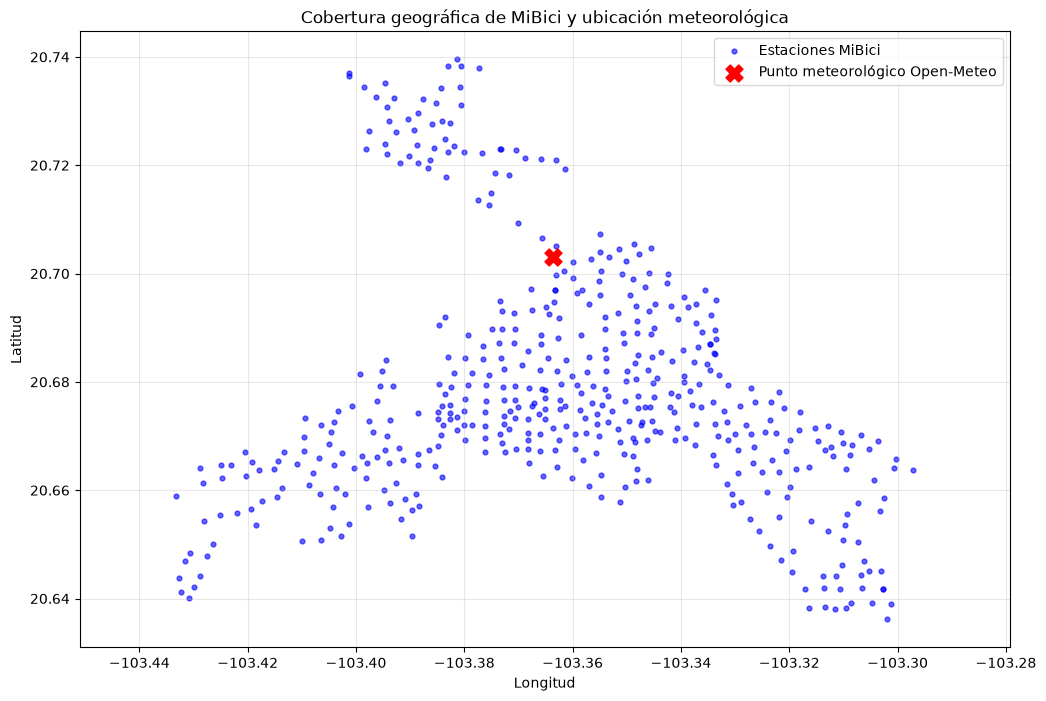

In [377]:
weather_latitude = weather_data["latitude"]
weather_longitude = weather_data["longitude"]

fig, ax = plt.subplots(figsize=(12, 8))

ax.scatter(
    station_coordinates["longitude"],
    station_coordinates["latitude"],
    s=12,
    color="blue",
    alpha=0.6,
    label="Estaciones MiBici"
)

ax.scatter(
    weather_longitude,
    weather_latitude,
    s=150,
    color="red",
    marker="X",
    label="Punto meteorológico Open-Meteo"
)

ax.set_title("Cobertura geográfica de MiBici y ubicación meteorológica")
ax.set_xlabel("Longitud")
ax.set_ylabel("Latitud")
ax.set_aspect("equal", adjustable="datalim")
ax.legend()
ax.grid(alpha=0.3)

plt.show()

In [378]:
print(
    f"https://www.google.com/maps?q="
    f"{weather_latitude},{weather_longitude}"
)

https://www.google.com/maps?q=20.702986,-103.36362


### 5.4 Descarga de datos meteorológicos por zona

Las estaciones de MiBici se agrupan por proximidad geográfica para obtener información meteorológica representativa de las diferentes zonas de Guadalajara y Zapopan.

Para cada grupo se calculan las coordenadas centrales y se consulta Open-Meteo para obtener la temperatura media diaria y la precipitación acumulada entre enero de 2020 y septiembre de 2026.

Los resultados se guardan en un archivo CSV que incluye la fecha y la zona meteorológica. También se conserva la relación entre las estaciones de MiBici y sus respectivas zonas para utilizarla posteriormente en la integración de los datos.

In [379]:
weather_locations = (
    station_coordinates[
        station_coordinates["Origen_Id"].isin(daily_dataset["Origen_Id"])
    ]
    .drop_duplicates(subset="Origen_Id")
    .copy()
)

weather_locations["latitude_zone"] = (
    weather_locations["latitude"] / 0.05
).round() * 0.05

weather_locations["longitude_zone"] = (
    weather_locations["longitude"] / 0.05
).round() * 0.05

weather_locations["weather_zone"] = (
    weather_locations.groupby(
        ["latitude_zone", "longitude_zone"]
    ).ngroup() + 1
)

weather_points = (
    weather_locations
    .groupby("weather_zone", as_index=False)
    .agg(
        latitude=("latitude", "mean"),
        longitude=("longitude", "mean"),
        station_count=("Origen_Id", "count")
    )
)

print("Estaciones consideradas:", len(weather_locations))
print("Zonas meteorológicas:", len(weather_points))

weather_records = []

for zone in weather_points.itertuples(index=False):
    params = {
        "latitude": float(zone.latitude),
        "longitude": float(zone.longitude),
        "start_date": "2020-01-01",
        "end_date": "2026-09-30",
        "daily": "temperature_2m_mean,precipitation_sum",
        "timezone": "America/Mexico_City"
    }

    response = requests.get(
        weather_url,
        params=params,
        timeout=120
    )
    response.raise_for_status()

    weather_result = response.json()
    zone_weather = pd.DataFrame(weather_result["daily"])

    zone_weather["weather_zone"] = zone.weather_zone
    zone_weather["latitude"] = zone.latitude
    zone_weather["longitude"] = zone.longitude

    weather_records.append(zone_weather)

    print(f"Zona {zone.weather_zone}: {len(zone_weather)} días descargados")

weather_dataset = pd.concat(weather_records, ignore_index=True)

weather_dataset = weather_dataset[
    [
        "time",
        "weather_zone",
        "latitude",
        "longitude",
        "temperature_2m_mean",
        "precipitation_sum"
    ]
]

expected_dates = pd.date_range("2020-01-01", "2026-09-30")
expected_rows = len(expected_dates) * len(weather_points)

if len(weather_dataset) != expected_rows:
    raise ValueError("La cantidad de registros meteorológicos no coincide.")

if weather_dataset.isna().any().any():
    raise ValueError("Se encontraron valores faltantes.")

if weather_dataset.duplicated(["time", "weather_zone"]).any():
    raise ValueError("Se encontraron fechas duplicadas por zona.")

weather_dir = config.DATA_DIR / "raw" / "weather"
weather_dir.mkdir(parents=True, exist_ok=True)

weather_path = weather_dir / "weather_daily_zones_2020_2026.csv"
station_zones_path = weather_dir / "mibici_station_weather_zones.csv"


weather_dataset.to_csv(weather_path, index=False)

weather_locations[
    ["Origen_Id", "weather_zone"]
].to_csv(station_zones_path, index=False)

print("\nDescarga completada")
print("Zonas meteorológicas:", len(weather_points))
print("Registros meteorológicos:", len(weather_dataset))
print("Estaciones asignadas:", len(weather_locations))
print("Archivo meteorológico:", weather_path)
print("Relación estaciones-zonas:", station_zones_path)

Estaciones consideradas: 472
Zonas meteorológicas: 8
Zona 1: 2465 días descargados
Zona 2: 2465 días descargados
Zona 3: 2465 días descargados
Zona 4: 2465 días descargados
Zona 5: 2465 días descargados
Zona 6: 2465 días descargados
Zona 7: 2465 días descargados
Zona 8: 2465 días descargados

Descarga completada
Zonas meteorológicas: 8
Registros meteorológicos: 19720
Estaciones asignadas: 472
Archivo meteorológico: /home/josel/mlops/equipo-8-mibici-mlops/data/raw/weather/weather_daily_zones_2020_2026.csv
Relación estaciones-zonas: /home/josel/mlops/equipo-8-mibici-mlops/data/raw/weather/mibici_station_weather_zones.csv


### 5.5 Lugares de interés (POI)

Además de las condiciones meteorológicas, consideramos que los lugares ubicados alrededor de las estaciones de MiBici pueden influir en la demanda de bicicletas.

Para analizar esta relación, utilizaremos información geográfica de OpenStreetMap y consultaremos los puntos de interés (POI) cercanos a cada estación.

Los lugares se clasificarán en las siguientes categorías:

| Categoría | Lugares considerados |
|---|---|
| Educación | Universidades y escuelas |
| Transporte | Estaciones de tren ligero y terminales de autobuses |
| Comercio | Centros comerciales, supermercados y mercados |
| Trabajo | Oficinas y zonas empresariales |
| Salud | Hospitales y clínicas |
| Recreación | Parques, plazas e instalaciones deportivas |

Para cada estación se contabilizará la cantidad de lugares de interés dentro de un radio de búsqueda definido. Estos valores se utilizarán como variables adicionales para evaluar si las características del entorno ayudan a predecir la cantidad de viajes diarios.

Los resultados se almacenarán en un archivo CSV local y se relacionarán con las estaciones mediante `Origen_Id`.

#### 5.5.1 Radio de búsqueda y categorías de lugares de interés (POI)

Para identificar los lugares de interés cercanos a las estaciones de MiBici, se utilizará un radio de búsqueda de 500 metros alrededor de cada estación.

La información se obtendrá de un extracto de OpenStreetMap en formato PBF, que procesaremos localmente. Los lugares se clasificarán en seis categorías: educación, transporte, comercio, trabajo, salud y recreación.

Se utilizarán las etiquetas de OpenStreetMap para identificar los establecimientos y espacios correspondientes a cada categoría. Posteriormente, se contará la cantidad de lugares encontrados alrededor de cada estación.

Una misma ubicación podrá estar dentro del radio de búsqueda de varias estaciones. En estos casos, se considerará para cada estación correspondiente, ya que el objetivo es describir su entorno.

#### 5.5.2 Obtención de datos de lugares de interés (POI)

Para obtener los lugares de interés utilizaremos un extracto de OpenStreetMap en formato PBF y la librería Osmium. Este procesamiento local evita depender de consultas individuales a Overpass API.

Primero descargaremos un extracto geográfico que cubra las estaciones de MiBici. Posteriormente identificaremos los lugares relacionados con educación, transporte, comercio, trabajo, salud y recreación.

Los datos se procesarán localmente para calcular la cantidad de lugares de interés dentro de un radio de 500 metros alrededor de cada estación.

In [380]:
poi_radius = 500

poi_stations = (
    station_coordinates[
        station_coordinates["Origen_Id"].isin(daily_dataset["Origen_Id"])
    ]
    .drop_duplicates(subset="Origen_Id")
    .copy()
)

poi_bbox = [
    poi_stations["longitude"].min() - 0.01,
    poi_stations["latitude"].min() - 0.01,
    poi_stations["longitude"].max() + 0.01,
    poi_stations["latitude"].max() + 0.01
]

print("Estaciones consideradas:", len(poi_stations))
print("Radio de búsqueda:", poi_radius, "metros")
print("Área geográfica:", poi_bbox)

Estaciones consideradas: 472
Radio de búsqueda: 500 metros
Área geográfica: [np.float64(-103.44321500000001), np.float64(20.62613), np.float64(-103.287112), np.float64(20.749523)]


#### 5.5.3 Descarga de datos de OpenStreetMap
Descargaremos un extracto de OpenStreetMap que incluya Guadalajara y Zapopan. Este archivo permitirá obtener los lugares de interés de las seis categorías definidas anteriormente, sin depender de consultas individuales a Overpass API.
Los datos originales se conservarán localmente para facilitar la reproducibilidad del procesamiento.

In [381]:
poi_dir = config.DATA_DIR / "raw" / "pois"
poi_dir.mkdir(parents=True, exist_ok=True)
osm_path = poi_dir / "mexico-latest.osm.pbf"
osm_url = "https://download.geofabrik.de/north-america/mexico-latest.osm.pbf"
try:
    response = requests.head(osm_url, allow_redirects=True, timeout=60)
    response.raise_for_status()
    file_size = int(response.headers.get("Content-Length", 0))
    print("Archivo:", osm_path.name)
    print("Tamaño aproximado:", round(file_size / (1024 ** 3), 2), "GB")
    print("Estado HTTP:", response.status_code)
except requests.exceptions.RequestException as error:
    print("No se pudo consultar Geofabrik:", error)

Archivo: mexico-latest.osm.pbf
Tamaño aproximado: 0.6 GB
Estado HTTP: 200


In [382]:
if osm_path.exists():
    print("El archivo ya existe:", osm_path)
else:
    with requests.get(osm_url, stream=True, timeout=120) as response:
        response.raise_for_status()
        with open(osm_path, "wb") as file:
            for chunk in response.iter_content(chunk_size=1024 * 1024):
                if chunk:
                    file.write(chunk)
    print("Descarga completada:", osm_path)

El archivo ya existe: /home/josel/mlops/equipo-8-mibici-mlops/data/raw/pois/mexico-latest.osm.pbf


#### Limitaciones de los datos de lugares de interés

Una limitación de esta fuente es que los lugares registrados actualmente en OpenStreetMap no necesariamente representan las condiciones que existían durante todo el periodo de análisis (2020–2026).

Algunos establecimientos pudieron abrir, cerrar o cambiar de ubicación durante estos años. Además, no todos los lugares están registrados en OpenStreetMap y la fecha de registro no necesariamente corresponde a la fecha en que comenzaron a operar.

Por esta razón, los lugares de interés se utilizarán como una aproximación a las características del entorno de cada estación, suponiendo que estas se mantienen constantes durante el periodo analizado. Esta consideración puede introducir diferencias respecto a las condiciones históricas reales y deberá tomarse en cuenta al interpretar los resultados del modelo.

#### 5.5.4 Procesamiento de datos de OpenStreetMap
Una vez descargado el archivo de OpenStreetMap, verificaremos que esté disponible y que pueda leerse correctamente.
Posteriormente, utilizaremos las coordenadas de las estaciones de MiBici para identificar los lugares de interés dentro de un radio de 500 metros y clasificarlos en las seis categorías definidas.

In [383]:
if not osm_path.exists():
    raise FileNotFoundError(f"No se encontró el archivo: {osm_path}")
file_size = osm_path.stat().st_size
if file_size == 0:
    raise ValueError("El archivo PBF está vacío.")
print("Archivo:", osm_path.name)
print("Tamaño:", round(file_size / (1024 ** 2), 2), "MB")
print("Verificando lectura del archivo...")
class OSMFileCheck(osmium.SimpleHandler):
    def __init__(self):
        super().__init__()
        self.node_count = 0
    def node(self, node):
        self.node_count += 1
        if self.node_count >= 1000:
            raise StopIteration
file_check = OSMFileCheck()
try:
    file_check.apply_file(str(osm_path))
except StopIteration:
    pass
print("Nodos leídos:", file_check.node_count)

Archivo: mexico-latest.osm.pbf
Tamaño: 618.0 MB
Verificando lectura del archivo...
Nodos leídos: 1000


#### 5.5.5 Extracción de lugares de interés (POI)
A partir del archivo de OpenStreetMap, identificaremos los lugares de interés correspondientes a las seis categorías definidas: educación, transporte, comercio, trabajo, salud y recreación.
Para reducir el procesamiento, seleccionaremos únicamente los elementos ubicados dentro del área geográfica de MiBici, considerando un margen adicional para incluir lugares cercanos a las estaciones.

In [384]:
poi_categories = {
    "education": {
        "amenity": ["school", "university", "college"]
    },
    "transport": {
        "railway": ["station", "tram_stop"],
        "public_transport": ["station"]
    },
    "commerce": {
        "shop": ["supermarket", "mall"],
        "amenity": ["marketplace"]
    },
    "work": {
        "office": None
    },
    "health": {
        "amenity": ["hospital", "clinic"]
    },
    "recreation": {
        "leisure": ["park", "sports_centre", "pitch"]
    }
}
class POIExtractor(osmium.SimpleHandler):
    def __init__(self, bbox, categories):
        super().__init__()
        self.bbox = bbox
        self.categories = categories
        self.records = []
    def node(self, node):
        if not node.location.valid():
            return
        longitude = node.location.lon
        latitude = node.location.lat
        if not (
            self.bbox[0] <= longitude <= self.bbox[2]
            and self.bbox[1] <= latitude <= self.bbox[3]
        ):
            return
        tags = dict(node.tags)
        for category, filters in self.categories.items():
            for key, values in filters.items():
                if key not in tags:
                    continue
                if values is None or tags[key] in values:
                    self.records.append({
                        "osm_id": node.id,
                        "category": category,
                        "name": tags.get("name"),
                        "latitude": latitude,
                        "longitude": longitude
                    })
                    break
poi_extractor = POIExtractor(poi_bbox, poi_categories)
poi_extractor.apply_file(str(osm_path))
poi_nodes = pd.DataFrame(
    poi_extractor.records,
    columns=["osm_id", "category", "name", "latitude", "longitude"]
)
print("POI encontrados:", len(poi_nodes))
print("\nDistribución por categoría:")
print(poi_nodes["category"].value_counts())
display(poi_nodes.head(20))

POI encontrados: 2827

Distribución por categoría:
category
education     1643
work           948
commerce        98
recreation      73
health          57
transport        8
Name: count, dtype: int64


,osm_id,category,name,latitude,longitude
0,566530970,health,Cruz Verde,20.632231,-103.415921
1,638722367,education,Secundaria Tecnica 24,20.736470,-103.366870
2,638722749,education,Cetis 14,20.736038,-103.364885
3,638732607,education,Primaria Felipe Carrillo Puerto,20.737316,-103.369567
4,748110706,commerce,Soriana,20.653531,-103.423925
5,748110712,commerce,Soriana Chapalita,20.666983,-103.404614
6,748110726,commerce,Soriana,20.657406,-103.432992
7,1462697933,recreation,Code I,20.699993,-103.347108
8,1462697957,recreation,Code II,20.701804,-103.349179
9,1462996962,recreation,Complejo Nissan / Estadio Softball,20.644463,-103.369618


#### 5.5.6 Extracción de vías y relaciones
Además de los nodos, OpenStreetMap representa algunos lugares de interés mediante caminos (ways) y relaciones (relations). Estos elementos permiten describir áreas como parques, hospitales, universidades y centros comerciales.
En esta etapa identificaremos los elementos que correspondan a nuestras seis categorías y se encuentren dentro del área de MiBici. Conservaremos su geometría para calcular posteriormente la distancia respecto a cada estación.

In [385]:
class POIAreaExtractor(osmium.SimpleHandler):
    def __init__(self, bbox, categories):
        super().__init__()
        self.bbox = bbox
        self.categories = categories
        self.records = []
    def area(self, area):
        tags = dict(area.tags)
        matched_categories = []
        for category, filters in self.categories.items():
            for key, values in filters.items():
                if key in tags and (values is None or tags[key] in values):
                    matched_categories.append(category)
                    break
        if not matched_categories:
            return
        try:
            geometry = osmium.geom.GeoJSONFactory().create_multipolygon(area)
            polygon = shape(json.loads(geometry))
        except (RuntimeError, ValueError):
            return
        if polygon.is_empty:
            return
        center = polygon.representative_point()
        if not (
            self.bbox[0] <= center.x <= self.bbox[2]
            and self.bbox[1] <= center.y <= self.bbox[3]
        ):
            return
        for category in matched_categories:
            self.records.append({
                "osm_id": area.orig_id(),
                "category": category,
                "name": tags.get("name"),
                "latitude": center.y,
                "longitude": center.x,
                "geometry": polygon
            })
poi_area_extractor = POIAreaExtractor(poi_bbox, poi_categories)
poi_area_extractor.apply_file(
    str(osm_path),
    locations=True,
    idx="flex_mem"
)
poi_areas = pd.DataFrame(poi_area_extractor.records)
print("POI representados como áreas:", len(poi_areas))
print("\nDistribución por categoría:")
print(poi_areas["category"].value_counts())
display(poi_areas.drop(columns="geometry").head(20))

POI representados como áreas: 2465

Distribución por categoría:
category
recreation    1669
education      338
commerce       159
work           122
transport       92
health          85
Name: count, dtype: int64


,osm_id,category,name,latitude,longitude
0,26545973,commerce,MEGA Soriana,20.675566,-103.429078
1,26567675,recreation,NaN,20.676901,-103.336866
2,26567929,recreation,NaN,20.676458,-103.336856
3,43945156,recreation,Unidad Deportiva Paseos del Sol,20.635079,-103.431814
4,65833707,recreation,Parque Morelos,20.680227,-103.340584
5,96462837,commerce,Plaza México,20.679636,-103.399282
6,96880872,commerce,Galerías Guadalajara,20.676899,-103.432026
7,101802883,recreation,NaN,20.693804,-103.416153
8,101803577,recreation,Estadio de Sóftbol Miguel Sotomayor,20.695596,-103.416586
9,101803877,recreation,NaN,20.695233,-103.418207


#### Clasificación de lugares de interés y nombres faltantes
Durante la extracción encontramos lugares de interés que no tienen un nombre registrado en OpenStreetMap. Sin embargo, esto no impide clasificarlos, ya que utilizamos las etiquetas (tags) asociadas a cada elemento y no su nombre.
Por ejemplo, un lugar identificado con `leisure=park` se clasifica como recreación, aunque el campo `name` esté vacío (`NaN`).
Por esta razón, conservaremos los registros sin nombre siempre que tengan una etiqueta válida dentro de nuestras seis categorías. No obstante, debemos considerar que la información de OpenStreetMap puede estar incompleta o desactualizada, lo que podría afectar los conteos de lugares cercanos a cada estación.

#### 5.5.7 Integración y validación de lugares de interés
Una vez extraídos los lugares de interés representados como nodos y áreas, integraremos ambos conjuntos de datos para revisar su distribución y detectar posibles registros duplicados.
La validación se realizará utilizando el tipo de elemento, su identificador de OpenStreetMap y la categoría asignada. Esto permitirá evitar que un mismo elemento se contabilice más de una vez dentro de una categoría.

In [386]:
poi_nodes_clean = poi_nodes.copy()
poi_nodes_clean["osm_type"] = "node"
poi_areas_clean = poi_areas.copy()
poi_areas_clean["osm_type"] = "area"
poi_combined = pd.concat(
    [poi_nodes_clean, poi_areas_clean],
    ignore_index=True
)
duplicate_columns = ["osm_type", "osm_id", "category"]
duplicate_count = poi_combined.duplicated(
    subset=duplicate_columns
).sum()
print("POI de nodos:", len(poi_nodes_clean))
print("POI de áreas:", len(poi_areas_clean))
print("Total combinado:", len(poi_combined))
print("Registros duplicados:", duplicate_count)
print("\nDistribución por categoría:")
print(poi_combined["category"].value_counts())

POI de nodos: 2827
POI de áreas: 2465
Total combinado: 5292
Registros duplicados: 0

Distribución por categoría:
category
education     1981
recreation    1742
work          1070
commerce       257
health         142
transport      100
Name: count, dtype: int64


#### 5.5.8 Análisis de proximidad de lugares de interés
Para cada estación de MiBici calcularemos la cantidad de lugares de interés ubicados dentro de un radio de 500 metros.
Utilizaremos el sistema de coordenadas UTM zona 13N (EPSG:32613) para calcular las distancias en metros. En el caso de los lugares representados como polígonos, consideraremos su geometría completa y no solamente su punto central.
Los resultados se organizarán por estación y categoría para generar posteriormente el archivo CSV que utilizaremos en el modelo.

In [387]:
coordinate_transformer = Transformer.from_crs(
    "EPSG:4326",
    "EPSG:32613",
    always_xy=True
)
poi_geometries = []
for poi in poi_combined.itertuples(index=False):
    if poi.osm_type == "area":
        geometry = poi.geometry
    else:
        geometry = Point(poi.longitude, poi.latitude)
    poi_geometries.append(
        transform(coordinate_transformer.transform, geometry)
    )
poi_projected = poi_combined.copy()
poi_projected["geometry_meters"] = None
for index, geometry in enumerate(poi_geometries):
    poi_projected.at[index, "geometry_meters"] = geometry
poi_counts = []
for station in poi_stations.itertuples(index=False):
    station_x, station_y = coordinate_transformer.transform(
        station.longitude,
        station.latitude
    )
    station_point = Point(station_x, station_y)
    nearby_pois = poi_projected[
        poi_projected["geometry_meters"].apply(
            lambda geometry: station_point.distance(geometry) <= poi_radius
        )
    ]
    category_counts = nearby_pois["category"].value_counts()
    station_counts = {"Origen_Id": station.Origen_Id}
    for category in poi_categories:
        station_counts[f"{category}_count"] = int(
            category_counts.get(category, 0)
        )
    poi_counts.append(station_counts)
station_poi_dataset = pd.DataFrame(poi_counts)
print("Estaciones procesadas:", len(station_poi_dataset))
print("Radio de búsqueda:", poi_radius, "metros")
print("\nTotal de POI cercanos por categoría:")
print(station_poi_dataset.drop(columns="Origen_Id").sum())
display(station_poi_dataset.head(200))

/tmp/ipykernel_2495/2169155501.py:13: DeprecationWarning: The 'shapely.ops.transform()' function is deprecated. Use 'shapely.transform()' or 'shapely.transform_coordseq()' instead. See https://shapely.readthedocs.io/en/latest/manual.html#shapely.ops.transform for more details.
  transform(coordinate_transformer.transform, geometry)


Estaciones procesadas: 472
Radio de búsqueda: 500 metros

Total de POI cercanos por categoría:
education_count     5891
transport_count      334
commerce_count       661
work_count          6702
health_count         601
recreation_count    3358
dtype: int64


,Origen_Id,education_count,transport_count,commerce_count,work_count,health_count,recreation_count
0,2,24,4,0,49,7,6
1,3,9,0,1,23,2,2
2,4,11,0,1,52,2,1
3,5,2,0,0,3,0,13
4,6,34,3,4,13,2,8
...,...,...,...,...,...,...,...
195,213,6,1,0,6,0,6
196,214,8,1,0,11,0,5
197,215,11,1,0,9,0,7
198,216,9,1,0,11,0,2


#### 5.5.9 Validación y exportación de lugares de interés a CSV
Después de calcular los lugares de interés cercanos a cada estación, verificaremos que los identificadores coincidan con los utilizados en nuestro conjunto de datos, que no existan registros duplicados ni valores faltantes y que los conteos sean válidos.
Los resultados se guardarán en un archivo CSV local para utilizarlos posteriormente como variables del modelo. El archivo conservará el mismo nombre y se actualizará cuando se ejecute nuevamente esta celda.

In [388]:
expected_ids = set(daily_dataset["Origen_Id"])
if set(station_poi_dataset["Origen_Id"]) != expected_ids:
    raise ValueError("Los identificadores no coinciden.")
if station_poi_dataset["Origen_Id"].duplicated().any():
    raise ValueError("Hay estaciones duplicadas.")
if station_poi_dataset.isna().any().any():
    raise ValueError("Hay valores faltantes.")
count_columns = station_poi_dataset.columns.drop("Origen_Id")
if (station_poi_dataset[count_columns] < 0).any().any():
    raise ValueError("Hay conteos negativos.")
if not all(pd.api.types.is_integer_dtype(station_poi_dataset[col]) for col in count_columns):
    raise ValueError("Hay conteos que no son enteros.")
poi_csv_path = poi_dir / "mibici_station_pois.csv"
station_poi_dataset.to_csv(poi_csv_path, index=False)
print("CSV guardado:", poi_csv_path)

CSV guardado: /home/josel/mlops/equipo-8-mibici-mlops/data/raw/pois/mibici_station_pois.csv


## 6. Exportación de datos
En esta sección guardaremos primero la demanda diaria procesada de MiBici en formato Parquet. Este archivo será la base para incorporar posteriormente las variables meteorológicas y los lugares de interés.
### 6.1 Datos base de MiBici
Guardaremos los viajes diarios procesados antes de incorporar las variables externas. Si el archivo ya existe, se actualizará utilizando el mismo nombre.

In [389]:
processed_dir = config.DATA_DIR / "processed"
processed_dir.mkdir(parents=True, exist_ok=True)
base_path = processed_dir / "mibici_daily.parquet"
daily_dataset.to_parquet(base_path, index=False)
print("Parquet base guardado:", base_path)
print("Dimensiones:", daily_dataset.shape)

Parquet base guardado: /home/josel/mlops/equipo-8-mibici-mlops/data/processed/mibici_daily.parquet
Dimensiones: (799264, 5)


## 7. Integración de datos
En esta sección incorporaremos los datos meteorológicos y los lugares de interés al Parquet base de MiBici. Las fuentes externas se leerán desde sus archivos CSV locales. De esta manera, no será necesario volver a procesar los CSV históricos de viajes para actualizar la integración.
### 7.1 Carga de datos externos
Cargaremos los datos meteorológicos diarios por zona, la relación entre estaciones y zonas meteorológicas, y los conteos de lugares de interés por estación. También leeremos el Parquet base generado en la sección anterior.

**Orden del flujo:** primero leemos los archivos y validamos sus columnas. Después `integrate_daily_sources()` realiza todas las uniones en una sola ejecución. La imputación y la codificación que dependan del entrenamiento deben permanecer dentro de `Pipeline`/`ColumnTransformer` durante la validación temporal.

In [390]:
weather_dir = config.DATA_DIR / "raw" / "weather"
poi_dir = config.DATA_DIR / "raw" / "pois"
weather_dataset = pd.read_csv(
    weather_dir / "weather_daily_zones_2020_2026.csv",
    parse_dates=["time"]
)
station_weather_zones = pd.read_csv(
    weather_dir / "mibici_station_weather_zones.csv"
)
station_poi_dataset = pd.read_csv(
    poi_dir / "mibici_station_pois.csv"
)
integrated_dataset = pd.read_parquet(base_path)
print("Parquet base:", integrated_dataset.shape)
print("Datos meteorológicos:", weather_dataset.shape)
print("Zonas por estación:", station_weather_zones.shape)
print("POI por estación:", station_poi_dataset.shape)

Parquet base: (799264, 5)
Datos meteorológicos: (19720, 6)
Zonas por estación: (472, 2)
POI por estación: (472, 7)


### 7.2 Integración de datos meteorológicos
Integraremos los datos meteorológicos con los viajes diarios utilizando la zona asignada a cada estación y la fecha del registro. Primero agregaremos el identificador de la zona meteorológica mediante `Origen_Id`. Después incorporaremos la temperatura promedio y la precipitación diaria utilizando `Fecha` y `weather_zone`.

#### Pipeline de integración de fuentes
La integración de clima y puntos de interés se realiza con una función que recibe los datos ya leídos. Mantenemos las mismas uniones y las mismas columnas del notebook original para poder comparar los resultados sin cambiar el experimento. Los datos meteorológicos observados y los POI actuales siguen siendo una limitación para un pronóstico anticipado.

In [391]:
def integrate_daily_sources(daily_data, weather_data, weather_zones, poi_data):
    integrated = daily_data.copy()
    integrated["Fecha"] = pd.to_datetime(integrated["Fecha"])
    integrated = integrated.merge(
        weather_zones, on="Origen_Id", how="left", validate="many_to_one"
    )
    integrated = integrated.merge(
        weather_data[["time", "weather_zone", "temperature_2m_mean", "precipitation_sum"]],
        left_on=["Fecha", "weather_zone"],
        right_on=["time", "weather_zone"],
        how="left",
        validate="many_to_one"
    )
    integrated = integrated.drop(columns=["time"])
    integrated = integrated.merge(
        poi_data, on="Origen_Id", how="left", validate="many_to_one"
    )
    return integrated

In [392]:
integrated_dataset = integrate_daily_sources(
    integrated_dataset, weather_dataset, station_weather_zones, station_poi_dataset
)
print("Registros integrados:", len(integrated_dataset))
print("Valores faltantes en clima:")
print(integrated_dataset[["weather_zone", "temperature_2m_mean", "precipitation_sum"]].isna().sum())

Registros integrados: 799264
Valores faltantes en clima:
weather_zone           0
temperature_2m_mean    0
precipitation_sum      0
dtype: int64


### 7.3 Integración de lugares de interés
Integraremos los conteos de lugares de interés cercanos a cada estación utilizando `Origen_Id`. Estos datos representan la cantidad de lugares dentro de un radio de 500 metros, clasificados en seis categorías: educación, transporte, comercio, trabajo, salud y recreación.

In [393]:
poi_columns = [
    "education_count",
    "transport_count",
    "commerce_count",
    "work_count",
    "health_count",
    "recreation_count"
]
print("Registros integrados:", len(integrated_dataset))
print("Columnas:", integrated_dataset.shape[1])
print("Valores faltantes en POI:")
print(integrated_dataset[poi_columns].isna().sum())

Registros integrados: 799264
Columnas: 14
Valores faltantes en POI:
education_count     0
transport_count     0
commerce_count      0
work_count          0
health_count        0
recreation_count    0
dtype: int64


### 7.4 Validación de datos integrados
Comprobaremos que el conjunto integrado conserve la cantidad de registros del Parquet base, que no existan duplicados por estación y fecha y que todas las variables tengan información.

In [394]:
assert len(integrated_dataset) == len(daily_dataset)
assert not integrated_dataset.duplicated(["Origen_Id", "Fecha"]).any()
assert not integrated_dataset.isna().any().any()
print("Validación completada correctamente.")
print("Dimensiones:", integrated_dataset.shape)

Validación completada correctamente.
Dimensiones: (799264, 14)


### 7.5 Exportación de datos integrados
Guardaremos el conjunto integrado en un segundo archivo Parquet, independiente del dataset base. Este archivo incluirá los viajes diarios, las variables meteorológicas y los conteos de lugares de interés. Si ya existe, se actualizará con los mismos datos y conservará el mismo nombre.

In [395]:
integrated_path = processed_dir / "mibici_integrated.parquet"
integrated_dataset.to_parquet(integrated_path, index=False)
print("Parquet integrado guardado:", integrated_path)
print("Dimensiones:", integrated_dataset.shape)

Parquet integrado guardado: /home/josel/mlops/equipo-8-mibici-mlops/data/processed/mibici_integrated.parquet
Dimensiones: (799264, 14)


## 8. Contrato de datos
### 8.1 Definición del contrato
En esta sección definimos las reglas que debe cumplir `mibici_integrated.parquet` antes de utilizarlo en el EDA y el entrenamiento. Revisaremos las columnas, los tipos de datos, los valores faltantes y los registros duplicados.

La idea es utilizar estas mismas reglas cuando incorporemos nuevos datos de MiBici, para verificar que sean compatibles con los que ya tenemos.

### 8.2 Carga y revisión de los datos
Cargamos el archivo `mibici_integrated.parquet` para revisar las columnas y sus tipos de datos antes de definir las validaciones del contrato.

In [396]:
contract_dataset = pd.read_parquet(
    config.DATA_DIR / "processed" / "mibici_integrated.parquet"
)
print("Dimensiones:", contract_dataset.shape)
print("\nColumnas y tipos de datos:")
print(contract_dataset.dtypes)

Dimensiones: (799264, 14)

Columnas y tipos de datos:
Origen_Id                       int64
Fecha                  datetime64[us]
target                          int64
day_of_week                     int32
month                           int32
weather_zone                    int64
temperature_2m_mean           float64
precipitation_sum             float64
education_count                 int64
transport_count                 int64
commerce_count                  int64
work_count                      int64
health_count                    int64
recreation_count                int64
dtype: object


### 8.3 Contrato de datos
Para el conjunto `mibici_integrated.parquet` definimos las siguientes reglas. Las utilizaremos para revisar los datos actuales y validar nuevos registros antes de incorporarlos al pipeline.

| Columna | Tipo de dato | Regla |
|---|---|---|
| `Origen_Id` | int64 | Identificador de estación, no nulo |
| `Fecha` | datetime64[us] | Fecha válida, no nula |
| `target` | int64 | Número de viajes mayor o igual a 0 |
| `day_of_week` | int32 | Valores de 0 a 6 |
| `month` | int32 | Valores de 1 a 12 |
| `weather_zone` | int64 | Identificador de zona meteorológica, no nulo |
| `temperature_2m_mean` | float64 | Temperatura numérica, no nula |
| `precipitation_sum` | float64 | Precipitación mayor o igual a 0 |
| `education_count` | int64 | Conteo mayor o igual a 0 |
| `transport_count` | int64 | Conteo mayor o igual a 0 |
| `commerce_count` | int64 | Conteo mayor o igual a 0 |
| `work_count` | int64 | Conteo mayor o igual a 0 |
| `health_count` | int64 | Conteo mayor o igual a 0 |
| `recreation_count` | int64 | Conteo mayor o igual a 0 |

También verificaremos que no existan valores faltantes, columnas adicionales ni registros repetidos para una misma combinación de `Origen_Id` y `Fecha`.

In [397]:
expected_columns = {
    "Origen_Id": "int64",
    "Fecha": "datetime64[us]",
    "target": "int64",
    "day_of_week": "int32",
    "month": "int32",
    "weather_zone": "int64",
    "temperature_2m_mean": "float64",
    "precipitation_sum": "float64",
    "education_count": "int64",
    "transport_count": "int64",
    "commerce_count": "int64",
    "work_count": "int64",
    "health_count": "int64",
    "recreation_count": "int64"
}
assert set(contract_dataset.columns) == set(expected_columns)
for column, expected_type in expected_columns.items():
    assert str(contract_dataset[column].dtype) == expected_type, column
assert not contract_dataset.isna().any().any()
assert not contract_dataset.duplicated(["Origen_Id", "Fecha"]).any()
assert (contract_dataset["target"] >= 0).all()
assert contract_dataset["day_of_week"].between(0, 6).all()
assert contract_dataset["month"].between(1, 12).all()
assert (contract_dataset["precipitation_sum"] >= 0).all()
poi_columns = [
    "education_count",
    "transport_count",
    "commerce_count",
    "work_count",
    "health_count",
    "recreation_count"
]
assert (contract_dataset[poi_columns] >= 0).all().all()
print("Contrato de datos validado correctamente.")

Contrato de datos validado correctamente.


### 8.4 Comprobación de equivalencia del pipeline de datos
Comprobamos que la preparación integrada conserva la cantidad de viajes, las fechas y las estaciones de la demanda diaria original. También verificamos que las uniones no dupliquen filas. Estas comprobaciones validan la estructura, pero no sustituyen una ejecución completa ni demuestran por sí solas que las métricas del modelo sean idénticas.

In [398]:
assert len(contract_dataset) == len(daily_dataset)
assert contract_dataset["target"].sum() == daily_dataset["target"].sum()
assert not contract_dataset.duplicated(["Origen_Id", "Fecha"]).any()
assert contract_dataset[["Origen_Id", "Fecha", "target"]].equals(
    daily_dataset[["Origen_Id", "Fecha", "target"]]
)
print("Registros y demanda conservados después de integrar las fuentes.")

Registros y demanda conservados después de integrar las fuentes.


### 8.4 Estructura y significado del dataset integrado
En la Fase 1 trabajamos principalmente en la limpieza y exploración de los viajes. En esta segunda fase necesitamos comprobar que la tabla final sea adecuada para entrenar modelos reproducibles.
Cada fila representa una **estación y una fecha con viajes registrados**. `target` indica cuántos viajes comenzaron en esa estación ese día. Esto no equivale a tener todos los días operativos: las fechas sin registros no aparecen como filas.
Las columnas se organizan así:
- **Identificación:** `Origen_Id`, `Fecha`.
- **Objetivo:** `target`.
- **Calendario conocido de antemano:** `day_of_week`, `month`.
- **Zona y clima histórico:** `weather_zone`, `temperature_2m_mean`, `precipitation_sum`.
- **Entorno de la estación:** seis conteos de POI dentro del radio definido en la integración.
Esta clasificación nos ayudará a separar las variables disponibles al predecir de las que solo conocemos después de que ocurra el día.

In [399]:
column_roles = {
    "Origen_Id": "Identificador",
    "Fecha": "Fecha",
    "target": "Objetivo",
    "day_of_week": "Calendario",
    "month": "Calendario",
    "weather_zone": "Zona meteorológica",
    "temperature_2m_mean": "Clima histórico",
    "precipitation_sum": "Clima histórico",
    "education_count": "POI",
    "transport_count": "POI",
    "commerce_count": "POI",
    "work_count": "POI",
    "health_count": "POI",
    "recreation_count": "POI"
}
dataset_structure = pd.DataFrame({
    "role": pd.Series(column_roles),
    "dtype": contract_dataset.dtypes.astype(str),
    "missing": contract_dataset.isna().sum()
})
print("Dimensiones:", contract_dataset.shape)
print("Estaciones:", contract_dataset["Origen_Id"].nunique())
print("Periodo:", contract_dataset["Fecha"].min().date(), "a", contract_dataset["Fecha"].max().date())
print("Clave estación-fecha única:", not contract_dataset.duplicated(["Origen_Id", "Fecha"]).any())
print(dataset_structure.to_string())

Dimensiones: (799264, 14)
Estaciones: 472
Periodo: 2020-01-01 a 2026-09-30
Clave estación-fecha única: True
                                   role           dtype  missing
Origen_Id                 Identificador           int64        0
Fecha                             Fecha  datetime64[us]        0
target                         Objetivo           int64        0
day_of_week                  Calendario           int32        0
month                        Calendario           int32        0
weather_zone         Zona meteorológica           int64        0
temperature_2m_mean     Clima histórico         float64        0
precipitation_sum       Clima histórico         float64        0
education_count                     POI           int64        0
transport_count                     POI           int64        0
commerce_count                      POI           int64        0
work_count                          POI           int64        0
health_count                        POI        

### 8.5 Pruebas de calidad T1–T9
En la Fase 1 definimos controles de calidad. Aquí los reunimos en una tabla de resultados para verificar el dataset final antes de analizar las variables y entrenar. Las pruebas distinguen errores comprobables de posibles valores extremos que requieren interpretación.
T1: esquema; T2: tipos; T3: cadenas vacías; T4: valores inválidos; T5: nulos; T6: rangos; T7: consistencia de fechas; T8: duplicados; T9: variable objetivo. Los criterios de límites físicos extremos se revisan por separado, sin descartar registros automáticamente.

In [400]:
poi_columns = [
    "education_count", "transport_count", "commerce_count",
    "work_count", "health_count", "recreation_count"
]
expected_columns = {
    "Origen_Id": "int64", "Fecha": "datetime64[us]", "target": "int64",
    "day_of_week": "int32", "month": "int32", "weather_zone": "int64",
    "temperature_2m_mean": "float64", "precipitation_sum": "float64",
    **{column: "int64" for column in poi_columns}
}
empty_text_count = sum(
    contract_dataset[column].astype(str).str.strip().eq("").sum()
    for column in contract_dataset.select_dtypes(include="object").columns
)
quality_checks = {
    "T1 - Esquema": set(contract_dataset.columns) == set(expected_columns),
    "T2 - Tipos": all(
        str(contract_dataset[column].dtype) == expected_type
        for column, expected_type in expected_columns.items()
    ),
    "T3 - Textos vacíos": empty_text_count == 0,
    "T4 - Valores inválidos": (
        (contract_dataset["Origen_Id"] > 0).all()
        and (contract_dataset["weather_zone"] >= 0).all()
        and (contract_dataset[poi_columns] >= 0).all().all()
    ),
    "T5 - Nulos": not contract_dataset.isna().any().any(),
    "T6 - Rangos": (
        contract_dataset["day_of_week"].between(0, 6).all()
        and contract_dataset["month"].between(1, 12).all()
        and (contract_dataset["precipitation_sum"] >= 0).all()
    ),
    "T7 - Fechas consistentes": (
        contract_dataset["Fecha"].dt.dayofweek.eq(contract_dataset["day_of_week"]).all()
        and contract_dataset["Fecha"].dt.month.eq(contract_dataset["month"]).all()
    ),
    "T8 - Duplicados": not contract_dataset.duplicated(["Origen_Id", "Fecha"]).any(),
    "T9 - Objetivo": (
        (contract_dataset["target"] >= 0).all()
        and pd.api.types.is_integer_dtype(contract_dataset["target"])
    )
}
quality_results = pd.DataFrame({
    "test": list(quality_checks),
    "passed": list(quality_checks.values())
})
print(quality_results.to_string(index=False))
print("Pruebas aprobadas:", int(quality_results["passed"].sum()), "de", len(quality_results))

                    test  passed
            T1 - Esquema    True
              T2 - Tipos    True
      T3 - Textos vacíos    True
  T4 - Valores inválidos    True
              T5 - Nulos    True
             T6 - Rangos    True
T7 - Fechas consistentes    True
         T8 - Duplicados    True
           T9 - Objetivo    True
Pruebas aprobadas: 9 de 9


#### 8.5.1 Revisión de nulos y tipos de datos
Antes de continuar con las pruebas específicas, revisamos los valores faltantes y tipos de datos de todas las columnas.

In [401]:
missing_summary = pd.DataFrame({
    "dtype": integrated_dataset.dtypes.astype(str),
    "missing_count": integrated_dataset.isna().sum(),
    "missing_percent": (
        integrated_dataset.isna().mean() * 100
    ).round(2)
})
print(missing_summary.to_string())

                              dtype  missing_count  missing_percent
Origen_Id                     int64              0              0.0
Fecha                datetime64[us]              0              0.0
target                        int64              0              0.0
day_of_week                   int32              0              0.0
month                         int32              0              0.0
weather_zone                  int64              0              0.0
temperature_2m_mean         float64              0              0.0
precipitation_sum           float64              0              0.0
education_count               int64              0              0.0
transport_count               int64              0              0.0
commerce_count                int64              0              0.0
work_count                    int64              0              0.0
health_count                  int64              0              0.0
recreation_count              int64             

**Hallazgos:**
- Se revisaron las 14 columnas del dataset integrado y no se encontraron valores nulos.
- Las variables de temperatura, precipitación y POI presentan un 0 % de valores faltantes.
- Los tipos de datos son consistentes con las variables analizadas.
- Los 6,144 días sin registros identificados anteriormente no aparecen en esta revisión, ya que corresponden a fechas sin observaciones y no a valores nulos.
- Por ahora no es necesario imputar valores nulos. Continuaremos revisando rangos, valores inválidos y posibles valores atípicos antes de utilizar estas variables en los modelos.

### 8.6 Faltantes, ceros y cobertura de variables
Un valor nulo, un valor cero y una fecha sin fila significan cosas diferentes. Revisamos los nulos de todas las columnas y los ceros en las variables numéricas. Un cero en POI puede ser válido; un cero en precipitación indica ausencia de lluvia registrada. Las fechas sin fila se analizaron en el apartado de continuidad temporal.

In [402]:
missing_summary = pd.DataFrame({
    "dtype": contract_dataset.dtypes.astype(str),
    "missing_count": contract_dataset.isna().sum(),
    "missing_percent": (contract_dataset.isna().mean() * 100).round(2)
})
print(missing_summary.to_string())
zero_columns = ["target", "precipitation_sum"] + poi_columns
zero_summary = pd.DataFrame({
    "zero_count": contract_dataset[zero_columns].eq(0).sum(),
    "zero_percent": (contract_dataset[zero_columns].eq(0).mean() * 100).round(2)
})
print("\nValores cero por variable:")
print(zero_summary.to_string())

                              dtype  missing_count  missing_percent
Origen_Id                     int64              0              0.0
Fecha                datetime64[us]              0              0.0
target                        int64              0              0.0
day_of_week                   int32              0              0.0
month                         int32              0              0.0
weather_zone                  int64              0              0.0
temperature_2m_mean         float64              0              0.0
precipitation_sum           float64              0              0.0
education_count               int64              0              0.0
transport_count               int64              0              0.0
commerce_count                int64              0              0.0
work_count                    int64              0              0.0
health_count                  int64              0              0.0
recreation_count              int64             

### 8.7 Rangos y valores extremos de clima y POI
Calculamos mínimos, percentiles y máximos. Los valores altos no se eliminan automáticamente: primero debemos determinar si son plausibles o si reflejan errores de las fuentes. La temperatura puede ser negativa; la precipitación y los conteos de POI no deberían serlo.

In [403]:
external_columns = [
    "temperature_2m_mean", "precipitation_sum"
] + poi_columns
external_summary = contract_dataset[external_columns].describe(
    percentiles=[0.01, 0.25, 0.5, 0.75, 0.95, 0.99]
).T.round(2)
print(external_summary.to_string())
print("\nValores negativos:")
print((contract_dataset[external_columns] < 0).sum().to_string())

                        count   mean    std   min    1%   25%   50%   75%   95%   99%   max
temperature_2m_mean  799264.0  21.02   2.66  11.0  15.0  19.5  20.9  22.6  25.7  27.4  29.0
precipitation_sum    799264.0   1.99   4.44   0.0   0.0   0.0   0.0   1.4  11.9  21.3  37.6
education_count      799264.0  13.53   8.92   1.0   1.0   6.0  11.0  20.0  29.0  35.0  44.0
transport_count      799264.0   0.77   1.04   0.0   0.0   0.0   0.0   1.0   3.0   4.0   5.0
commerce_count       799264.0   1.50   1.51   0.0   0.0   0.0   1.0   2.0   5.0   6.0   8.0
work_count           799264.0  17.32  18.51   0.0   0.0   3.0   9.0  27.0  57.0  67.0  79.0
health_count         799264.0   1.43   2.61   0.0   0.0   0.0   1.0   2.0   3.0  20.0  25.0
recreation_count     799264.0   7.01   5.89   0.0   0.0   3.0   5.0  10.0  18.0  29.0  38.0

Valores negativos:
temperature_2m_mean    0
precipitation_sum      0
education_count        0
transport_count        0
commerce_count         0
work_count             0
he

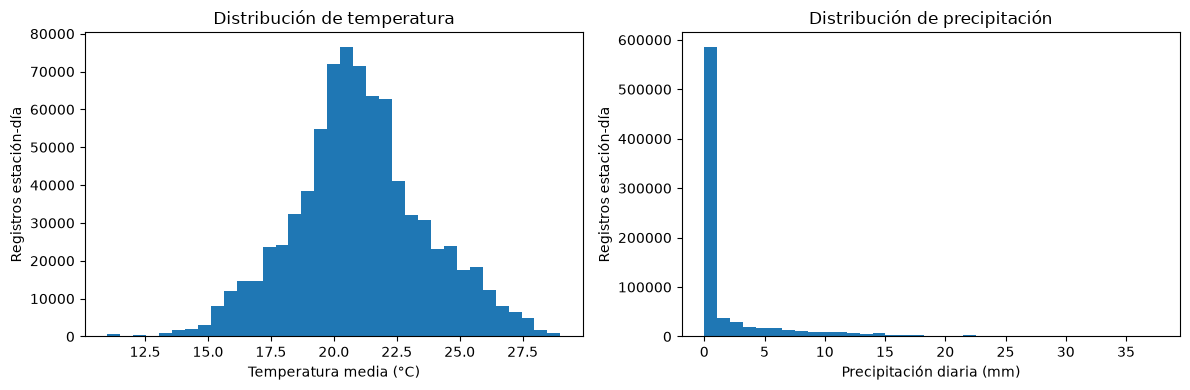

In [404]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].hist(contract_dataset["temperature_2m_mean"], bins=35)
axes[0].set_title("Distribución de temperatura")
axes[0].set_xlabel("Temperatura media (°C)")
axes[0].set_ylabel("Registros estación-día")
axes[1].hist(contract_dataset["precipitation_sum"], bins=35)
axes[1].set_title("Distribución de precipitación")
axes[1].set_xlabel("Precipitación diaria (mm)")
axes[1].set_ylabel("Registros estación-día")
plt.tight_layout()
plt.show()

### 8.8 Consistencia de los POI y de la zona meteorológica por estación
Los POI y la zona meteorológica se asignaron a cada estación. Verificamos que una estación no tenga diferentes conteos de POI o zonas dentro de la tabla integrada. También revisamos la cobertura por año, ya que los datos disponibles no incluyen necesariamente todos los días operativos de cada estación.

Estaciones con atributos variables: 0

Cobertura por año:
      records  stations    trips
year                            
2020    99224       275  2866065
2021   105253       300  3184410
2022   109093       300  4202942
2023   112295       359  4293115
2024   131390       370  4645921
2025   133715       371  4532032
2026   108294       469  3357353


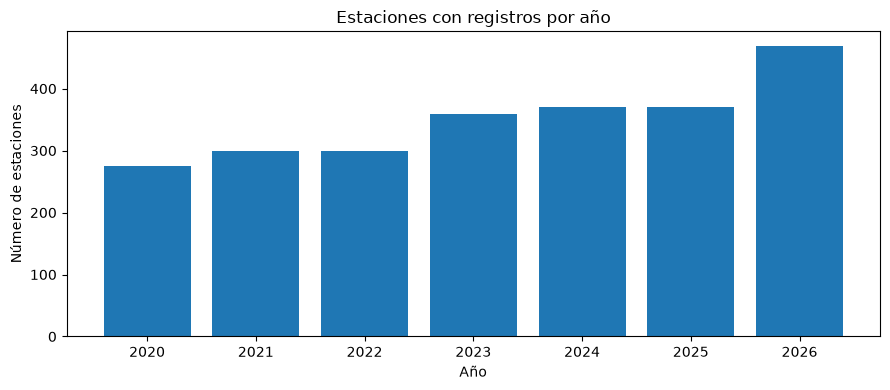

In [405]:
station_attributes = ["weather_zone"] + poi_columns
attribute_changes = contract_dataset.groupby("Origen_Id")[station_attributes].nunique()
inconsistent_stations = attribute_changes.gt(1).any(axis=1)
print("Estaciones con atributos variables:", int(inconsistent_stations.sum()))
coverage_by_year = (
    contract_dataset.assign(year=contract_dataset["Fecha"].dt.year)
    .groupby("year")
    .agg(records=("target", "size"), stations=("Origen_Id", "nunique"), trips=("target", "sum"))
)
print("\nCobertura por año:")
print(coverage_by_year.to_string())
fig, ax = plt.subplots(figsize=(9, 4))
ax.bar(coverage_by_year.index.astype(str), coverage_by_year["stations"])
ax.set_title("Estaciones con registros por año")
ax.set_xlabel("Año")
ax.set_ylabel("Número de estaciones")
plt.tight_layout()
plt.show()

**Interpretación de calidad:**
- Las pruebas anteriores verifican reglas del dataset integrado; los valores extremos deben interpretarse con los resultados obtenidos.
- No se rellenan fechas sin registros ni se eliminan estaciones automáticamente.
- La ausencia de nulos en el dataset integrado no demuestra que las fuentes externas sean históricamente completas.
- Los POI reflejan la información de OpenStreetMap utilizada al extraerlos; no necesariamente describen la situación de cada año del periodo histórico.

### Punto de revisión: ejecutar hasta aquí
Ejecuta las secciones 1 a 8 en orden y comparte las tablas y gráficas de calidad. Las secciones 9 y 10 se conservan completas para continuar después de revisar los resultados. No se deben interpretar los días sin registros como viajes iguales a cero.

## 9. Análisis exploratorio de datos (EDA)
### 9.1 Distribución de viajes diarios por estación
Analizamos la distribución de `target` para conocer cómo varía el número de viajes diarios entre estaciones e identificar posibles valores extremos.

In [406]:
print("Estadísticas de viajes diarios por estación:")
print(contract_dataset["target"].describe())
print("Registros sin viajes:", (contract_dataset["target"] == 0).sum())

Estadísticas de viajes diarios por estación:
count    799264.000000
mean         33.883470
std          33.729078
min           1.000000
25%          12.000000
50%          24.000000
75%          45.000000
max         561.000000
Name: target, dtype: float64
Registros sin viajes: 0


### 9.2 Distribución de la demanda
Visualizamos la distribución de viajes diarios para identificar dónde se concentra la mayor parte de los registros y observar los valores más altos de demanda.

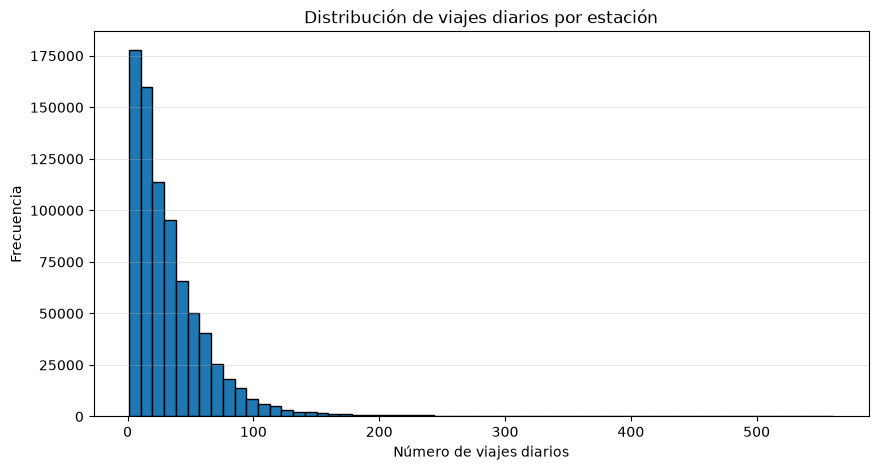

In [407]:
plt.figure(figsize=(10, 5))
plt.hist(contract_dataset["target"], bins=60, edgecolor="black")
plt.title("Distribución de viajes diarios por estación")
plt.xlabel("Número de viajes diarios")
plt.ylabel("Frecuencia")
plt.grid(axis="y", alpha=0.3)
plt.show()

### 9.3 Revisión de fechas por estación
Revisamos cuántos días aparecen registrados por estación para identificar posibles fechas faltantes. Esto nos ayudará a determinar si el conjunto diario incluye los días sin viajes.

In [408]:
station_days = contract_dataset.groupby("Origen_Id")["Fecha"].agg(
    ["min", "max", "nunique"]
)
station_days["expected_days"] = (
    station_days["max"] - station_days["min"]
).dt.days + 1
station_days["missing_days"] = (
    station_days["expected_days"] - station_days["nunique"]
)
print("Estaciones con fechas faltantes:")
print((station_days["missing_days"] > 0).sum())
print("Total de fechas faltantes:", station_days["missing_days"].sum())
print(station_days["missing_days"].describe())

Estaciones con fechas faltantes:
301
Total de fechas faltantes: 6144
count    472.000000
mean      13.016949
std       53.843168
min        0.000000
25%        0.000000
50%        2.000000
75%        8.000000
max      904.000000
Name: missing_days, dtype: float64


### 9.4 Análisis de periodos sin registros
Revisamos los periodos consecutivos sin registros entre la primera y última fecha de cada estación. Esto nos permitirá identificar si las fechas faltantes corresponden principalmente a días aislados o a periodos largos que podrían estar relacionados con interrupciones del servicio.

In [409]:
station_dates = contract_dataset[["Origen_Id", "Fecha"]].sort_values(
    ["Origen_Id", "Fecha"]
).copy()
station_dates["previous_date"] = station_dates.groupby("Origen_Id")["Fecha"].shift()
station_dates["missing_days"] = (
    station_dates["Fecha"] - station_dates["previous_date"]
).dt.days - 1
missing_periods = station_dates.loc[
    station_dates["missing_days"] > 0
].copy()
missing_periods["start_date"] = (
    missing_periods["previous_date"] + pd.Timedelta(days=1)
)
missing_periods["end_date"] = (
    missing_periods["Fecha"] - pd.Timedelta(days=1)
)
print("Periodos sin registros:", len(missing_periods))
print("Total de días faltantes:", missing_periods["missing_days"].sum())
print("\nDuración de los periodos:")
print(missing_periods["missing_days"].describe())
print("\nPeriodos más largos:")
print(
    missing_periods[
        ["Origen_Id", "start_date", "end_date", "missing_days"]
    ].sort_values("missing_days", ascending=False).head(50)
)

Periodos sin registros: 2895
Total de días faltantes: 6144.0

Duración de los periodos:
count    2895.000000
mean        2.122280
std        18.831122
min         1.000000
25%         1.000000
50%         1.000000
75%         1.000000
max       788.000000
Name: missing_days, dtype: float64

Periodos más largos:
        Origen_Id start_date   end_date  missing_days
236326        104 2024-06-07 2026-08-03         788.0
395081        180 2025-01-29 2026-09-10         590.0
43930          20 2025-10-25 2026-03-05         132.0
553839        247 2026-04-01 2026-06-30          91.0
203562         86 2026-04-11 2026-06-25          76.0
75947          34 2026-05-24 2026-08-01          70.0
31952          15 2026-07-09 2026-09-09          63.0
239047        106 2020-07-23 2020-09-09          49.0
120053         52 2026-05-01 2026-06-11          42.0
474059        213 2020-08-26 2020-10-06          42.0
78332          35 2026-06-12 2026-07-20          39.0
115178         50 2026-05-01 2026-06-07

### 9.5 Distribución de periodos sin registros
Agrupamos los periodos sin registros según su duración para conocer cuántos corresponden a días aislados y cuántos representan interrupciones más largas.

In [410]:
period_ranges = pd.cut(
    missing_periods["missing_days"],
    bins=[0, 1, 7, 30, float("inf")],
    labels=["1 día", "2 a 7 días", "8 a 30 días", "Más de 30 días"]
)
period_distribution = pd.DataFrame({
    "periods": period_ranges.value_counts(sort=False),
    "missing_days": missing_periods.groupby(
        period_ranges, observed=True
    )["missing_days"].sum()
})
print(period_distribution)

                periods  missing_days
missing_days                         
1 día              2455        2455.0
2 a 7 días          402        1101.0
8 a 30 días          16         235.0
Más de 30 días       22        2353.0


### 9.6 Fechas faltantes compartidas entre estaciones
Revisamos si las fechas sin registros coinciden entre varias estaciones. Esto nos ayudará a identificar posibles interrupciones generales del servicio o problemas en los datos de origen.

In [411]:
missing_dates = []
for row in missing_periods.itertuples():
    dates = pd.date_range(row.start_date, row.end_date)
    missing_dates.extend(dates)
missing_date_counts = pd.Series(missing_dates).value_counts().sort_values(
    ascending=False
)
print("Fechas con más estaciones sin registros:")
print(missing_date_counts.head(50))

Fechas con más estaciones sin registros:
2026-02-22    40
2020-02-03    33
2020-12-25    24
2023-12-25    24
2026-05-31    22
2026-06-05    21
2024-01-01    21
2021-01-01    21
2026-06-06    20
2025-12-25    20
2026-02-23    20
2021-12-25    20
2022-12-25    20
2024-12-25    20
2026-06-04    19
2026-06-03    18
2026-06-07    18
2026-06-02    18
2020-05-03    18
2026-05-29    17
2024-02-16    17
2020-04-12    17
2025-01-01    17
2026-05-02    16
2026-05-24    16
2026-05-30    16
2020-05-10    16
2026-05-01    15
2026-05-03    15
2026-05-09    15
2026-05-10    15
2026-05-16    15
2026-06-01    15
2026-06-19    15
2026-06-20    15
2026-06-24    15
2025-10-12    15
2020-04-05    15
2022-01-01    15
2020-06-07    15
2020-06-21    15
2020-05-31    14
2026-01-01    14
2020-09-06    14
2026-05-17    14
2026-05-20    14
2026-05-21    14
2026-05-23    14
2026-05-27    14
2026-05-28    14
Name: count, dtype: int64


**Hallazgos sobre las fechas faltantes:**
- Encontramos **6,144 días sin registros**, distribuidos en 2,895 periodos.
- La mayoría son días aislados: **2,455 periodos de un solo día**.
- Identificamos **22 periodos de más de 30 días**, que acumulan 2,353 días faltantes.
- Algunas fechas coinciden entre varias estaciones, especialmente el **25 de diciembre y el 1 de enero** de distintos años.
- Durante **mayo y junio de 2026**, varias estaciones también presentan fechas faltantes en común.
- No podemos asegurar que estos días correspondan a cero viajes. Las estaciones pudieron estar fuera de servicio o presentar problemas en sus registros.
- **Por ahora no rellenaremos las fechas faltantes ni eliminaremos estaciones.** Antes del entrenamiento revisaremos cuáles tienen suficiente historial y cómo manejar estos casos durante la validación temporal.

### 9.7 Demanda por día de la semana
Revisamos el promedio de viajes diarios por estación según el día de la semana. Esto nos permitirá identificar si la demanda cambia entre días laborales y fines de semana.

In [412]:
weekday_demand = (
    contract_dataset.groupby("day_of_week")["target"]
    .agg(["mean", "median", "count"])
    .round(2)
)
weekday_demand.index = [
    "Lunes", "Martes", "Miércoles", "Jueves",
    "Viernes", "Sábado", "Domingo"
]
print(weekday_demand)

            mean  median   count
Lunes      35.97    27.0  114294
Martes     38.93    29.0  114491
Miércoles  38.71    29.0  114712
Jueves     38.17    29.0  114316
Viernes    36.74    27.0  114274
Sábado     26.30    18.0  113842
Domingo    22.22    15.0  113335


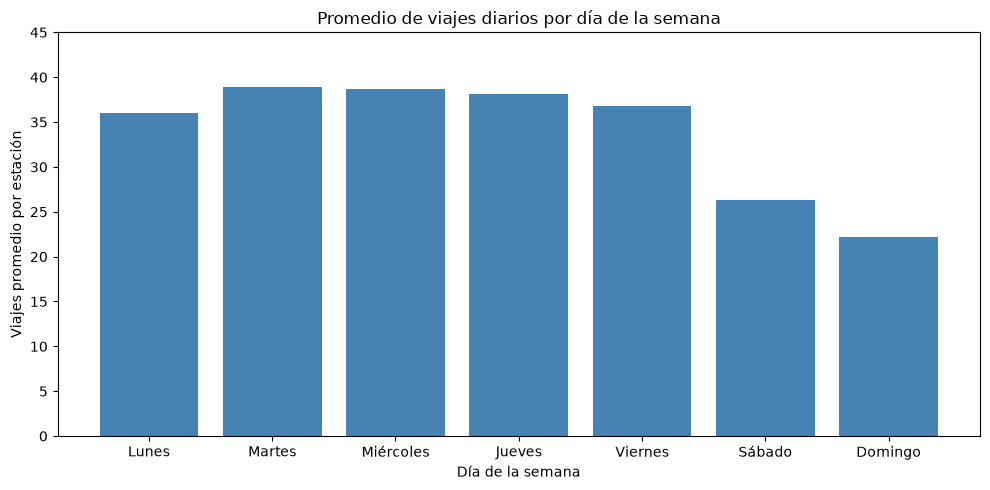

In [413]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    weekday_demand.index,
    weekday_demand["mean"],
    color="steelblue"
)

ax.set_title("Promedio de viajes diarios por día de la semana")
ax.set_xlabel("Día de la semana")
ax.set_ylabel("Viajes promedio por estación")
ax.set_ylim(0, 45)

plt.tight_layout()
plt.show()

**Hallazgos:**
- La demanda es mayor entre martes y jueves, con promedios cercanos a 39 viajes diarios por estación.
- Los sábados y domingos presentan una disminución importante, especialmente los domingos, con 22.22 viajes en promedio.
- La cantidad de registros es similar entre los días de la semana.
- El día de la semana podría ayudar a predecir la demanda, aunque los resultados solo consideran las fechas con registros disponibles.

### 9.8 Demanda por mes
Comparamos el promedio de viajes por estación-día registrado en cada mes. También mostramos el número de observaciones para no confundir diferencias de cobertura con cambios en la demanda.

             mean  median  count
Enero       33.87    24.0  69146
Febrero     36.95    26.0  63056
Marzo       36.03    25.0  69301
Abril       32.20    23.0  66981
Mayo        32.95    23.0  69523
Junio       32.72    24.0  68310
Julio       31.57    23.0  71953
Agosto      32.73    24.0  72876
Septiembre  35.23    25.0  70792
Octubre     36.97    27.0  58847
Noviembre   35.85    26.0  58028
Diciembre   30.19    21.0  60451


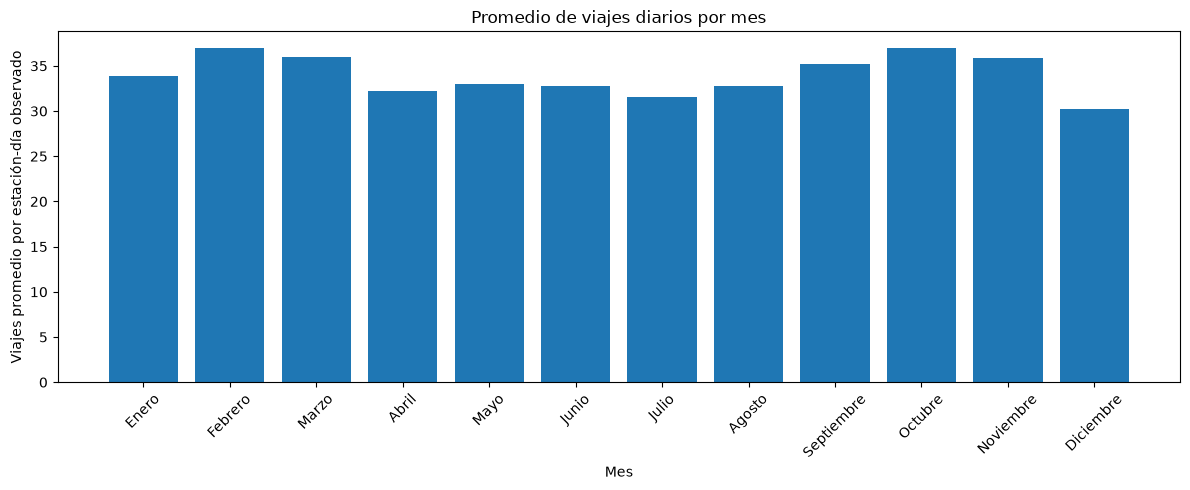

In [414]:
monthly_demand = (
    contract_dataset.groupby("month")["target"]
    .agg(["mean", "median", "count"])
    .round(2)
)
month_names = [
    "Enero", "Febrero", "Marzo", "Abril", "Mayo", "Junio",
    "Julio", "Agosto", "Septiembre", "Octubre", "Noviembre", "Diciembre"
]
monthly_demand.index = month_names
print(monthly_demand.to_string())
fig, ax = plt.subplots(figsize=(12, 5))
ax.bar(monthly_demand.index, monthly_demand["mean"])
ax.set_title("Promedio de viajes diarios por mes")
ax.set_xlabel("Mes")
ax.set_ylabel("Viajes promedio por estación-día observado")
ax.tick_params(axis="x", rotation=45)
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

### 9.9 Demanda y temperatura
Exploramos la relación entre temperatura y viajes diarios. Agrupamos la temperatura en intervalos para comparar promedios y cantidad de registros sin saturar la gráfica. Esta es una relación descriptiva, no una prueba de causalidad.

                      mean  median   count
temperature_2m_mean                       
(10.981, 12.8]       23.99    17.0    1091
(12.8, 14.6]         26.11    17.0    4889
(14.6, 16.4]         31.41    22.0   30823
(16.4, 18.2]         32.88    23.0   75661
(18.2, 20.0]         33.98    24.0  161354
(20.0, 21.8]         34.74    25.0  252643
(21.8, 23.6]         33.91    24.0  142909
(23.6, 25.4]         32.82    23.0   80896
(25.4, 27.2]         34.39    24.0   39506
(27.2, 29.0]         37.17    27.0    9492


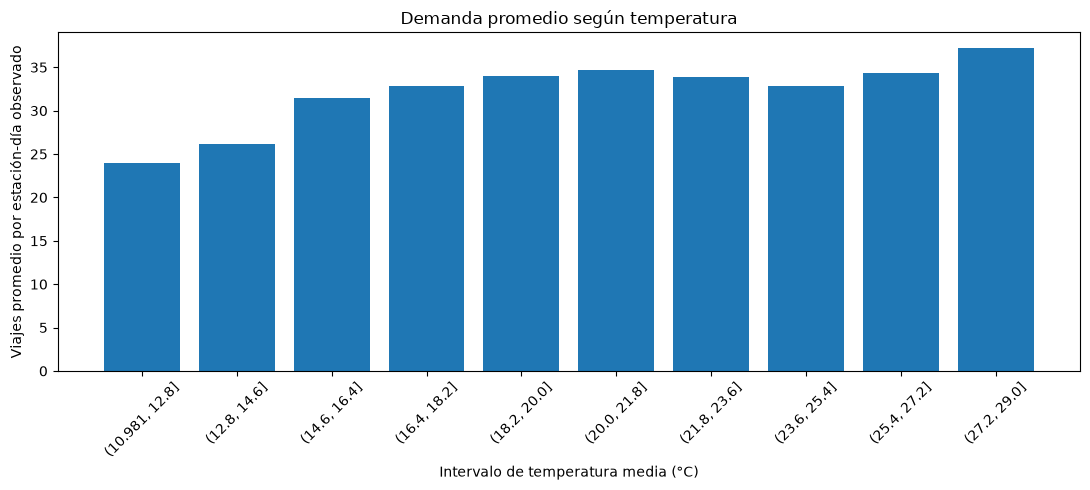

In [415]:
temperature_bins = pd.cut(
    contract_dataset["temperature_2m_mean"],
    bins=10,
    include_lowest=True
)
temperature_demand = (
    contract_dataset.groupby(temperature_bins, observed=True)["target"]
    .agg(["mean", "median", "count"])
    .round(2)
)
print(temperature_demand.to_string())
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(temperature_demand.index.astype(str), temperature_demand["mean"])
ax.set_title("Demanda promedio según temperatura")
ax.set_xlabel("Intervalo de temperatura media (°C)")
ax.set_ylabel("Viajes promedio por estación-día observado")
ax.tick_params(axis="x", rotation=45)
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

### 9.10 Demanda y precipitación
Separamos los registros sin lluvia de los que presentan precipitación y analizamos distintos intervalos. El objetivo es observar si la demanda registrada cambia cuando llueve, sin asumir que conocemos la lluvia real de un día futuro.

                    mean  median   count
precipitation_sum                       
Sin lluvia         34.74    25.0  490237
0–1 mm             33.27    24.0   95678
1–5 mm             33.09    24.0   99192
5–20 mm            31.68    23.0  103883
>20 mm             28.66    20.0   10274


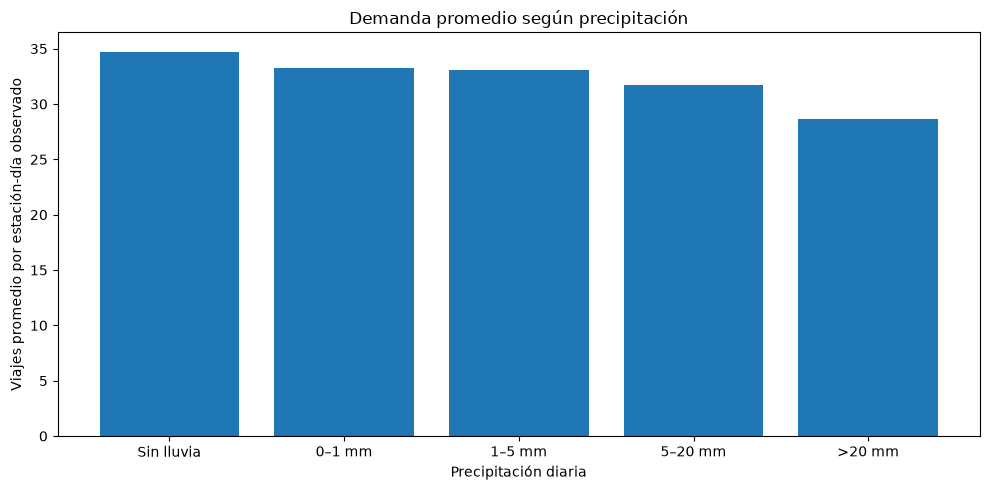

In [416]:
rain_bins = [-0.001, 0, 1, 5, 20, float("inf")]
rain_labels = ["Sin lluvia", "0–1 mm", "1–5 mm", "5–20 mm", ">20 mm"]
rain_category = pd.cut(
    contract_dataset["precipitation_sum"],
    bins=rain_bins,
    labels=rain_labels,
    include_lowest=True
)
rain_demand = (
    contract_dataset.groupby(rain_category, observed=True)["target"]
    .agg(["mean", "median", "count"])
    .round(2)
)
print(rain_demand.to_string())
fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(rain_demand.index.astype(str), rain_demand["mean"])
ax.set_title("Demanda promedio según precipitación")
ax.set_xlabel("Precipitación diaria")
ax.set_ylabel("Viajes promedio por estación-día observado")
ax.set_ylim(bottom=0)
plt.tight_layout()
plt.show()

### 9.11 POI cercanos y demanda por estación
Los POI son atributos de la estación y se repiten en todas sus fechas. Por eso, para evitar contar una misma estación cientos de veces en el análisis de POI, primero calculamos su demanda media y conservamos una sola fila por estación. Después revisamos la relación descriptiva entre la demanda y cada categoría de POI.

Correlación descriptiva con la demanda media por estación:
work_count          0.509
education_count     0.403
commerce_count      0.312
transport_count     0.281
health_count        0.127
recreation_count    0.014


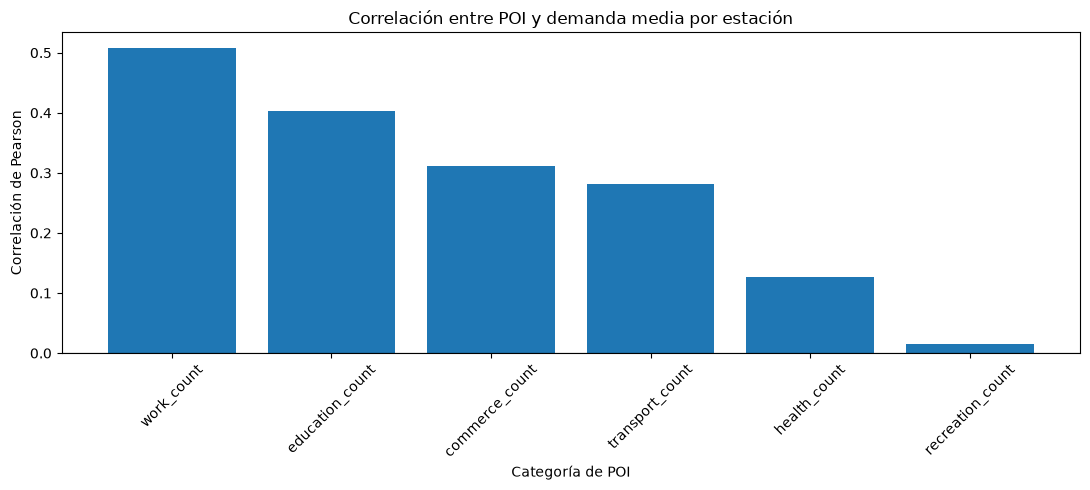

In [417]:
station_demand = (
    contract_dataset.groupby("Origen_Id", as_index=False)
    .agg(mean_target=("target", "mean"), observed_days=("target", "size"))
)
station_poi = contract_dataset[["Origen_Id"] + poi_columns].drop_duplicates("Origen_Id")
station_poi_summary = station_demand.merge(
    station_poi, on="Origen_Id", how="left", validate="one_to_one"
)
poi_correlations = station_poi_summary[poi_columns].corrwith(
    station_poi_summary["mean_target"]
).sort_values(ascending=False)
print("Correlación descriptiva con la demanda media por estación:")
print(poi_correlations.round(3).to_string())
fig, ax = plt.subplots(figsize=(11, 5))
ax.bar(poi_correlations.index, poi_correlations.values)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Correlación entre POI y demanda media por estación")
ax.set_xlabel("Categoría de POI")
ax.set_ylabel("Correlación de Pearson")
ax.tick_params(axis="x", rotation=45)
plt.tight_layout()
plt.show()

### 9.12 Revisión de variables de calendario adicionales
La fecha permite obtener información conocida antes de predecir, como el día del mes o el año. Por ahora solo revisamos su distribución; no añadimos nuevas columnas al Parquet ni afirmamos que mejoren el modelo sin evaluarlas. Los días festivos y periodos vacacionales requerirán una fuente y una definición consistentes.

               mean  count
day_of_month              
1             30.87  26062
2             32.82  26185
3             33.34  26151
4             34.27  26196
5             33.58  26190
6             34.25  26218
7             33.99  26224
8             34.41  26238
9             34.65  26253
10            34.97  26243
11            35.15  26285
12            34.45  26254
13            35.33  26282
14            35.11  26261
15            34.27  26262
16            32.56  26255
17            35.01  26283
18            34.47  26303
19            34.35  26298
20            34.48  26303
21            34.62  26322
22            34.52  26283
23            33.28  26298
24            33.08  26296
25            32.25  26204
26            33.13  26304
27            33.61  26331
28            33.63  26344
29            33.53  24762
30            33.56  24128
31            31.98  15246


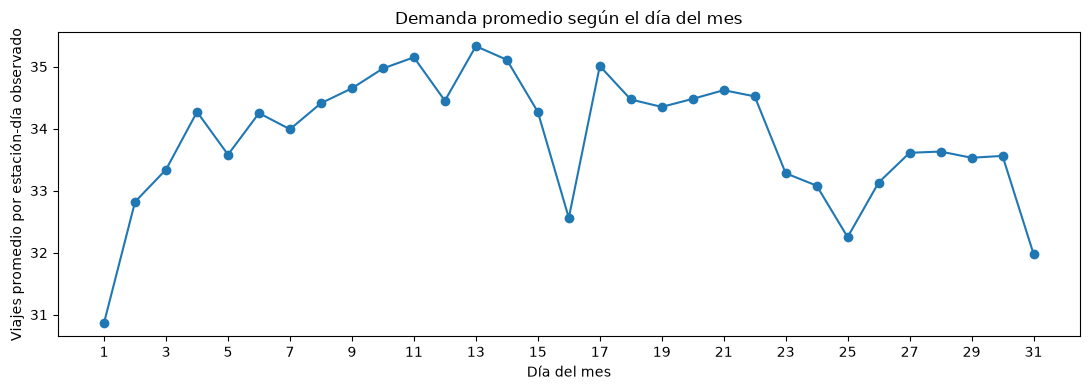

In [418]:
calendar_summary = (
    contract_dataset.assign(
        day_of_month=contract_dataset["Fecha"].dt.day,
        year=contract_dataset["Fecha"].dt.year
    )
    .groupby("day_of_month")["target"]
    .agg(["mean", "count"])
    .round(2)
)
print(calendar_summary.to_string())
fig, ax = plt.subplots(figsize=(11, 4))
ax.plot(calendar_summary.index, calendar_summary["mean"], marker="o")
ax.set_title("Demanda promedio según el día del mes")
ax.set_xlabel("Día del mes")
ax.set_ylabel("Viajes promedio por estación-día observado")
ax.set_xticks(range(1, 32, 2))
plt.tight_layout()
plt.show()

### 9.13 Estaciones con mayor demanda y distribución de POI
Identificamos las 10 estaciones MiBici con mayor demanda media diaria y analizamos la cantidad de puntos de interés (POI) ubicados dentro de un radio de 500 metros.
Para cada estación calculamos el total de POI y su distribución entre las categorías de educación, transporte, comercio, trabajo, salud y recreación.
El objetivo es revisar qué características del entorno presentan las estaciones con mayor demanda y si existen patrones comunes entre ellas.

In [419]:
top_10_stations = (
    station_poi_summary
    .sort_values("mean_target", ascending=False)
    .head(10)
    .copy()
)
top_10_stations["total_poi"] = top_10_stations[poi_columns].sum(axis=1)
top_10_stations = top_10_stations[
    ["Origen_Id", "mean_target", "total_poi"] + poi_columns
]
print("10 estaciones con mayor demanda media diaria:")
display(top_10_stations.round(2))

10 estaciones con mayor demanda media diaria:


,Origen_Id,mean_target,total_poi,education_count,transport_count,commerce_count,work_count,health_count,recreation_count
47,51,230.35,93,29,2,2,52,2,6
31,35,170.21,91,28,3,6,42,0,12
249,271,168.69,45,21,2,2,11,2,7
8,11,163.89,57,20,2,3,26,3,3
48,52,151.67,97,28,2,3,57,2,5
46,50,146.97,59,26,2,2,22,2,5
50,54,138.94,84,29,2,6,33,0,14
176,194,106.84,69,7,0,2,45,1,14
238,260,102.00,61,20,4,4,23,0,10
71,75,97.52,60,24,2,0,28,2,4


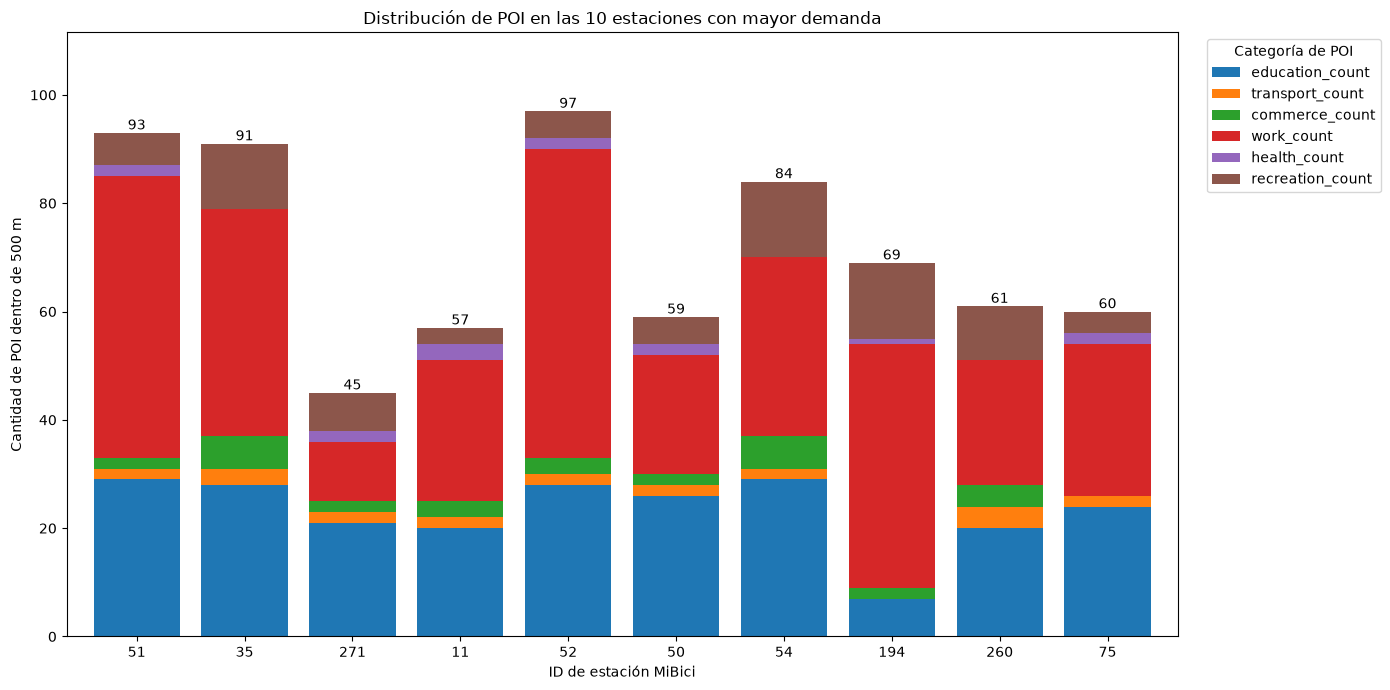

In [420]:
poi_plot = top_10_stations.set_index("Origen_Id")[poi_columns]
ax = poi_plot.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 7),
    width=0.8
)
for index, total in enumerate(top_10_stations["total_poi"]):
    ax.text(index, total, f"{int(total)}", ha="center", va="bottom")
ax.set_title("Distribución de POI en las 10 estaciones con mayor demanda")
ax.set_xlabel("ID de estación MiBici")
ax.set_ylabel("Cantidad de POI dentro de 500 m")
ax.legend(title="Categoría de POI", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.tick_params(axis="x", rotation=0)
ax.set_ylim(0, max(top_10_stations["total_poi"].max() * 1.15, 1))
plt.tight_layout()
plt.show()

Comparamos la demanda media diaria y la cantidad total de POI de las 10 estaciones seleccionadas. Utilizamos dos gráficas para mantener separadas las unidades de medida y observar si las estaciones con mayor demanda también presentan una mayor concentración de lugares de interés.

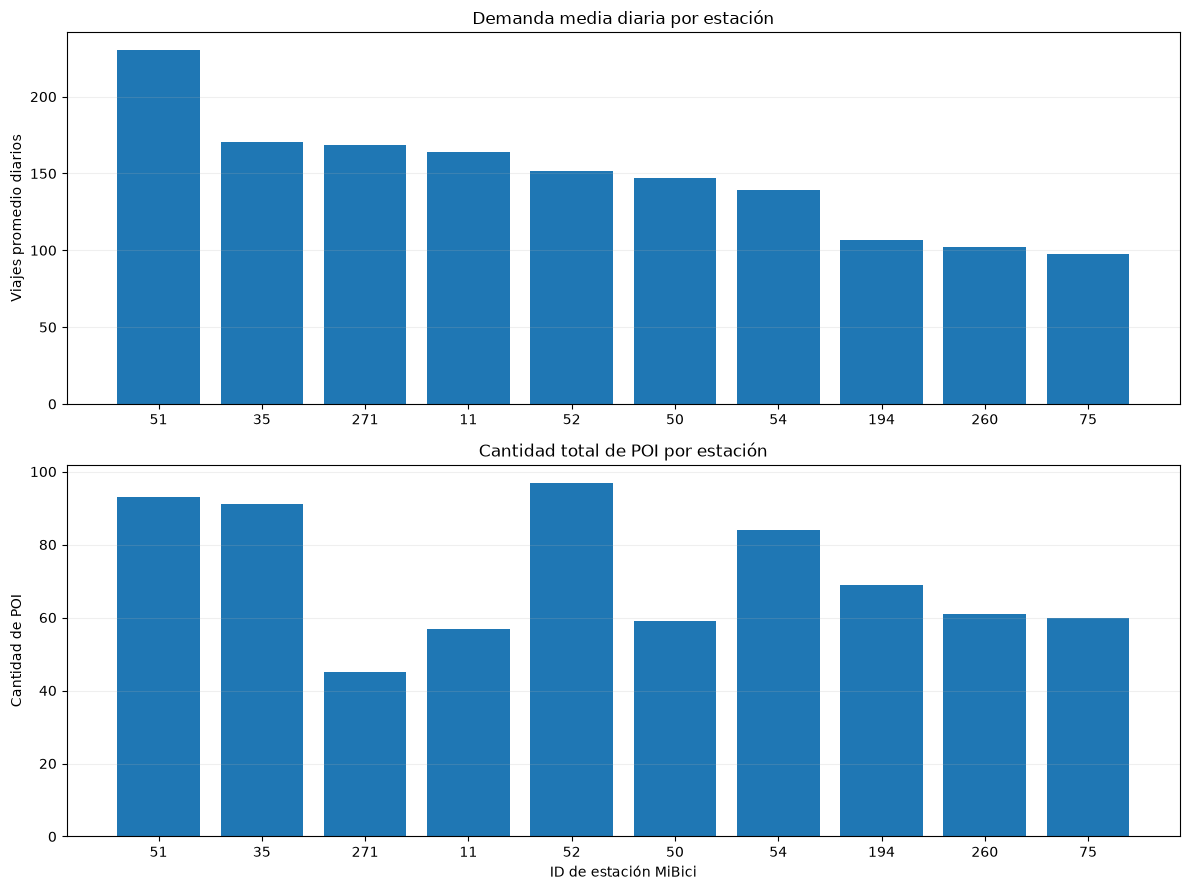

In [421]:
fig, axes = plt.subplots(2, 1, figsize=(12, 9))
station_labels = top_10_stations["Origen_Id"].astype(str)
axes[0].bar(station_labels, top_10_stations["mean_target"])
axes[0].set_title("Demanda media diaria por estación")
axes[0].set_ylabel("Viajes promedio diarios")
axes[0].grid(axis="y", alpha=0.2)
axes[1].bar(station_labels, top_10_stations["total_poi"])
axes[1].set_title("Cantidad total de POI por estación")
axes[1].set_xlabel("ID de estación MiBici")
axes[1].set_ylabel("Cantidad de POI")
axes[1].grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

### 9.14 Estaciones con menor demanda y distribución de POI
Identificamos las 10 estaciones MiBici con menor demanda media diaria y analizamos los puntos de interés (POI) ubicados dentro de un radio de 500 metros.
Para cada estación calculamos el total de POI y su distribución entre las seis categorías. El objetivo es comparar las características del entorno de las estaciones con menor demanda respecto a las que presentan mayor actividad.

In [422]:
bottom_10_stations = (
    station_poi_summary
    .sort_values("mean_target", ascending=True)
    .head(10)
    .copy()
)
bottom_10_stations["total_poi"] = bottom_10_stations[poi_columns].sum(axis=1)
bottom_10_stations = bottom_10_stations[
    ["Origen_Id", "mean_target", "total_poi"] + poi_columns
]
print("10 estaciones con menor demanda media diaria:")
display(bottom_10_stations.round(2))

10 estaciones con menor demanda media diaria:


,Origen_Id,mean_target,total_poi,education_count,transport_count,commerce_count,work_count,health_count,recreation_count
428,465,1.95,48,23,1,0,6,1,17
463,511,2.31,11,6,0,1,0,0,4
403,437,2.88,24,9,2,0,4,0,9
461,509,3.09,7,2,0,1,0,0,4
466,514,3.12,12,6,0,1,0,0,5
329,356,3.15,25,11,2,0,5,1,6
462,510,3.29,13,6,0,1,0,0,6
425,462,3.30,44,20,1,0,5,1,17
221,240,3.33,22,2,1,0,3,1,15
431,468,3.36,9,6,1,0,1,0,1


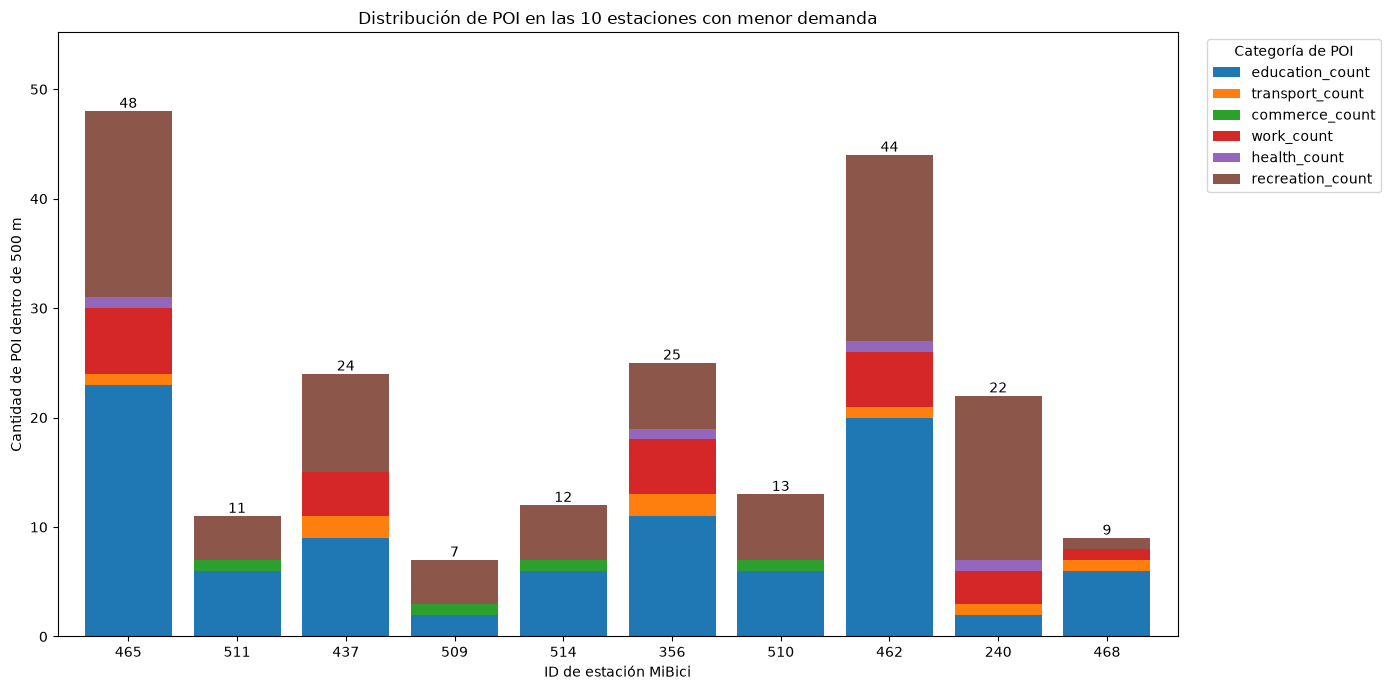

In [423]:
bottom_poi_plot = bottom_10_stations.set_index("Origen_Id")[poi_columns]
ax = bottom_poi_plot.plot(
    kind="bar",
    stacked=True,
    figsize=(14, 7),
    width=0.8
)
for index, total in enumerate(bottom_10_stations["total_poi"]):
    ax.text(index, total, f"{int(total)}", ha="center", va="bottom")
ax.set_title("Distribución de POI en las 10 estaciones con menor demanda")
ax.set_xlabel("ID de estación MiBici")
ax.set_ylabel("Cantidad de POI dentro de 500 m")
ax.legend(title="Categoría de POI", bbox_to_anchor=(1.02, 1), loc="upper left")
ax.tick_params(axis="x", rotation=0)
ax.set_ylim(0, max(bottom_10_stations["total_poi"].max() * 1.15, 1))
plt.tight_layout()
plt.show()

Comparamos la demanda media diaria y el total de POI de las 10 estaciones con menor demanda. Presentamos ambas variables en gráficas separadas para observar sus diferencias sin mezclar unidades de medida.

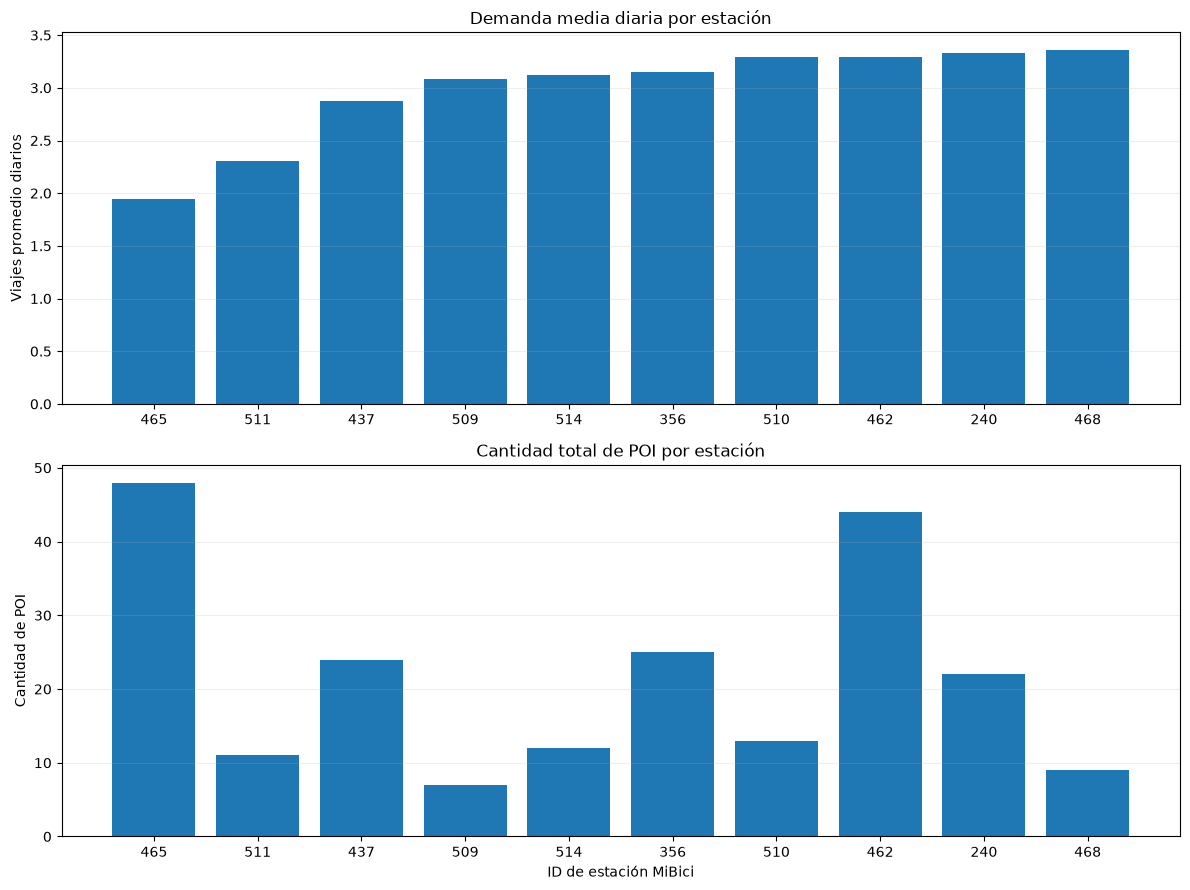

In [424]:
fig, axes = plt.subplots(2, 1, figsize=(12, 9))
station_labels = bottom_10_stations["Origen_Id"].astype(str)
axes[0].bar(station_labels, bottom_10_stations["mean_target"])
axes[0].set_title("Demanda media diaria por estación")
axes[0].set_ylabel("Viajes promedio diarios")
axes[0].grid(axis="y", alpha=0.2)
axes[1].bar(station_labels, bottom_10_stations["total_poi"])
axes[1].set_title("Cantidad total de POI por estación")
axes[1].set_xlabel("ID de estación MiBici")
axes[1].set_ylabel("Cantidad de POI")
axes[1].grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

### 9.15 Relación entre temperatura y demanda media diaria
Analizamos cómo cambia la demanda media diaria de MiBici según la temperatura. Para facilitar la comparación, agrupamos las observaciones en intervalos de 2 °C y calculamos el promedio de viajes por estación y día en cada intervalo.
El objetivo es identificar si existen rangos de temperatura asociados con una mayor o menor demanda, incluyendo posibles relaciones no lineales que no se reflejan en el coeficiente de Pearson.

,temperature_range,mean_demand,observations
0,10.0,21.15,730
1,12.0,25.96,2469
2,14.0,30.80,20329
3,16.0,32.49,73401
4,18.0,33.90,163514
5,20.0,34.72,278658
6,22.0,33.71,146671
7,24.0,32.99,78979
8,26.0,35.20,31789
9,28.0,38.71,2724


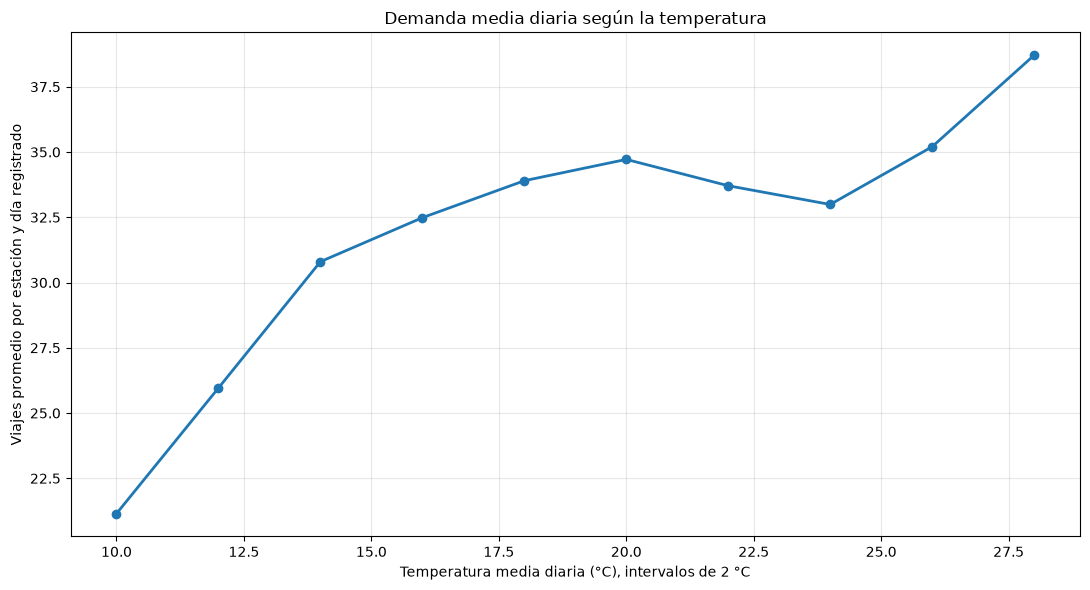

In [425]:
temperature_analysis = contract_dataset[
    ["temperature_2m_mean", "target"]
].copy()
temperature_analysis["temperature_range"] = (
    temperature_analysis["temperature_2m_mean"] // 2 * 2
)
temperature_summary = (
    temperature_analysis
    .groupby("temperature_range")
    .agg(
        mean_demand=("target", "mean"),
        observations=("target", "size")
    )
    .reset_index()
)
display(temperature_summary.round(2))
fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(
    temperature_summary["temperature_range"],
    temperature_summary["mean_demand"],
    marker="o",
    linewidth=2
)
ax.set_title("Demanda media diaria según la temperatura")
ax.set_xlabel("Temperatura media diaria (°C), intervalos de 2 °C")
ax.set_ylabel("Viajes promedio por estación y día registrado")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 9.16 Relación entre precipitación y demanda media diaria
Analizamos cómo cambia la demanda media diaria de MiBici según la cantidad de precipitación registrada. Separamos los días sin lluvia y agrupamos los días con precipitación en diferentes intervalos.
Para cada grupo calculamos el promedio de viajes diarios por estación y la cantidad de observaciones. El objetivo es identificar posibles diferencias en la demanda según la intensidad de la lluvia, incluso cuando la correlación de Pearson es cercana a cero.

,rain_range,mean_demand,observations
0,Sin lluvia,34.74,490237
1,0-2 mm,33.34,131772
2,2-5 mm,32.84,63098
3,5-10 mm,31.86,58513
4,10-20 mm,31.45,45370
5,>20 mm,28.66,10274


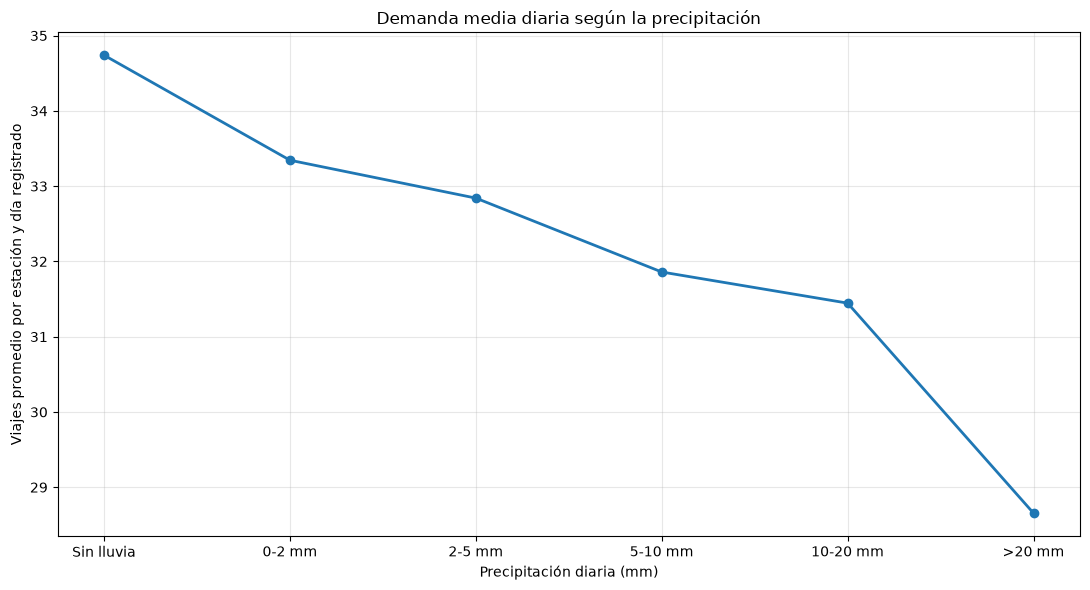

In [426]:
rain_analysis = contract_dataset[
    ["precipitation_sum", "target"]
].copy()
rain_bins = [-0.001, 0, 2, 5, 10, 20, float("inf")]
rain_labels = [
    "Sin lluvia",
    "0-2 mm",
    "2-5 mm",
    "5-10 mm",
    "10-20 mm",
    ">20 mm"
]
rain_analysis["rain_range"] = pd.cut(
    rain_analysis["precipitation_sum"],
    bins=rain_bins,
    labels=rain_labels
)
rain_summary = (
    rain_analysis
    .groupby("rain_range", observed=True)
    .agg(
        mean_demand=("target", "mean"),
        observations=("target", "size")
    )
    .reindex(rain_labels)
    .reset_index()
)
display(rain_summary.round(2))
fig, ax = plt.subplots(figsize=(11, 6))
ax.plot(
    rain_summary["rain_range"],
    rain_summary["mean_demand"],
    marker="o",
    linewidth=2
)
ax.set_title("Demanda media diaria según la precipitación")
ax.set_xlabel("Precipitación diaria (mm)")
ax.set_ylabel("Viajes promedio por estación y día registrado")
ax.grid(alpha=0.3)
plt.tight_layout()
plt.show()

### 9.17 Demanda durante los días oficiales de descanso
Revisamos cómo cambia el uso de MiBici durante los días de descanso obligatorio en México, considerando los años de 2020 a 2026.
Para cada fecha calculamos el promedio de viajes diarios por estación y lo comparamos con los días que no son de descanso obligatorio. También revisamos cuántas estaciones tienen registros para cada fecha.
Se consideran los descansos federales de fecha fija y los que se recorren al lunes, además del 1 de octubre de 2024 por el cambio de gobierno federal. No se incluyen los días electorales ni las celebraciones que no son descansos obligatorios federales.

In [427]:
def nth_monday(year, month, occurrence):
    first_day = date(year, month, 1)
    days_until_monday = (7 - first_day.weekday()) % 7
    return first_day + timedelta(
        days=days_until_monday + 7 * (occurrence - 1)
    )

holiday_records = []

for year in range(2020, 2027):
    holidays = [
        (date(year, 1, 1), "Año Nuevo"),
        (nth_monday(year, 2, 1), "Constitución"),
        (nth_monday(year, 3, 3), "Natalicio de Benito Juárez"),
        (date(year, 5, 1), "Día del Trabajo"),
        (date(year, 9, 16), "Independencia"),
        (nth_monday(year, 11, 3), "Revolución Mexicana"),
        (date(year, 12, 25), "Navidad")
    ]

    if year == 2024:
        holidays.append(
            (date(year, 10, 1), "Cambio de gobierno federal")
        )

    for holiday_date, holiday_name in holidays:
        holiday_records.append({
            "Fecha": pd.Timestamp(holiday_date),
            "holiday_name": holiday_name
        })

official_holidays = pd.DataFrame(holiday_records)

display(official_holidays)

,Fecha,holiday_name
0,2020-01-01,Año Nuevo
1,2020-02-03,Constitución
2,2020-03-16,Natalicio de Benito Juárez
3,2020-05-01,Día del Trabajo
4,2020-09-16,Independencia
5,2020-11-16,Revolución Mexicana
6,2020-12-25,Navidad
7,2021-01-01,Año Nuevo
8,2021-02-01,Constitución
9,2021-03-15,Natalicio de Benito Juárez


In [428]:
holiday_data = contract_dataset[
    ["Origen_Id", "Fecha", "target"]
].copy()

holiday_data["Fecha"] = pd.to_datetime(
    holiday_data["Fecha"]
).dt.normalize()

holiday_data = holiday_data.merge(
    official_holidays,
    on="Fecha",
    how="left",
    validate="many_to_one"
)

holiday_data["is_holiday"] = holiday_data["holiday_name"].notna()
holiday_data["year"] = holiday_data["Fecha"].dt.year

holiday_summary = (
    holiday_data[holiday_data["is_holiday"]]
    .groupby(["year", "Fecha", "holiday_name"], as_index=False)
    .agg(
        mean_demand=("target", "mean"),
        stations_with_data=("Origen_Id", "nunique")
    )
)

holiday_summary["mean_demand"] = holiday_summary[
    "mean_demand"
].round(2)

display(holiday_summary)

,year,Fecha,holiday_name,mean_demand,stations_with_data
0,2020,2020-01-01,Año Nuevo,9.08,254
1,2020,2020-02-03,Constitución,7.38,241
2,2020,2020-03-16,Natalicio de Benito Juárez,20.62,271
3,2020,2020-05-01,Día del Trabajo,12.88,268
4,2020,2020-09-16,Independencia,18.05,269
5,2020,2020-11-16,Revolución Mexicana,17.71,273
6,2020,2020-12-25,Navidad,6.61,250
7,2021,2021-01-01,Año Nuevo,6.98,253
8,2021,2021-02-01,Constitución,16.33,265
9,2021,2021-03-15,Natalicio de Benito Juárez,17.51,269


#### Demanda promedio por festividad
Agrupamos los registros de todos los años por tipo de festividad, sin importar la fecha en que se celebró. Calculamos el promedio de viajes diarios por estación para identificar cuáles días de descanso presentan mayor y menor demanda.

,holiday_name,mean_demand,years_analyzed
1,Cambio de gobierno federal,23.47,1
5,Natalicio de Benito Juárez,22.12,7
7,Revolución Mexicana,21.34,6
3,Día del Trabajo,20.53,7
4,Independencia,20.26,7
2,Constitución,19.90,7
0,Año Nuevo,9.73,7
6,Navidad,8.56,6


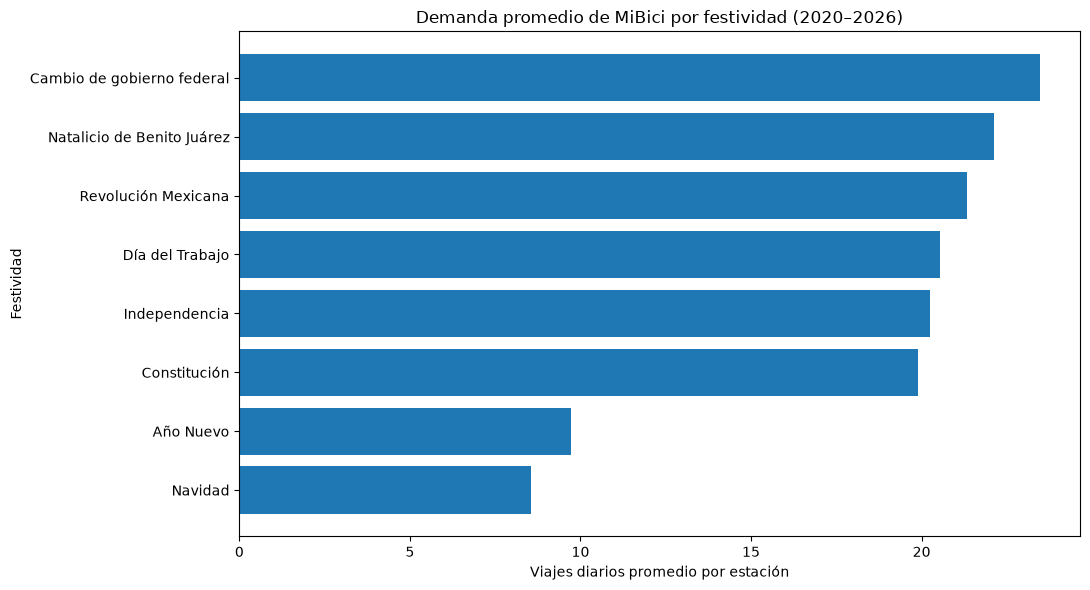

In [429]:
holiday_by_name = (
    holiday_summary.groupby("holiday_name", as_index=False)
    .agg(
        mean_demand=("mean_demand", "mean"),
        years_analyzed=("year", "nunique")
    )
    .sort_values("mean_demand", ascending=False)
)

holiday_by_name["mean_demand"] = holiday_by_name[
    "mean_demand"
].round(2)

display(holiday_by_name)

plt.figure(figsize=(11, 6))

plt.barh(
    holiday_by_name["holiday_name"],
    holiday_by_name["mean_demand"]
)

plt.xlabel("Viajes diarios promedio por estación")
plt.ylabel("Festividad")
plt.title("Demanda promedio de MiBici por festividad (2020–2026)")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

### 9.18 Hallazgos generales del análisis exploratorio

- **Calidad de los datos:** El conjunto de datos final contiene 14 variables y no presenta valores nulos. Sin embargo, encontramos días sin registros de viajes, por lo que debemos tener cuidado de no interpretarlos como días en los que nadie utilizó las bicicletas.

- **Días de la semana:** La demanda es mayor entre martes y jueves, con aproximadamente 39 viajes diarios por estación. Los domingos presentan el menor uso, con un promedio cercano a 22 viajes.

- **Meses del año:** La cantidad de viajes cambia a lo largo del año. Octubre y febrero presentan los promedios más altos, mientras que diciembre registra la menor demanda.

- **Temperatura:** En términos generales, observamos que la demanda tiende a aumentar conforme sube la temperatura. Sin embargo, este comportamiento no es constante en todos los intervalos, por lo que no podemos afirmar que una temperatura más alta siempre represente más viajes.

- **Lluvia:** Encontramos que la demanda disminuye conforme aumenta la cantidad de lluvia. En días sin precipitación se registran aproximadamente 35 viajes diarios por estación, mientras que en días con más de 20 mm de lluvia el promedio baja a 29.

- **Días festivos:** Encontramos que la demanda cambia dependiendo de la festividad. Navidad y Año Nuevo son los días de descanso con menor uso de bicicletas, con promedios de 8.56 y 9.73 viajes diarios por estación, respectivamente. Por otro lado, el natalicio de Benito Juárez y la Revolución Mexicana presentan una demanda más alta, con promedios de 22.12 y 21.34 viajes. Esto nos indica que no todos los días festivos tienen el mismo comportamiento y que vale la pena considerarlos al momento de predecir la demanda.

- **Estaciones con mayor demanda:** Al revisar las 10 estaciones con mayor uso, encontramos una presencia importante de oficinas, lugares de trabajo y centros educativos en sus alrededores. Esto nos hace pensar que una parte importante de los viajes podría estar relacionada con actividades laborales y escolares.

- **Estaciones con menor demanda:** En las 10 estaciones con menor uso encontramos una mayor presencia de lugares recreativos y centros educativos, pero pocos lugares de trabajo. Esto podría indicar que los estudiantes representan una parte importante de sus usuarios. Sin embargo, no tenemos información sobre quién realiza los viajes, por lo que se trata solamente de una posible explicación.

- **Lugares recreativos:** Aunque encontramos varios lugares recreativos cerca de algunas estaciones, su cantidad no parece tener una relación importante con el número de viajes. Esto también se observa en el análisis de correlación, donde los lugares recreativos presentan una relación muy baja con la demanda.

- **Relación entre los lugares cercanos y la demanda:** En general, las estaciones con más lugares de trabajo y centros educativos cerca tienden a registrar más viajes. De las categorías analizadas, los lugares de trabajo presentan la relación más alta con la demanda promedio.

- **Diferencias entre estaciones:** Encontramos diferencias importantes en la cantidad de viajes entre estaciones. Esto nos indica que no todas tienen el mismo comportamiento y que las características de sus alrededores podrían ayudarnos a entender estas diferencias.

- **Consideraciones para el modelado:** Los resultados nos permiten identificar algunas variables que podrían ser útiles para predecir la demanda diaria por estación, principalmente el día de la semana, el mes, la temperatura, la lluvia, los días festivos y los lugares cercanos. Durante el entrenamiento tendremos que comprobar cuáles realmente ayudan a mejorar las predicciones.

## 10. Decisiones previas al modelado (Fase 2)

Después del análisis exploratorio, revisaremos qué variables podemos utilizar para entrenar los modelos, cómo dividiremos los datos y qué aspectos todavía tenemos pendientes.

### 10.1 Qué queremos predecir

Nuestra variable objetivo es `target`, definida en la Fase 1 como el número de viajes diarios que salen de cada estación de MiBici.

Para la Fase 2 predecimos la demanda del día siguiente por estación para el equipo de operación de MiBici (ver la definición completa en la sección 4.8). Utilizaremos la demanda histórica disponible hasta el día anterior, características de las estaciones y datos del calendario.

Por ahora, nuestro conjunto de datos solamente incluye los días con viajes registrados. Todavía necesitamos revisar qué hacer con las fechas sin registros, ya que no necesariamente representan una demanda de cero.

### 10.2 Disponibilidad de variables y riesgos
Aunque durante el análisis exploratorio encontramos algunas variables relacionadas con la demanda, debemos considerar cuáles estarán disponibles al momento de realizar una predicción.
| Variable | ¿Se conoce antes del día a predecir? | Consideración |
|---|---|---|
| Estación, día de la semana y mes | Sí | Podemos utilizarlas desde el primer modelo |
| Día del mes y días festivos | Sí | Podemos incluirlas y evaluar su utilidad |
| Temperatura pronosticada | Sí | Utilizaremos el pronóstico de temperatura para el día siguiente |
| Precipitación pronosticada | Sí | Utilizaremos el pronóstico de lluvia para el día siguiente |
| Puntos de interés (POI) | Actualmente sí, pero podrían haber cambiado con los años | Revisar esta limitación al utilizarlos |
| Viajes históricos | Sí, hasta el día anterior | Podemos calcular variables utilizando únicamente datos anteriores |
Los datos de clima que tenemos son observaciones del mismo día que queremos predecir, no pronósticos. Por eso el modelo principal no los usa; solo los evaluamos aparte para medir cuánto podrían aportar si consiguiéramos pronósticos históricos (por ejemplo, con la Historical Forecast API de Open-Meteo).

### 10.3 Validación temporal y comparación de modelos

Como estamos trabajando con datos históricos, separaremos los periodos de entrenamiento, validación y prueba respetando el orden de las fechas. No tendría sentido entrenar con información posterior al periodo que queremos predecir.

Utilizaremos validación temporal progresiva (*walk-forward*) con origen móvil: entrenamos con los datos disponibles hasta una fecha de corte, evaluamos el mes inmediatamente posterior, avanzamos el corte un mes y repetimos. El resultado se resume con el promedio de las ventanas.

Compararemos:

- Líneas base por estación: la demanda de la misma estación el mismo día de la semana anterior, y el promedio de la estación por día de la semana.
- `RandomForestRegressor`.
- `HistGradientBoostingRegressor`.

Utilizaremos MAE y RMSE para comparar los errores de predicción. Después podremos ajustar los hiperparámetros y registrar los resultados en MLflow.

La preparación de los datos y el entrenamiento se organizarán mediante un pipeline de Scikit-learn. Las transformaciones que dependan de los datos se ajustarán únicamente con el conjunto de entrenamiento.

Las fechas de corte quedan definidas en la sección 11. Los días sin registros no se rellenan con cero (sección 10.5).

### 10.4 Reproducibilidad y organización del repositorio

Durante la Fase 1 utilizamos el notebook para explorar los datos y probar diferentes alternativas de limpieza y procesamiento.

Para la Fase 2 tendremos que pasar el código que podamos reutilizar a módulos `.py`, siguiendo la estructura Cookiecutter del proyecto. El notebook quedará principalmente para mostrar el análisis y los resultados.

También tendremos en cuenta las buenas prácticas que hemos revisado en clase: funciones sencillas, nombres claros, evitar código repetido y no depender de ejecutar las celdas en un orden diferente al establecido.

Las rutas y los parámetros deberán poder configurarse sin modificar directamente el código.

Para la entrega necesitaremos tener el repositorio organizado, los módulos de Python, el pipeline de Scikit-learn, la comparación de modelos y los experimentos registrados en MLflow. También tendremos que registrar una versión del modelo en Model Registry y preparar el PDF y el video del equipo.

### 10.5 Tratamiento de días sin registros

Durante el análisis exploratorio encontramos fechas sin registros de viajes para algunas estaciones.

Esto podría deberse a que una estación todavía no estaba instalada, estuvo fuera de servicio o simplemente no tenemos información de ese día. También es posible que algunas estaciones no hayan tenido viajes.

Antes de entrenar, revisaremos las fechas de primera y última actividad de cada estación y los días faltantes dentro de esos periodos.

Por ahora no asignaremos cero a los días sin registros, porque no tenemos suficiente información para asegurar que realmente no hubo viajes.

Con esta revisión podremos decidir qué registros utilizar para entrenar y evaluar los modelos.

#### Revisión de fechas por estación
Primero revisamos la primera y última fecha con viajes de cada estación. Después calculamos cuántos días hay entre ambas fechas y cuántos no tienen registros. Esto nos ayudará a identificar estaciones con periodos incompletos antes de decidir cómo tratar esos casos.

In [430]:
station_dates = (
    contract_dataset.groupby("Origen_Id")
    .agg(
        first_date=("Fecha", "min"),
        last_date=("Fecha", "max"),
        days_with_data=("Fecha", "nunique")
    )
    .reset_index()
)
station_dates["period_days"] = (
    station_dates["last_date"] - station_dates["first_date"]
).dt.days + 1
station_dates["missing_days"] = (
    station_dates["period_days"] - station_dates["days_with_data"]
)
station_dates = station_dates.sort_values(
    "missing_days", ascending=False
)
print(f"Total de estaciones: {len(station_dates)}")
print(f"Días faltantes: {station_dates['missing_days'].sum()}")
display(station_dates.head(40))

Total de estaciones: 472
Días faltantes: 6144


,Origen_Id,first_date,last_date,days_with_data,period_days,missing_days
96,104,2020-01-01,2026-09-30,1561,2465,904
162,180,2020-01-01,2026-09-30,1875,2465,590
272,294,2020-01-01,2026-09-30,2313,2465,152
93,101,2020-01-02,2026-09-30,2322,2464,142
129,146,2020-01-02,2026-09-30,2327,2464,137
221,240,2020-01-02,2025-06-06,1847,1983,136
17,20,2020-01-01,2026-09-30,2330,2465,135
265,287,2020-01-01,2026-09-30,2340,2465,125
199,217,2020-01-02,2026-09-30,2347,2464,117
329,356,2023-11-04,2026-09-30,950,1062,112


#### Revisión de periodos consecutivos sin registros
Revisamos si los días sin registros aparecen de forma aislada o en periodos consecutivos. Nos interesa identificar las estaciones con interrupciones largas, ya que podrían estar relacionadas con periodos fuera de servicio o falta de información.

In [431]:
station_gaps = contract_dataset[
    ["Origen_Id", "Fecha"]
].drop_duplicates().sort_values(["Origen_Id", "Fecha"]).copy()
station_gaps["previous_date"] = (
    station_gaps.groupby("Origen_Id")["Fecha"].shift(1)
)
station_gaps["gap_days"] = (
    station_gaps["Fecha"] - station_gaps["previous_date"]
).dt.days - 1
station_gaps = station_gaps[
    station_gaps["gap_days"] > 0
].sort_values("gap_days", ascending=False)
print(f"Periodos sin registros: {len(station_gaps)}")
print(f"Días faltantes: {station_gaps['gap_days'].sum()}")
display(station_gaps.head(20))

Periodos sin registros: 2895
Días faltantes: 6144.0


,Origen_Id,Fecha,previous_date,gap_days
236326,104,2026-08-04,2024-06-06,788.0
395081,180,2026-09-11,2025-01-28,590.0
43930,20,2026-03-06,2025-10-24,132.0
553839,247,2026-07-01,2026-03-31,91.0
203562,86,2026-06-26,2026-04-10,76.0
75947,34,2026-08-02,2026-05-23,70.0
31952,15,2026-09-10,2026-07-08,63.0
239047,106,2020-09-10,2020-07-22,49.0
120053,52,2026-06-12,2026-04-30,42.0
474059,213,2020-10-07,2020-08-25,42.0


#### Distribución de los periodos sin registros
Agrupamos los periodos sin registros según su duración para revisar si predominan los días aislados o las interrupciones largas. Por ahora no modificaremos los datos.

In [432]:
gap_ranges = pd.cut(
    station_gaps["gap_days"],
    bins=[0, 1, 3, 7, 30, float("inf")],
    labels=["1 día", "2-3 días", "4-7 días", "8-30 días", "Más de 30 días"],
    include_lowest=True
)
gap_distribution = (
    gap_ranges.value_counts()
    .reindex(gap_ranges.cat.categories)
)
print("Distribución de periodos sin registros:")
display(gap_distribution)
print(f"Total de periodos: {gap_distribution.sum()}")

Distribución de periodos sin registros:


1 día             2455
2-3 días           319
4-7 días            83
8-30 días           16
Más de 30 días      22
Name: count, dtype: int64

Total de periodos: 2895


#### Fechas sin registros en varias estaciones
Revisamos si existen fechas en las que varias estaciones no presentan registros de viajes. Para esto consideramos el periodo comprendido entre la primera y última fecha observada de cada estación.

In [433]:
missing_dates = []
for station in station_dates.itertuples(index=False):
    expected_dates = pd.date_range(
        start=station.first_date,
        end=station.last_date,
        freq="D"
    )
    observed_dates = contract_dataset.loc[
        contract_dataset["Origen_Id"] == station.Origen_Id,
        "Fecha"
    ]
    missing = expected_dates.difference(observed_dates)
    missing_dates.extend(missing)
missing_by_date = (
    pd.Series(missing_dates, name="Fecha")
    .value_counts()
    .rename_axis("Fecha")
    .reset_index(name="stations_without_data")
    .sort_values("stations_without_data", ascending=False)
)
display(missing_by_date.head(40))

,Fecha,stations_without_data
0,2026-02-22,40
1,2020-02-03,33
2,2020-12-25,24
3,2023-12-25,24
4,2026-05-31,22
5,2024-01-01,21
6,2026-06-05,21
7,2021-01-01,21
8,2021-12-25,20
9,2022-12-25,20


#### Estaciones sin registros durante mayo y junio de 2026
Revisamos qué estaciones presentan días sin registros entre mayo y junio de 2026. Esto nos permitirá identificar si las interrupciones se concentran en las mismas estaciones o si afectan a diferentes estaciones en cada fecha.

In [434]:
period_start = pd.Timestamp("2026-05-01")
period_end = pd.Timestamp("2026-06-30")
period_gaps = station_gaps[
    (station_gaps["Fecha"] > period_start) &
    (station_gaps["previous_date"] < period_end)
].copy()
period_gaps["missing_start"] = (
    period_gaps["previous_date"] + pd.Timedelta(days=1)
).clip(lower=period_start)
period_gaps["missing_end"] = (
    period_gaps["Fecha"] - pd.Timedelta(days=1)
).clip(upper=period_end)
period_gaps["missing_days_in_period"] = (
    period_gaps["missing_end"] - period_gaps["missing_start"]
).dt.days + 1
period_gaps = period_gaps[
    period_gaps["missing_days_in_period"] > 0
]
station_missing_summary = (
    period_gaps.groupby("Origen_Id")
    .agg(
        missing_days=("missing_days_in_period", "sum"),
        interruptions=("gap_days", "size")
    )
    .sort_values("missing_days", ascending=False)
)
display(station_missing_summary.head(40))

,missing_days,interruptions
Origen_Id,,
104,61,1
247,61,1
180,61,1
86,56,1
52,42,1
50,38,1
34,38,1
66,37,2
260,35,1


**Cambios respecto a la versión anterior de esta sección:** a partir de los comentarios del profesor ajustamos el modelado en cuatro puntos. (1) Cambiamos las tres ventanas anuales por ventanas mensuales con origen móvil. (2) Agregamos rezagos de la demanda calculados solo con días anteriores. (3) Comparamos contra líneas base por estación, no contra un promedio global. (4) Separamos el clima observado, porque no estaría disponible al momento de predecir. Por estos cambios, los resultados no son directamente comparables con la versión anterior; el MAE de la versión anterior se conserva como referencia en la sección 11.6.

**Origen de los resultados de la sección 11.** Para no repetir pasos que tardan, algunas cifras vienen de una ejecución anterior y están marcadas así en el texto.

| Resultado | Ejecución | Pipeline |
|---|---|---|
| Líneas base (11.6) | Actual | No aplica (no usan el pipeline) |
| Comparación de modelos con parámetros iniciales (11.9): HGB 5.44, RF 5.46 | Actual | Actual, con la tabla de tratamiento de variables (11.5 y 11.7) |
| Modelo final en 12 ventanas (5.44) y prueba 2026 (5.90) (11.13) | Actual | Actual, con `BEST_PARAMS` de Random Forest |
| Comparación de conjuntos de variables (11.8): RF sin historia 7.83 a 7.85, con historia 5.49 | Anterior | Sin `Origen_Id`, sin One-Hot ni día del mes |
| Clima observado (11.10): 5.49 contra 5.50 | Anterior | Sin `Origen_Id`, sin One-Hot ni día del mes |
| Hiperparámetros de Random Forest en `BEST_PARAMS` | Búsqueda de la versión anterior | Ventanas anuales y sin la tabla de tratamiento |

Las cifras de la ejecución anterior se usan solo para justificar decisiones (incluir la historia, excluir el clima), no como resultado del modelo final. Para reproducirlas con el pipeline actual, encender `COMPARE_FEATURE_SETS` y `RUN_WEATHER_REFERENCE` en la sección 11.1.

## 11. Preparación de datos para el modelado
### 11.1 Parámetros del modelado
Reunimos en una sola celda los valores que se usan en toda la sección: horizonte, rezagos, fechas de corte, número de ventanas, semilla e hiperparámetros iniciales. Así no se repiten en cada celda y después pueden pasar a `config.py`.

In [435]:
HORIZON_DAYS = 1                     # predecimos el día siguiente
LAGS = [1, 7, 14]                    # deben ser >= HORIZON_DAYS
ROLLING_WINDOWS = [7, 28]
TEST_START = pd.Timestamp("2026-01-01")
FIRST_CUTOFF = pd.Timestamp("2025-01-01")
N_FOLDS = 12                         # cortes mensuales de enero a diciembre de 2025
SEED = 42
target_column = "target"

# Interruptores para las partes que tardan. Con False se usan los resultados ya obtenidos.
COMPARE_FEATURE_SETS = False         # 11.8: comparar los cuatro conjuntos de variables (~15 min)
RUN_WEATHER_REFERENCE = False        # 11.10: modelo con clima observado (~4 min)
RUN_GRID_SEARCH = False              # 11.11: búsqueda de hiperparámetros (~1 h con las dos rejillas)

rf_initial_params = {
    "n_estimators": 100,
    "max_depth": 15,
    "min_samples_leaf": 5,
    "max_samples": 0.5,              # cada árbol usa 50 % de las filas: casi el doble de rápido
    "random_state": SEED,
    "n_jobs": -1
}
hgb_initial_params = {
    "max_iter": 100,
    "max_leaf_nodes": 31,
    "learning_rate": 0.1,
    "random_state": SEED
}

# Parámetros que se usan cuando RUN_GRID_SEARCH = False.
# Random Forest: mejor configuración de la búsqueda de la versión anterior (150 árboles,
#   profundidad 15, hoja mínima 5, 70 % de variables); en las 12 ventanas de 2025 obtiene MAE 5.44.
# HistGradientBoosting: configuración de partida para la búsqueda; todavía no se ha evaluado
#   en el walk-forward. Con parámetros iniciales obtiene MAE 5.44, prácticamente igual a Random Forest.
# Si se ejecuta la búsqueda (11.11), copiar aquí los parámetros que imprime la celda 11.12.
FINAL_MODEL = "Random Forest"
BEST_PARAMS = {
    "Random Forest": {
        "n_estimators": 150,
        "max_depth": 15,
        "min_samples_leaf": 5,
        "max_features": 0.7
    },
    "HistGradientBoosting": {
        "learning_rate": 0.1,
        "max_iter": 200,
        "max_leaf_nodes": 31,
        "loss": "poisson"
    }
}

### 11.2 Variables de historia de la demanda
La demanda de los días anteriores es la información más directa que tiene el equipo de operación al planear el día siguiente. Calculamos:

- `lag_1`, `lag_7`, `lag_14`: viajes de la misma estación 1, 7 y 14 días antes.
- `roll_mean_7`, `roll_mean_28`: promedio de los últimos 7 y 28 días disponibles.
- `active_days_7`, `active_days_28`: cuántos de esos días tuvieron registros.

Los rezagos se calculan **por fecha y no por fila**. Como el dataset no tiene filas para los días sin viajes, `groupby().shift(7)` podría tomar un día que en realidad está 9 o 10 días atrás. Por eso construimos una tabla fecha × estación con todos los días del calendario; los días sin registro quedan como `NaN` (no como cero) y sobre esa tabla calculamos los rezagos.

Todos los valores usan únicamente fechas anteriores al día que se predice. Si se cambia `HORIZON_DAYS`, la función no permite rezagos menores al horizonte.

In [436]:
def add_history_features(data, horizon, lags, windows):
    invalid_lags = [lag for lag in lags if lag < horizon]
    if invalid_lags:
        raise ValueError(f"Los rezagos {invalid_lags} usarían información futura con horizonte {horizon}.")

    demand_grid = (
        data.pivot(index="Fecha", columns="Origen_Id", values=target_column)
        .asfreq("D")
    )
    available = demand_grid.shift(horizon)

    history = {f"lag_{lag}": demand_grid.shift(lag) for lag in lags}
    for window in windows:
        history[f"roll_mean_{window}"] = available.rolling(window, min_periods=1).mean()
        history[f"active_days_{window}"] = available.rolling(window, min_periods=1).count()

    date_positions = demand_grid.index.get_indexer(data["Fecha"])
    station_positions = demand_grid.columns.get_indexer(data["Origen_Id"])

    result = data.copy()
    for name, values in history.items():
        result[name] = values.to_numpy()[date_positions, station_positions]
    return result


model_dataset = add_history_features(contract_dataset, HORIZON_DAYS, LAGS, ROLLING_WINDOWS)
history_columns = [
    column for column in model_dataset.columns
    if column.startswith(("lag_", "roll_mean_", "active_days_"))
]
print("Variables de historia:", history_columns)
print("\nProporción de valores faltantes (estaciones nuevas o días sin registro):")
print(model_dataset[history_columns].isna().mean().round(3).to_string())

Variables de historia: ['lag_1', 'lag_7', 'lag_14', 'roll_mean_7', 'active_days_7', 'roll_mean_28', 'active_days_28']

Proporción de valores faltantes (estaciones nuevas o días sin registro):
lag_1             0.004
lag_7             0.008
lag_14            0.013
roll_mean_7       0.001
active_days_7     0.000
roll_mean_28      0.001
active_days_28    0.000


#### Comprobación de que los rezagos no usan información futura
Tomamos una estación y comparamos `lag_7` con el valor real registrado siete días antes. Si la fecha anterior no tiene registro, el rezago debe ser `NaN`.

In [437]:
sample_station = model_dataset["Origen_Id"].iloc[0]
station_rows = model_dataset.loc[
    model_dataset["Origen_Id"] == sample_station, ["Fecha", target_column, "lag_7"]
].set_index("Fecha")
expected_lag_7 = station_rows[target_column].reindex(station_rows.index - pd.Timedelta(days=7)).to_numpy()
assert np.allclose(station_rows["lag_7"].to_numpy(), expected_lag_7, equal_nan=True)
print(f"Estación {sample_station}: lag_7 coincide con el valor de 7 días antes.")

Estación 2: lag_7 coincide con el valor de 7 días antes.


#### Variables de calendario derivadas de la fecha
De acuerdo con la tabla de tratamiento de variables, extraemos de `Fecha` el día del mes y el año. Conservamos `Fecha` sin modificar para ordenar y construir las ventanas de validación, pero no entra al modelo como número.

In [438]:
model_dataset["day_of_month"] = model_dataset["Fecha"].dt.day
model_dataset["year"] = model_dataset["Fecha"].dt.year
print(model_dataset[["Fecha", "day_of_week", "month", "day_of_month", "year"]].head().to_string(index=False))

     Fecha  day_of_week  month  day_of_month  year
2020-01-01            2      1             1  2020
2020-01-02            3      1             2  2020
2020-01-03            4      1             3  2020
2020-01-04            5      1             4  2020
2020-01-05            6      1             5  2020


### 11.3 Separación del conjunto de desarrollo y prueba
Dividimos los datos utilizando el 1 de enero de 2026 como fecha de corte. Los registros anteriores se utilizarán para el desarrollo y la validación temporal de los modelos, mientras que los registros de 2026 quedarán reservados para una sola evaluación final.

Los rezagos se calcularon antes de separar porque solo miran hacia atrás y no aprenden parámetros de los datos. Las transformaciones que sí aprenden (como la imputación) se ajustan dentro del pipeline con el entrenamiento de cada ventana.

In [439]:
development_data = model_dataset.loc[model_dataset["Fecha"] < TEST_START].reset_index(drop=True)
test_data = model_dataset.loc[model_dataset["Fecha"] >= TEST_START].reset_index(drop=True)
print("Conjunto de desarrollo:")
print(f"Registros: {len(development_data):,}")
print(f"Periodo: {development_data['Fecha'].min().date()} a {development_data['Fecha'].max().date()}")
print(f"Estaciones: {development_data['Origen_Id'].nunique()}")
print("Conjunto de prueba:")
print(f"Registros: {len(test_data):,}")
print(f"Periodo: {test_data['Fecha'].min().date()} a {test_data['Fecha'].max().date()}")
print(f"Estaciones: {test_data['Origen_Id'].nunique()}")

Conjunto de desarrollo:
Registros: 690,970
Periodo: 2020-01-01 a 2025-12-31
Estaciones: 374
Conjunto de prueba:
Registros: 108,294
Periodo: 2026-01-01 a 2026-09-30
Estaciones: 469


### 11.4 Validación temporal con origen móvil (walk-forward)
Seguimos el esquema que sugirió el profesor:

1. Entrenamos con todos los datos disponibles hasta una fecha de corte.
2. Evaluamos el mes inmediatamente posterior.
3. Avanzamos la fecha de corte un mes y repetimos.
4. Resumimos con el promedio (y la desviación estándar) de todas las ventanas.

Usamos 12 cortes mensuales, de enero a diciembre de 2025. En la versión anterior usábamos tres ventanas de un año completo; con ventanas mensuales cada evaluación está más cerca de la fecha de corte, que es como se usaría el modelo, y tenemos más ventanas para estimar la variabilidad del error.

Si el horizonte fuera mayor a un día, se deja un hueco de `HORIZON_DAYS - 1` días entre el entrenamiento y la evaluación, porque esos días todavía no tendrían su valor real al momento de predecir.

In [440]:
def walk_forward_splits(data, first_cutoff, n_folds, horizon):
    dates = data["Fecha"]
    splits = []
    for cutoff in pd.date_range(first_cutoff, periods=n_folds, freq="MS"):
        train_end = cutoff - pd.Timedelta(days=horizon - 1)
        validation_end = cutoff + pd.DateOffset(months=1)
        train_positions = np.flatnonzero(dates < train_end)
        validation_positions = np.flatnonzero((dates >= cutoff) & (dates < validation_end))
        splits.append((cutoff, train_positions, validation_positions))
    return splits


validation_splits = walk_forward_splits(development_data, FIRST_CUTOFF, N_FOLDS, HORIZON_DAYS)
cross_validation_splits = [(train, validation) for _, train, validation in validation_splits]

split_summary = []
for cutoff, train_positions, validation_positions in validation_splits:
    train_stations = set(development_data.loc[train_positions, "Origen_Id"])
    validation_stations = set(development_data.loc[validation_positions, "Origen_Id"])
    split_summary.append({
        "cutoff": cutoff.date(),
        "train_end": development_data.loc[train_positions, "Fecha"].max().date(),
        "train_rows": len(train_positions),
        "validation_rows": len(validation_positions),
        "new_stations": len(validation_stations - train_stations)
    })
display(pd.DataFrame(split_summary))

,cutoff,train_end,train_rows,validation_rows,new_stations
0,2025-01-01,2024-12-31,557255,11373,0
1,2025-02-01,2025-01-31,568628,10230,0
2,2025-03-01,2025-02-28,578858,11355,0
3,2025-04-01,2025-03-31,590213,10991,0
4,2025-05-01,2025-04-30,601204,11366,0
5,2025-06-01,2025-05-31,612570,10978,1
6,2025-07-01,2025-06-30,623548,11352,0
7,2025-08-01,2025-07-31,634900,11363,0
8,2025-09-01,2025-08-31,646263,11000,0
9,2025-10-01,2025-09-30,657263,11363,1


**Supuesto de actualización diaria.** Aunque evaluamos ventanas de un mes, cada predicción corresponde solo al día siguiente. Suponemos que los registros de viajes se actualizan cada día, así que los rezagos de una fecha del mes evaluado usan la demanda real disponible hasta el día anterior, aunque ese día también esté dentro del mes evaluado. Por ejemplo, con entrenamiento hasta el 31 de enero:

| Fecha a predecir | `lag_1` que se usa | ¿Válido? |
|---|---|---|
| 1 de febrero | Viajes reales del 31 de enero | Sí |
| 2 de febrero | Viajes reales del 1 de febrero | Sí, porque se predice un día a la vez |
| 8 de febrero | Viajes reales del 7 de febrero | Sí, porque se predice un día a la vez |

El modelo se vuelve a entrenar en cada corte mensual, pero las variables de historia se actualizan diariamente. Esto no equivale a generar el 31 de enero las predicciones de todo febrero: en ese caso no se conocerían los viajes del 1 o del 7 de febrero y habría que usar rezagos más largos o predicciones recursivas. Lo mismo aplica a la prueba de 2026: el modelo se entrena una sola vez con 2020 a 2025 y cada día se predice con los viajes reales del día anterior.

### 11.5 Selección y tratamiento de las variables
Aplicamos la tabla de tratamiento definida por el equipo. Las transformaciones que aprenden de los datos (codificación e imputación) se ajustan dentro del pipeline (11.7), con el entrenamiento de cada ventana.

| Variable | Tipo | Tratamiento | ¿Por qué? | ¿Entra al modelo principal? |
|---|---|---|---|---|
| `Origen_Id` | Categórica | Target Encoding | Es un identificador: la estación 100 no es "mayor" que la 50. Con One-Hot serían 472 columnas, lo que hace el Random Forest mucho más lento y con árboles aporta poco; Target Encoding resume cada estación en su nivel de demanda aprendido del entrenamiento y asigna el promedio general a estaciones nuevas. | Sí |
| `Fecha` | Temporal | Extraer componentes | Se conserva para ordenar y validar; no entra como número. | No |
| `day_of_week` | Categórica | One-Hot Encoding | Lunes a domingo no siguen una relación lineal. | Sí |
| `month` | Categórica | One-Hot Encoding | Patrones estacionales sin imponer orden numérico. | Sí |
| `day_of_month` | Numérica discreta | Sin transformación | Permite evaluar patrones dentro del mes (quincenas, inicio de mes). | Sí |
| `year` | Numérica temporal | Sin transformación | Los árboles no extrapolan: para 2026 lo tratan igual que 2025. La tendencia ya la capturan los promedios móviles. | No (se deja como opción) |
| `weather_zone` | Categórica | One-Hot Encoding | Es un identificador geográfico, no una cantidad. | Sí |
| `temperature_2m_mean`, `precipitation_sum` | Numérica continua | Sin normalización | Los árboles no necesitan escalado. Son observaciones del mismo día, no pronósticos. | No (solo referencia, 11.10) |
| Conteos de POI | Numérica discreta | Sin transformación | Cantidad de lugares cercanos. | Sí |
| `lag_1`, `lag_7`, `lag_14`, promedios móviles | Numérica histórica | Sin normalización; imputación por mediana con indicador | Pueden faltar en estaciones nuevas o días sin registro. | Sí |
| `target` | Objetivo | Sin transformación | Predecimos directamente la cantidad de viajes. | — |

No normalizamos ninguna variable porque los dos modelos son de árboles: dividen por umbrales y el resultado no cambia con la escala.

In [441]:
station_id_columns = ["Origen_Id"]
onehot_columns = ["day_of_week", "month", "weather_zone"]
calendar_columns = ["day_of_week", "month", "day_of_month"]
station_columns = ["weather_zone"] + poi_columns
weather_columns = ["temperature_2m_mean", "precipitation_sum"]

feature_sets = {
    "original_11_variables": ["day_of_week", "month"] + station_columns + weather_columns,
    "calendario_estacion": station_id_columns + calendar_columns + station_columns,
    "calendario_estacion_historia": station_id_columns + calendar_columns + station_columns + history_columns,
    "historia_y_clima_observado": station_id_columns + calendar_columns + station_columns + history_columns + weather_columns
}
main_feature_set = "calendario_estacion_historia"
feature_columns = feature_sets[main_feature_set]
for name, columns in feature_sets.items():
    print(f"{name}: {len(columns)} variables")

original_11_variables: 11 variables
calendario_estacion: 11 variables
calendario_estacion_historia: 18 variables
historia_y_clima_observado: 20 variables


### 11.6 Métodos, líneas base y métricas
- **Línea base ingenua estacional:** para cada estación, la demanda del mismo día de la semana anterior (`lag_7`). Es lo que haría un planificador sin modelo y es la referencia principal. Si ese día no tiene registro, usa el promedio de la estación para ese día de la semana.
- **Promedio por estación y día de la semana:** promedio histórico calculado solo con el entrenamiento de cada ventana.
- **Promedio global por día de la semana:** la línea base de la versión anterior. La conservamos solo como referencia: no distingue estaciones, por lo que cualquier modelo que identifique la estación la supera fácilmente.
- **Random Forest** y **HistGradientBoosting:** modelos de árboles que aprenden relaciones no lineales e interacciones entre calendario, estación e historia.

Métricas: **MAE** (viajes por estación-día, métrica de selección), **RMSE** (penaliza errores grandes, que son los que dejan estaciones vacías) y **mejora sobre la línea base ingenua**, calculada como `1 - MAE_modelo / MAE_ingenuo`. Si es negativa, el modelo es peor que repetir la semana anterior.

In [442]:
def regression_metrics(y_true, y_pred):
    return {
        "mae": mean_absolute_error(y_true, y_pred),
        "rmse": mean_squared_error(y_true, y_pred) ** 0.5
    }


def station_weekday_means(train_data):
    return train_data.groupby(["Origen_Id", "day_of_week"])[target_column].mean()


def predict_station_weekday(train_data, data):
    means = station_weekday_means(train_data)
    keys = pd.MultiIndex.from_frame(data[["Origen_Id", "day_of_week"]])
    predictions = pd.Series(means.reindex(keys).to_numpy(), index=data.index)
    weekday_means = train_data.groupby("day_of_week")[target_column].mean()
    return predictions.fillna(data["day_of_week"].map(weekday_means))


def predict_seasonal_naive(train_data, data):
    fallback = predict_station_weekday(train_data, data)
    return data["lag_7"].fillna(fallback)


def predict_global_weekday(train_data, data):
    weekday_means = train_data.groupby("day_of_week")[target_column].mean()
    return data["day_of_week"].map(weekday_means)


baselines = {
    "Ingenuo estacional (lag_7)": predict_seasonal_naive,
    "Promedio estación-día": predict_station_weekday,
    "Promedio global por día (versión anterior)": predict_global_weekday
}

#### Evaluación de las líneas base con validación temporal
Evaluamos las tres líneas base en las mismas 12 ventanas. Los promedios se calculan solo con el entrenamiento de cada ventana.

In [443]:
baseline_results = []
for cutoff, train_positions, validation_positions in validation_splits:
    train_data = development_data.loc[train_positions]
    validation_data = development_data.loc[validation_positions]
    for name, predict in baselines.items():
        predictions = predict(train_data, validation_data)
        baseline_results.append({
            "cutoff": cutoff.date(),
            "model": name,
            **regression_metrics(validation_data[target_column], predictions)
        })
baseline_results = pd.DataFrame(baseline_results)
display(
    baseline_results.groupby("model")[["mae", "rmse"]]
    .agg(["mean", "std"]).round(2).sort_values(("mae", "mean"))
)

mae         rmse      
                                             mean   std   mean   std
model                                                               
Ingenuo estacional (lag_7)                   7.22  0.69  11.83  2.16
Promedio estación-día                        7.70  0.78  12.68  1.66
Promedio global por día (versión anterior)  22.99  0.69  33.78  1.90

**Interpretación de las líneas base (ejecución del 3 de noviembre):**
- Repetir la demanda de la misma estación el mismo día de la semana anterior da un error promedio de **7.22 viajes por estación-día**. Es la referencia que cualquier modelo tiene que superar.
- El promedio por estación y día de la semana queda un poco peor (7.70). Que el valor de la semana pasada le gane al promedio histórico indica que la demanda reciente dice más que la de años anteriores: las estaciones cambian de nivel con el tiempo.
- El promedio global por día de la semana, que era la línea base de la versión anterior, tiene un error de 22.99, tres veces mayor. Al no distinguir estaciones, no sirve como comparación: superarlo no demuestra que el modelo aporte valor.

### 11.7 Pipeline de Scikit-Learn
El pipeline aplica la tabla de tratamiento de la sección 11.5 y después entrena el modelo:

| Paso | Columnas | Transformación |
|---|---|---|
| `station` | `Origen_Id` | `TargetEncoder`: nivel de demanda de cada estación, aprendido solo con el entrenamiento (con validación cruzada interna para no filtrar el propio objetivo). |
| `categorical` | `day_of_week`, `month`, `weather_zone` | `OneHotEncoder` con `handle_unknown="ignore"` para categorías que no aparezcan en el entrenamiento. |
| `history` | rezagos y promedios móviles | `SimpleImputer` con la mediana del entrenamiento y una columna que indica que el dato faltaba. |
| `numeric` | día del mes, POI, clima (si se usa) | Sin cambios. |

Como todo lo que aprende de los datos está dentro del pipeline, en cada ventana del walk-forward se vuelve a ajustar solo con los datos anteriores a la fecha de corte. La función decide qué paso aplica a cada columna, así sirve para cualquier conjunto de variables.

In [444]:
def build_model_pipeline(model, columns):
    station = [column for column in columns if column in station_id_columns]
    categorical = [column for column in columns if column in onehot_columns]
    history = [column for column in columns if column in history_columns]
    numeric = [column for column in columns if column not in station + categorical + history]

    transformers = []
    if station:
        transformers.append(("station", TargetEncoder(target_type="continuous", random_state=SEED), station))
    if categorical:
        transformers.append(("categorical", OneHotEncoder(handle_unknown="ignore", sparse_output=False), categorical))
    if history:
        transformers.append((
            "history",
            SimpleImputer(strategy="median", add_indicator=True, keep_empty_features=True),
            history
        ))
    if numeric:
        transformers.append(("numeric", "passthrough", numeric))
    preprocessing = ColumnTransformer(transformers=transformers, remainder="drop")
    return Pipeline(steps=[("preprocessing", preprocessing), ("model", model)])


def make_model(model_name, params=None):
    if model_name == "Random Forest":
        return RandomForestRegressor(**{**rf_initial_params, **(params or {})})
    return HistGradientBoostingRegressor(**{**hgb_initial_params, **(params or {})})


def evaluate_walk_forward(pipeline, columns, model_name):
    rows = []
    for cutoff, train_positions, validation_positions in validation_splits:
        train_data = development_data.loc[train_positions]
        validation_data = development_data.loc[validation_positions]
        fitted = clone(pipeline).fit(train_data[columns], train_data[target_column])
        predictions = fitted.predict(validation_data[columns])
        rows.append({
            "cutoff": cutoff.date(),
            "model": model_name,
            **regression_metrics(validation_data[target_column], predictions)
        })
    return pd.DataFrame(rows)


example_pipeline = build_model_pipeline(make_model("Random Forest"), feature_columns)
example_pipeline.fit(development_data[feature_columns].head(5000), development_data[target_column].head(5000))
print(example_pipeline)
print("Columnas que recibe el modelo:", len(example_pipeline.named_steps["preprocessing"].get_feature_names_out()))

/home/josel/mlops/equipo-8-mibici-mlops/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


Pipeline(steps=[('preprocessing',
                 ColumnTransformer(transformers=[('station',
                                                  TargetEncoder(random_state=42,
                                                                target_type='continuous'),
                                                  ['Origen_Id']),
                                                 ('categorical',
                                                  OneHotEncoder(handle_unknown='ignore',
                                                                sparse_output=False),
                                                  ['day_of_week', 'month',
                                                   'weather_zone']),
                                                 ('history',
                                                  SimpleImputer(add_indicator=True,
                                                                keep_empty_features=True,
                                                

### 11.8 Entrenamiento inicial con Random Forest e HistGradientBoosting
Evaluamos los dos modelos con los parámetros iniciales en las mismas ventanas que las líneas base, usando el conjunto principal de variables.

La comparación entre conjuntos de variables (`original_11_variables`, `calendario_estacion`, `calendario_estacion_historia`) tarda alrededor de 15 minutos y solo se necesita una vez, así que está detrás de `COMPARE_FEATURE_SETS`. En la ejecución del 3 de noviembre (antes de aplicar la tabla de tratamiento) obtuvimos un MAE promedio de Random Forest de 7.85 con las 11 variables originales, 7.83 con calendario y estación, y 5.49 al agregar la historia; el ingenuo estacional tuvo 7.22.

In [445]:
feature_sets_to_compare = (
    ["original_11_variables", "calendario_estacion", main_feature_set]
    if COMPARE_FEATURE_SETS else [main_feature_set]
)

model_results = []
for feature_set in feature_sets_to_compare:
    columns = feature_sets[feature_set]
    for model_name in ["Random Forest", "HistGradientBoosting"]:
        results = evaluate_walk_forward(
            build_model_pipeline(make_model(model_name), columns), columns, f"{model_name} | {feature_set}"
        )
        model_results.append(results)
model_results = pd.concat(model_results, ignore_index=True)

/home/josel/mlops/equipo-8-mibici-mlops/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
/home/josel/mlops/equipo-8-mibici-mlops/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
/home/josel/mlops/equipo-8-mibici-mlops/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.

### 11.9 Comparación contra las líneas base
Comparamos todos los métodos con el promedio de las 12 ventanas y calculamos la mejora sobre la línea base ingenua en cada ventana.

In [446]:
all_results = pd.concat([baseline_results, model_results], ignore_index=True)
naive_mae = baseline_results.loc[
    baseline_results["model"] == "Ingenuo estacional (lag_7)"
].set_index("cutoff")["mae"]
all_results["skill_vs_naive"] = 1 - all_results["mae"] / all_results["cutoff"].map(naive_mae)

model_comparison = (
    all_results.groupby("model")
    .agg(
        mae=("mae", "mean"),
        mae_std=("mae", "std"),
        rmse=("rmse", "mean"),
        skill_vs_naive=("skill_vs_naive", "mean")
    )
    .sort_values("mae")
)
display(model_comparison.round(3))

,mae,mae_std,rmse,skill_vs_naive
model,,,,
HistGradientBoosting | calendario_estacion_historia,5.440,0.393,8.653,0.244
Random Forest | calendario_estacion_historia,5.456,0.383,8.800,0.242
Ingenuo estacional (lag_7),7.224,0.689,11.832,0.000
Promedio estación-día,7.703,0.776,12.678,-0.070
Promedio global por día (versión anterior),22.986,0.685,33.777,-2.207


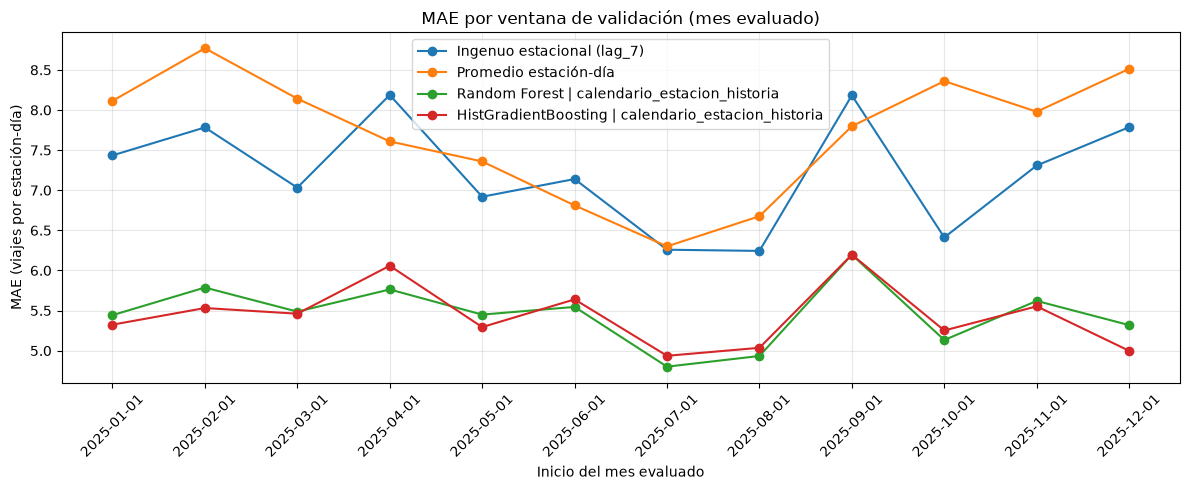

In [447]:
fig, ax = plt.subplots(figsize=(12, 5))
models_to_plot = [
    "Ingenuo estacional (lag_7)",
    "Promedio estación-día",
    f"Random Forest | {main_feature_set}",
    f"HistGradientBoosting | {main_feature_set}"
]
for model_name in models_to_plot:
    results = all_results.loc[all_results["model"] == model_name]
    ax.plot(results["cutoff"].astype(str), results["mae"], marker="o", label=model_name)
ax.set_title("MAE por ventana de validación (mes evaluado)")
ax.set_xlabel("Inicio del mes evaluado")
ax.set_ylabel("MAE (viajes por estación-día)")
ax.tick_params(axis="x", rotation=45)
ax.grid(alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

**Interpretación de la comparación (promedio de las 12 ventanas de 2025):**

| Modelo | MAE | Desv. estándar | Mejora sobre el ingenuo |
|---|---|---|---|
| HistGradientBoosting con historia | 5.44 | 0.39 | 24 % |
| Random Forest con historia | 5.46 | 0.38 | 24 % |
| Ingenuo estacional (`lag_7`) | 7.22 | 0.69 | — |
| Promedio estación-día | 7.70 | 0.78 | −7 % |
| Promedio global por día (versión anterior) | 22.99 | 0.69 | −221 % |

- **Los dos modelos superan a la línea base pertinente.** Reducen el error de 7.22 a cerca de 5.45 viajes por estación-día, una mejora de 24 %, y su error varía menos de un mes a otro (desviación de 0.38 a 0.39 contra 0.69 del ingenuo).
- **La historia de la demanda es lo que hace útil al modelo.** En la comparación de conjuntos de variables (sección 11.8, ejecución anterior), los modelos sin rezagos fueron peores que el ingenuo: Random Forest 7.83 y HistGradientBoosting 8.81. Parecían buenos en la versión anterior solo porque se comparaban contra el promedio global.
- **Random Forest e HistGradientBoosting están empatados.** La diferencia (5.44 contra 5.46) es mucho menor que la variación entre ventanas, así que no permite decir que uno sea mejor. La elección del modelo final se explica en la sección 11.13.
- **La tabla de tratamiento de variables mejoró poco el resultado:** Random Forest pasó de 5.49 a 5.46 al agregar `Origen_Id` con Target Encoding, el día del mes y el One-Hot de las variables categóricas.
- **Lo que significa para la operación:** con una demanda media de unos 34 viajes por estación-día, un error de 5.5 viajes permite anticipar qué estaciones tendrán más o menos salidas que de costumbre, que es lo que necesita el equipo para planear la redistribución.

### 11.10 Clima observado como comparación retrospectiva
Entrenamos el modelo con menor MAE en la comparación con parámetros iniciales (11.9), usando el conjunto principal más la temperatura y la precipitación observadas. Este "mejor modelo" solo se usa para esta prueba; el modelo final se elige en la sección 11.13.

Es una comparación retrospectiva: usa el clima que realmente ocurrió, que no se conoce al momento de predecir. Por eso no se usa para seleccionar el modelo. Tampoco indica cuánto aportaría un pronóstico: un modelo entrenado con pronósticos, que tienen error, puede comportarse de forma distinta. Para medirlo habría que repetir la prueba con pronósticos históricos.

En la ejecución anterior (antes de la tabla de tratamiento de variables) el clima observado no mejoró el error: MAE 5.49 sin clima y 5.50 con clima. Por eso este paso está apagado por defecto (`RUN_WEATHER_REFERENCE`).

In [448]:
main_models = model_comparison.loc[model_comparison.index.str.endswith(f"| {main_feature_set}")]
selected_model_name = main_models.index[0].split(" | ")[0]
print(f"Mejor modelo con el conjunto principal: {selected_model_name}")

if RUN_WEATHER_REFERENCE:
    weather_columns_set = feature_sets["historia_y_clima_observado"]
    weather_results = evaluate_walk_forward(
        build_model_pipeline(make_model(selected_model_name), weather_columns_set),
        weather_columns_set,
        f"{selected_model_name} | historia_y_clima_observado"
    )
    display(pd.DataFrame({
        "sin clima": all_results.loc[
            all_results["model"] == f"{selected_model_name} | {main_feature_set}", ["mae", "rmse"]
        ].mean(),
        "con clima observado (referencia)": weather_results[["mae", "rmse"]].mean()
    }).round(3))
else:
    print("Referencia omitida (RUN_WEATHER_REFERENCE = False).")
    print("Ejecución del 3 de noviembre, Random Forest: MAE 5.49 sin clima y 5.50 con clima observado.")

Mejor modelo con el conjunto principal: HistGradientBoosting
Referencia omitida (RUN_WEATHER_REFERENCE = False).
Ejecución del 3 de noviembre, Random Forest: MAE 5.49 sin clima y 5.50 con clima observado.


**Interpretación del clima observado (ejecución anterior, antes de la tabla de tratamiento de variables):** agregar la temperatura media y la precipitación acumulada del mismo día no mejoró el modelo. El MAE pasó de 5.49 a 5.50 y el RMSE de 8.84 a 8.87, diferencias de menos de 1 % y menores que la variación entre ventanas.

Este resultado es retrospectivo: compara el modelo con y sin el clima que realmente ocurrió. No es una estimación de lo que aportaría un pronóstico, que podría dar un resultado distinto. Hay tres razones probables por las que el clima observado no ayudó:
- Los rezagos y promedios móviles ya reflejan la temporada (por ejemplo, la demanda más baja en la época de lluvias).
- En el EDA, la lluvia solo baja la demanda de forma marcada con más de 20 mm (de 34.7 a 28.7 viajes), y eso pasa en cerca de 1 % de los registros.
- El clima se asigna por zona (8 zonas), así que es igual para muchas estaciones el mismo día y aporta poca información adicional.

Por eso el modelo principal no usa clima. Si en una fase posterior se consiguen pronósticos históricos, se puede repetir la prueba con ellos.

### 11.11 Ajuste de hiperparámetros con validación cruzada temporal
Utilizamos `GridSearchCV` con el walk-forward y el conjunto principal de variables, para los dos modelos. El criterio es el MAE promedio de las ventanas; los datos de 2026 no participan.

**Tiempo de ejecución.** Cada combinación se entrena una vez por ventana. Con 12 ventanas, la rejilla de Random Forest (8 combinaciones) son 96 entrenamientos y la de HistGradientBoosting (16 combinaciones) son 192, cerca de una hora en total. Para reducirlo:

- La búsqueda usa una de cada dos ventanas (6 cortes: enero, marzo, mayo, julio, septiembre y noviembre). La evaluación final del modelo elegido sí usa las 12.
- Random Forest usa `max_samples=0.5`.
- La celda solo corre si `RUN_GRID_SEARCH = True`. Con `False` se usan los parámetros guardados en `BEST_PARAMS` (11.1), que vienen de la última búsqueda completa. Las rejillas se quedan en el notebook como evidencia de lo que se probó.

In [449]:
parameter_grids = {
    "Random Forest": [
        {
            "model__n_estimators": [150],
            "model__max_depth": [12, 15, 18],
            "model__min_samples_leaf": [5],
            "model__max_features": [0.7, 1.0]
        },
        {
            "model__n_estimators": [150],
            "model__max_depth": [15],
            "model__min_samples_leaf": [3, 8],
            "model__max_features": [0.7]
        }
    ],
    "HistGradientBoosting": {
        "model__learning_rate": [0.05, 0.1],
        "model__max_iter": [200, 400],
        "model__max_leaf_nodes": [31, 63],
        "model__loss": ["squared_error", "poisson"]
    }
}
tuning_splits = cross_validation_splits[::2]     # 6 de las 12 ventanas

grid_searches = {}
if RUN_GRID_SEARCH:
    for model_name, grid in parameter_grids.items():
        search = GridSearchCV(
            estimator=build_model_pipeline(make_model(model_name), feature_columns),
            param_grid=grid,
            scoring={"mae": "neg_mean_absolute_error", "rmse": "neg_root_mean_squared_error"},
            refit=False,
            cv=tuning_splits,
            n_jobs=1,
            verbose=1
        )
        search.fit(development_data[feature_columns], development_data[target_column])
        grid_searches[model_name] = search
else:
    print("Búsqueda omitida (RUN_GRID_SEARCH = False). Parámetros guardados:")
    for model_name, params in BEST_PARAMS.items():
        print(f"  {model_name}: {params}")

Búsqueda omitida (RUN_GRID_SEARCH = False). Parámetros guardados:
  Random Forest: {'n_estimators': 150, 'max_depth': 15, 'min_samples_leaf': 5, 'max_features': 0.7}
  HistGradientBoosting: {'learning_rate': 0.1, 'max_iter': 200, 'max_leaf_nodes': 31, 'loss': 'poisson'}


### 11.12 Comparación de configuraciones
Ordenamos las combinaciones por MAE promedio y comparamos la mejor de cada modelo con su configuración inicial.

In [450]:
if grid_searches:
    tuning_tables = []
    for model_name, search in grid_searches.items():
        results = pd.DataFrame(search.cv_results_)
        results["model"] = model_name
        results["mae"] = -results["mean_test_mae"]
        results["mae_std"] = results["std_test_mae"]
        results["rmse"] = -results["mean_test_rmse"]
        tuning_tables.append(results[["model", "params", "mae", "mae_std", "rmse"]])
    tuning_comparison = pd.concat(tuning_tables, ignore_index=True).sort_values("mae")
    display(tuning_comparison.head(10))

    print("Copiar en BEST_PARAMS (11.1):")
    for model_name, group in tuning_comparison.groupby("model"):
        best = group.iloc[0]["params"]
        print(f'    "{model_name}": {{{", ".join(f"{k.replace("model__", "")!r}: {v!r}" for k, v in best.items())}}},')
else:
    print("Sin búsqueda en esta ejecución; se usan los parámetros de BEST_PARAMS.")

Sin búsqueda en esta ejecución; se usan los parámetros de BEST_PARAMS.


### 11.13 Entrenamiento final y evaluación única en 2026
Seleccionamos **una sola vez** el modelo y la configuración final con la validación de 2025. Lo entrenamos con todo `development_data` (2020–2025) y evaluamos `test_data` (enero–septiembre de 2026), junto con la línea base ingenua en las mismas filas. Los resultados de 2026 no se usan para cambiar el modelo ni sus parámetros.

**Por qué Random Forest:** con parámetros iniciales, Random Forest e HistGradientBoosting quedaron empatados (MAE 5.46 y 5.44, sección 11.9). Elegimos Random Forest porque es el único con hiperparámetros ajustados por búsqueda: la configuración de `BEST_PARAMS` viene de la búsqueda de la versión anterior, y en las 12 ventanas de 2025 obtiene MAE 5.44, igual que HistGradientBoosting sin ajustar. Si en una búsqueda completa (11.11) HistGradientBoosting mejora de forma clara, se cambia `FINAL_MODEL` y se vuelve a ejecutar esta sección.

Como en 2026 aparecen muchas estaciones que no existen en el desarrollo, reportamos el error por separado para estaciones con historia y estaciones nuevas.

#### Validación del modelo final en las 12 ventanas
Antes de evaluar 2026, comprobamos el modelo con los parámetros elegidos en las 12 ventanas de 2025 y lo comparamos con el ingenuo estacional.

In [451]:
chosen_model = FINAL_MODEL if not grid_searches else tuning_comparison.iloc[0]["model"]
chosen_params = (
    BEST_PARAMS[chosen_model] if not grid_searches
    else {k.replace("model__", ""): v for k, v in tuning_comparison.iloc[0]["params"].items()}
)
final_walk_forward = evaluate_walk_forward(
    build_model_pipeline(make_model(chosen_model, chosen_params), feature_columns),
    feature_columns,
    f"{chosen_model} | ajustado"
)
final_walk_forward["skill_vs_naive"] = 1 - final_walk_forward["mae"] / final_walk_forward["cutoff"].map(naive_mae)
display(final_walk_forward.round(3))
print(f"MAE promedio: {final_walk_forward['mae'].mean():.3f} (ingenuo estacional: {naive_mae.mean():.3f})")

/home/josel/mlops/equipo-8-mibici-mlops/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
/home/josel/mlops/equipo-8-mibici-mlops/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(
/home/josel/mlops/equipo-8-mibici-mlops/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.

,cutoff,model,mae,rmse,skill_vs_naive
0,2025-01-01,Random Forest | ajustado,5.439,8.322,0.268
1,2025-02-01,Random Forest | ajustado,5.760,9.476,0.260
2,2025-03-01,Random Forest | ajustado,5.458,8.376,0.224
3,2025-04-01,Random Forest | ajustado,5.755,8.939,0.297
4,2025-05-01,Random Forest | ajustado,5.438,8.395,0.214
5,2025-06-01,Random Forest | ajustado,5.538,8.328,0.224
6,2025-07-01,Random Forest | ajustado,4.785,7.201,0.235
7,2025-08-01,Random Forest | ajustado,4.916,7.268,0.213
8,2025-09-01,Random Forest | ajustado,6.152,12.254,0.248
9,2025-10-01,Random Forest | ajustado,5.107,7.616,0.204


MAE promedio: 5.438 (ingenuo estacional: 7.224)


In [452]:
if grid_searches:
    best_configuration = tuning_comparison.iloc[0]
    final_model_name = best_configuration["model"]
    final_params = {key.replace("model__", ""): value for key, value in best_configuration["params"].items()}
else:
    final_model_name = FINAL_MODEL
    final_params = BEST_PARAMS[FINAL_MODEL]
print(f"Modelo seleccionado: {final_model_name}")
print(f"Hiperparámetros: {final_params}")

final_pipeline = build_model_pipeline(make_model(final_model_name, final_params), feature_columns)
final_pipeline.fit(development_data[feature_columns], development_data[target_column])
final_predictions = final_pipeline.predict(test_data[feature_columns])
naive_predictions = predict_seasonal_naive(development_data, test_data)

known_stations = set(development_data["Origen_Id"])
test_segment = np.where(test_data["Origen_Id"].isin(known_stations), "Con historia", "Nueva")

final_rows = []
for segment in ["Todas", "Con historia", "Nueva"]:
    mask = np.ones(len(test_data), dtype=bool) if segment == "Todas" else test_segment == segment
    if not mask.any():
        continue
    y_true = test_data.loc[mask, target_column]
    model_metrics = regression_metrics(y_true, final_predictions[mask])
    naive_metrics = regression_metrics(y_true, naive_predictions[mask])
    final_rows.append({
        "stations": segment,
        "rows": int(mask.sum()),
        "model_mae": model_metrics["mae"],
        "model_rmse": model_metrics["rmse"],
        "naive_mae": naive_metrics["mae"],
        "skill_vs_naive": 1 - model_metrics["mae"] / naive_metrics["mae"]
    })
final_results = pd.DataFrame(final_rows)
display(final_results.round(3))

Modelo seleccionado: Random Forest
Hiperparámetros: {'n_estimators': 150, 'max_depth': 15, 'min_samples_leaf': 5, 'max_features': 0.7}


/home/josel/mlops/equipo-8-mibici-mlops/.venv/lib/python3.13/site-packages/sklearn/preprocessing/_target_encoder.py:342: FutureWarning: `TargetEncoder.shuffle` and `TargetEncoder.random_state` are deprecated in version 1.9 and will be removed in version 1.11. Pass a cross-validation generator as `cv` argument to specify the shuffling behaviour instead.
  warnings.warn(


,stations,rows,model_mae,model_rmse,naive_mae,skill_vs_naive
0,Todas,108294,5.896,10.782,7.957,0.259
1,Con historia,99487,6.108,11.142,8.101,0.246
2,Nueva,8807,3.511,5.206,6.330,0.445


**Interpretación del modelo final:**

*Validación 2025 (12 ventanas).* Random Forest con los parámetros elegidos obtiene un MAE promedio de 5.44 contra 7.22 del ingenuo estacional. Supera al ingenuo en **todos** los meses, con mejoras de entre 20 % y 32 %, así que el resultado no depende de un periodo favorable. El mes con más error es septiembre (MAE 6.15, RMSE 12.25, contra 7 a 10 en los demás meses): el RMSE alto indica algunos errores muy grandes en días o estaciones puntuales, probablemente por días atípicos como el 16 de septiembre. Conviene revisarlos en una fase posterior.

*Prueba 2026 (enero–septiembre, una sola evaluación).*

| Estaciones | Filas | MAE modelo | MAE ingenuo | Mejora |
|---|---|---|---|---|
| Todas | 108,294 | 5.90 | 7.96 | 26 % |
| Con historia | 99,487 | 6.11 | 8.10 | 25 % |
| Nuevas | 8,807 | 3.51 | 6.33 | 45 % |

- El MAE de 2026 (5.90) es mayor que el de la validación (5.44), pero el ingenuo también sube (de 7.22 a 7.96). La mejora relativa se mantiene en 25 % a 26 %, lo que indica que el modelo no se sobreajustó a 2025 y que 2026 es un periodo más difícil de predecir en general.
- En las estaciones nuevas el MAE es menor porque tienen poca demanda, no necesariamente porque el modelo las prediga mejor. Lo importante es que también ahí supera al ingenuo: con poca historia, la codificación de la estación y los conteos de POI le dan al modelo una referencia que el ingenuo no tiene.
- Para el uso previsto, el modelo predice las salidas del día siguiente por estación con un error medio de unos 6 viajes, una cuarta parte menos que la regla de repetir la semana anterior.

**Correspondencia de las cifras.** El MAE de 5.44 (12 ventanas de 2025) y el de 5.90 (prueba 2026) vienen de esta ejecución, con el pipeline actual (Target Encoding de la estación, One-Hot de día de la semana, mes y zona, día del mes y rezagos) y los parámetros de Random Forest de `BEST_PARAMS`: 150 árboles, profundidad máxima 15, hoja mínima 5 y 70 % de variables por división. Esos parámetros se eligieron con la búsqueda de la versión anterior (ventanas anuales y sin la tabla de tratamiento) y no se han vuelto a buscar con el pipeline actual. Repetir la búsqueda (`RUN_GRID_SEARCH = True`) podría mejorar ligeramente el resultado, sobre todo para HistGradientBoosting.

### 11.14 Ejemplos de predicciones de 2026
Mostramos algunos registros con la fecha, estación, viajes reales, predicción del modelo y de la línea base ingenua.

In [453]:
prediction_review = test_data[["Fecha", "Origen_Id", target_column]].copy()
prediction_review["predicted_trips"] = final_predictions
prediction_review["naive_prediction"] = naive_predictions.to_numpy()
prediction_review["absolute_error"] = (
    prediction_review[target_column] - prediction_review["predicted_trips"]
).abs()
prediction_review["segment"] = test_segment
display(prediction_review.head(50))

,Fecha,Origen_Id,target,predicted_trips,naive_prediction,absolute_error,segment
0,2026-01-01,2,9,18.019040,15.0,9.019040,Con historia
1,2026-01-02,2,32,33.478355,29.0,1.478355,Con historia
2,2026-01-03,2,34,34.640501,29.0,0.640501,Con historia
3,2026-01-04,2,26,25.683563,23.0,0.316437,Con historia
4,2026-01-05,2,55,41.061949,43.0,13.938051,Con historia
5,2026-01-06,2,36,49.546515,33.0,13.546515,Con historia
6,2026-01-07,2,45,41.426162,34.0,3.573838,Con historia
7,2026-01-08,2,58,45.514154,9.0,12.485846,Con historia
8,2026-01-09,2,61,49.339631,32.0,11.660369,Con historia
9,2026-01-10,2,42,37.354381,34.0,4.645619,Con historia


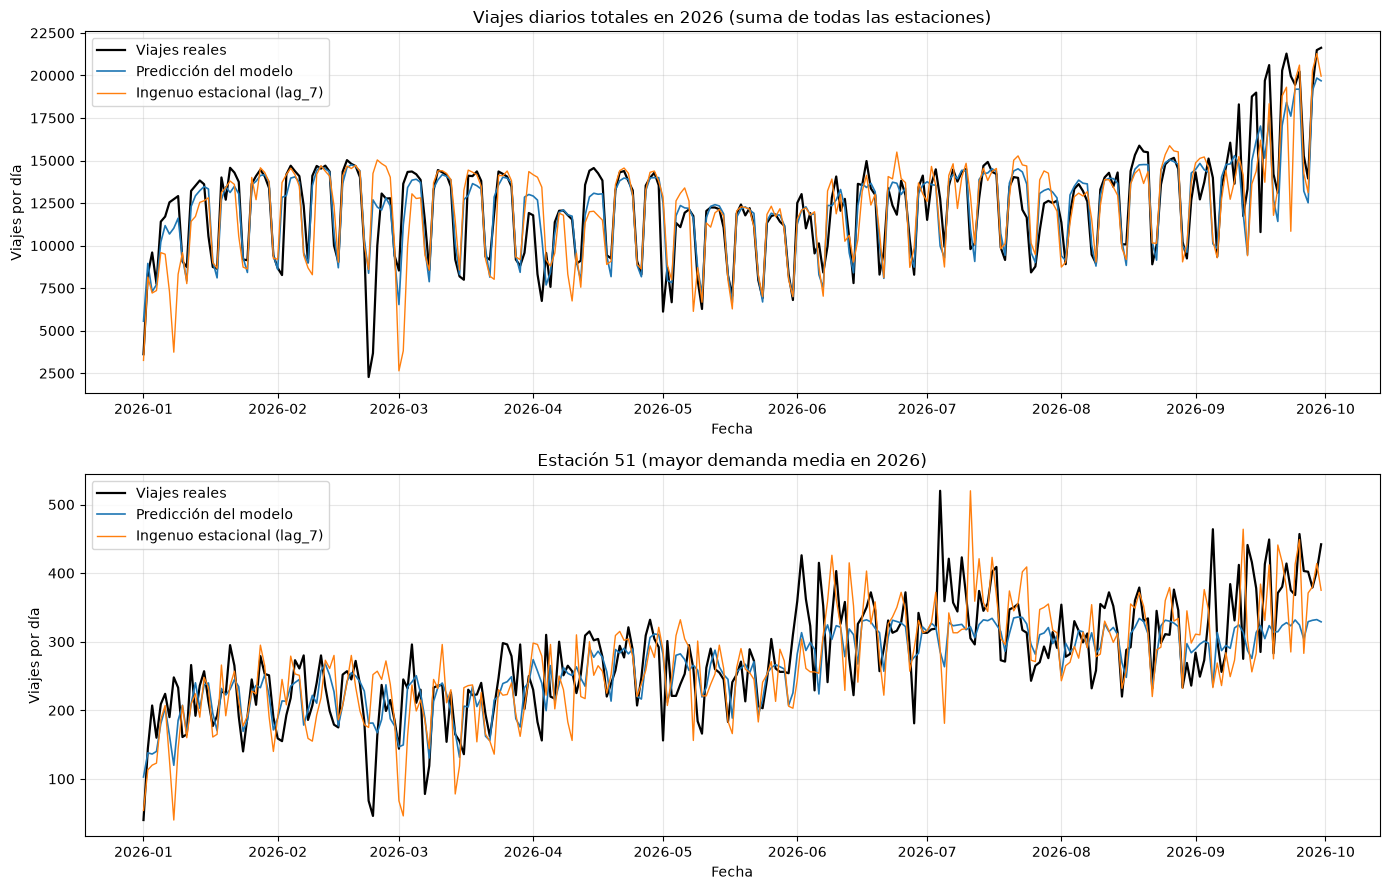

In [454]:
daily_totals = (
    prediction_review.groupby("Fecha")[[target_column, "predicted_trips", "naive_prediction"]]
    .sum()
)
example_station = (
    prediction_review.loc[prediction_review["segment"] == "Con historia"]
    .groupby("Origen_Id")[target_column].mean().idxmax()
)
station_series = (
    prediction_review.loc[prediction_review["Origen_Id"] == example_station]
    .set_index("Fecha")[[target_column, "predicted_trips", "naive_prediction"]]
)

fig, axes = plt.subplots(2, 1, figsize=(14, 9))
plot_series = [
    (target_column, "Viajes reales", "black", 1.6),
    ("predicted_trips", "Predicción del modelo", "tab:blue", 1.2),
    ("naive_prediction", "Ingenuo estacional (lag_7)", "tab:orange", 1.0)
]
for column, label, color, width in plot_series:
    axes[0].plot(daily_totals.index, daily_totals[column], label=label, color=color, linewidth=width)
    axes[1].plot(station_series.index, station_series[column], label=label, color=color, linewidth=width)
axes[0].set_title("Viajes diarios totales en 2026 (suma de todas las estaciones)")
axes[0].set_ylabel("Viajes por día")
axes[1].set_title(f"Estación {example_station} (mayor demanda media en 2026)")
axes[1].set_ylabel("Viajes por día")
for ax in axes:
    ax.set_xlabel("Fecha")
    ax.grid(alpha=0.3)
    ax.legend()
plt.tight_layout()
plt.show()

**Hipótesis: el Mundial 2026.** En la estación 51, el modelo se queda corto entre junio y mediados de julio, con días de mucha más demanda de la esperada (como el pico de más de 500 viajes a inicios de julio). Ese periodo coincide con el FIFA Fan Festival (11 de junio al 19 de julio) en Plaza Liberación, en el centro de Guadalajara. El modelo no podía anticiparlo porque no tiene variables de eventos; una mejora sería agregar una que marque los días de eventos grandes.

### 11.15 Justificación de la estrategia de validación

**Ventajas**
- Cada ventana usa solo información que habría existido en la fecha de corte, así que no hay fuga de datos futuros.
- El periodo evaluado es el mes inmediatamente posterior al corte, igual que en la operación real.
- Promediar 12 ventanas muestra si el error es estable a lo largo del año y no solo en un periodo.

**Limitaciones**
- **Solo se valida en 2025.** Las 12 ventanas son los meses de 2025, porque 2026 se reserva para la prueba final y los años anteriores se usan para entrenar. El error de validación describe el desempeño en 2025, no necesariamente en otros años con condiciones distintas (por ejemplo, la pandemia).
- **Supone reentrenamiento mensual.** En cada ventana el modelo se vuelve a entrenar con todos los datos hasta el corte. Esto simula que en operación se reentrenaría cada mes; si se entrenara una sola vez y se usara durante un año, el error probablemente sería mayor.
- **Solo se evalúan días con viajes registrados.** Los datos provienen de registros de viajes, así que un día sin salidas en una estación no aparece como 0, simplemente no existe. El modelo no se evalúa en esos días y el error real podría ser algo distinto.
- **Los POI son actuales.** Los conteos de escuelas, transporte y comercios corresponden a hoy, no al año evaluado. Si un lugar abrió o cerró, el modelo ve la zona como está actualmente, incluso para fechas pasadas.

- **Supone datos actualizados cada día.** Los rezagos usan los viajes reales del día anterior, también dentro del mes evaluado. Si MiBici publicara los datos con retraso (por ejemplo, una vez al mes), habría que usar un horizonte mayor (`HORIZON_DAYS`) y rezagos más largos, y el error sería mayor.

**Prueba final**
- 2026 se evalúa una sola vez con el modelo ya elegido, para obtener una estimación sin sesgo de selección.

### Uso IA:
- **OpenAI. (2026). *ChatGPT*.** Utilizado como apoyo para organizar la estructura del notebook, revisar la redacción, mejorar las convenciones de nombres de variables y funciones, y desarrollar y revisar algunas secciones de código relacionadas con el procesamiento de datos, los pipelines de Scikit-Learn y la validación temporal.
  https://chatgpt.com/